## eTOF spectroscopy and beamtime diagnostics — one selected run

Select `RUN_FILE` and an applicable `CALIB_PATH`. Ordinary spectroscopy uses compact
aggregate statistics, independently of the acquisition group. Optional GOTTHARD filtering
uses the existing shot-resolved path (see settings after calibration). Optional sections have
local switches; none of the shot diagnostics or maps run by default. Run configuration,
calibration and helper cells first, then only the sections needed. Plotting stays visible.
No experimental files are written and no aggregate/covariance products are regenerated.

Historical sources: `/home/mmanresa/glycine26`, branch
`cfg1-xas-tid-start-sections`, commit `b0508879511c191fad2f48df86da6f9e9e53e9ec`.
**Working-tree cells** are used where they differ from that commit, notably the requested
GMD cell 14 and bunch cells 11/13/17. All indices are **zero-based, including Markdown**.
Exact source hashes and adaptations are recorded at the end. The example run, calibration,
KE windows and GMD bands are historical configuration-1 inputs, not validated settings
for a different molecular target or acquisition. Confirm calibration applicability.


## 1. Configuration and data loading
Ranges are half-open unless explicitly described. `DELAY_SELECTION='integrate'` explicitly
integrates all stored delay bins; an integer selects one bin, and `(lo, hi)` selects whole
bins between exact `z_edges` in the stored stage coordinate. No partial-bin reconstruction.
Aggregate GMD cuts must also follow native edges. Arbitrary GMD/bunch cuts need shots.
The selected run's recorded `input_h5` is used only on demand if `SHOT_FILE=None`.


In [1]:
import os
import sys
import json
import re
from pathlib import Path
from types import SimpleNamespace
PROJECT_ROOT = Path('/home/mmanresa/FLASH_Gotthard').resolve()
sys.dont_write_bytecode = True
for cache in (PROJECT_ROOT / '.cache', PROJECT_ROOT / '.cache/matplotlib'):
    if not cache.resolve().is_relative_to(PROJECT_ROOT):
        raise ValueError(f'Cache path escapes project: {cache}')
os.environ['MPLCONFIGDIR'] = str(PROJECT_ROOT / '.cache/matplotlib')
os.environ['XDG_CACHE_HOME'] = str(PROJECT_ROOT / '.cache')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import h5py
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import TwoSlopeNorm
from historical import config
# Only the project's side-effect-free path config is imported; no historical modules.
print('Input root (read-only):', config.DATA_ROOT.resolve())
print('Project:', PROJECT_ROOT)


Input root (read-only): /asap3/flash/gpfs/fl24/2026/data/11022188
Project: /home/mmanresa/FLASH_Gotthard


In [2]:
# INPUT_ROOT contains read-only experimental inputs; all caches/outputs stay in PROJECT_ROOT.
INPUT_ROOT = Path(config.COMBINED_DIR)
RUN_FILE = INPUT_ROOT / 'glycine_delay_scan_150C_271.5eV_aggregates_tr_etof1.h5'
SHOT_FILE = None  # Explicit corresponding processed H5, or aggregate metadata input_h5.
CALIB_PATH = PROJECT_ROOT / 'products/calibrations/etof_energy_calibration_t0_scan.json'
BACKGROUND_FILE = None  # Required only when subtraction is enabled.
SUBTRACT_BACKGROUND = False
BACKGROUND_SCALE = 1.0
NORMALISE = 'per_uJ'  # 'raw', 'per_shot', 'per_uJ', 'electron_yield'
ELECTRON_YIELD_BASE = 'per_uJ'  # Exposure convention BEFORE subtraction and signed area normalisation.
X_AXIS = 'auto'  # 'auto': KE with calibration, otherwise TOF; alternatives 'KE', 'TOF'.
APPLY_JACOBIAN = True  # Divide by native calibrated KE width on KE plots only.
TOF_RANGE = (800, 1100)  # Inclusive bin-centre crop, in 100 ps ticks; (None,None): all.
KE_XLIM = (180, 280)     # Display limits only, eV; None: all.
KE_WINDOWS = [(190, 200), (200, 210), (210, 220), (220, 270)]
DELAY_SELECTION = 'integrate'  # Explicit selection for delay-resolved aggregate spectra.
AGG_GMD_RANGE = None  # None: all stored bins; otherwise exact native edge pair, uJ.
DETECTOR_KEY = 'tofs_e'
CHUNK_TRAINS = 200  # No whole hit-stack reads.
# Shot selections apply to shot paths, including FEL-filtered spectra; aggregates cannot recover bunch cuts.
SHOT_GMD_RANGE = (None, None)  # uJ, [lo,hi).
BUNCH_RANGE = (None, None)     # Original zero-based bunch indices [start,stop).
SHOT_MAX_TRAINS = None        # Optional first N source rows: preview, not full-run result.
SHOW_NORMALISATION_COMPARISON = False
# Optional spectrum overlay; does not affect other sections.
SPECTRUM_COMPARISON_FILE = None
SPECTRUM_COMPARISON_BACKGROUND = None

if NORMALISE not in ('raw', 'per_shot', 'per_uJ', 'electron_yield'):
    raise ValueError('Unknown NORMALISE')
if ELECTRON_YIELD_BASE not in ('raw', 'per_shot', 'per_uJ'):
    raise ValueError('Unknown ELECTRON_YIELD_BASE')
if CHUNK_TRAINS <= 0:
    raise ValueError('CHUNK_TRAINS must be positive')
for name in ('RUN_FILE', 'SHOT_FILE', 'CALIB_PATH', 'BACKGROUND_FILE'):
    value = globals()[name]
    print(name, Path(value).resolve() if value is not None else None)
print('Normalisation / axis / Jacobian:', NORMALISE, X_AXIS, APPLY_JACOBIAN)
print('Electron-yield base exposure:', ELECTRON_YIELD_BASE)
print('TOF crop / KE limits / KE windows:', TOF_RANGE, KE_XLIM, KE_WINDOWS)
print('Aggregate GMD / delay selection:', AGG_GMD_RANGE, DELAY_SELECTION)
print('Shot GMD / bunch range / max source rows:', SHOT_GMD_RANGE, BUNCH_RANGE, SHOT_MAX_TRAINS)
print('Background subtraction / multiplier:', SUBTRACT_BACKGROUND, BACKGROUND_SCALE)


RUN_FILE /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_271.5eV_aggregates_tr_etof1.h5
SHOT_FILE None
CALIB_PATH /home/mmanresa/FLASH_Gotthard/products/calibrations/etof_energy_calibration_t0_scan.json
BACKGROUND_FILE None
Normalisation / axis / Jacobian: per_uJ auto True
Electron-yield base exposure: per_uJ
TOF crop / KE limits / KE windows: (800, 1100) (180, 280) [(190, 200), (200, 210), (210, 220), (220, 270)]
Aggregate GMD / delay selection: None integrate
Shot GMD / bunch range / max source rows: (None, None) (None, None) None
Background subtraction / multiplier: False 1.0


### Saved calibration
Copied from existing notebook 05 and calibration II cell 41/residual-gas clean cell 2.
No fit is rerun. TOF-only operation needs no JSON; KE windows require calibration.
Native bins remain native bins: no shifts, interpolation or smoothing. The optional
Jacobian divides by `abs(diff(KE_edges))`, including unequal bin widths.


In [3]:
HAS_CALIBRATION = CALIB_PATH is not None
if not HAS_CALIBRATION:
    calibration = None
    print('TOF-only mode: no calibration loaded; KE windows and Jacobian are disabled.')
else:
    CALIB_PATH = Path(CALIB_PATH)
    if CALIB_PATH.is_dir():
        raise ValueError(f'CALIB_PATH points to a directory: {CALIB_PATH}. Set it to a calibration JSON file, or None for TOF-only analysis.')
    with CALIB_PATH.open("r", encoding="utf-8") as handle:
        calibration = json.load(handle)

    best_t0 = float(calibration["t0_tof_units"])
    best_slope = float(calibration["slope_eV_tof_unit2"])
    best_E0 = float(calibration["E0_eV"])


    def tof_to_ke(tof):
        tof = np.asarray(tof, dtype=float)
        with np.errstate(divide="ignore", invalid="ignore"):
            ke = best_slope / (tof - best_t0) ** 2 + best_E0
        return np.where(tof > best_t0, ke, np.nan)


    print("Calibration:", CALIB_PATH)
    print(f"t0={best_t0:.6f}, slope={best_slope:.6e}, E0={best_E0:.6f} eV")
    if calibration.get('detector_key', DETECTOR_KEY) != DETECTOR_KEY:
        raise ValueError('Calibration detector does not match selected detector')
    if float(calibration.get('tof_unit_seconds', np.nan)) != 100e-12:
        raise ValueError('This historical path expects 100 ps ticks; verify the calibration TOF units')
    print('Calibration validity:', calibration.get('validity_tof_ticks', 'not recorded; inspect source assignments'))
    print('Calibration source:', calibration.get('provenance', 'older JSON; verify instrument/acquisition applicability'))
if HAS_CALIBRATION and (not np.all(np.isfinite([best_t0, best_slope, best_E0])) or best_slope <= 0):
    raise ValueError('Invalid calibration parameters')
PLOT_AXIS = ('KE' if HAS_CALIBRATION else 'TOF') if X_AXIS == 'auto' else X_AXIS
if PLOT_AXIS not in ('KE', 'TOF') or (PLOT_AXIS == 'KE' and not HAS_CALIBRATION):
    raise ValueError('Choose TOF or supply a valid calibration for KE')
print('Display axis:', PLOT_AXIS)


Calibration: /home/mmanresa/FLASH_Gotthard/products/calibrations/etof_energy_calibration_t0_scan.json
t0=70.317117, slope=1.726561e+08, E0=-32.015747 eV
Calibration validity: [849.5, 1907.5]
Calibration source: {'branch': 'cfg1-xas-tid-start-sections', 'head': 'b0508879511c191fad2f48df86da6f9e9e53e9ec', 'notebook': 'analysis/post/etof_energy_calibration_II.ipynb', 'cells_zero_based': [19, 21, 23, 25, 39], 'source_state': 'working tree snapshot'}
Display axis: KE


### Optional GOTTHARD shot selection
Disabled by default. Enable only for a confirmed simultaneous acquisition and set its
export path and validated offset. `native_GMD_index = eTOF_bunch_index + offset`;
zero is the historical test convention, not a universal default. `/tID` float64 values
are checked to be exact integers. Matching uses run (where recorded), train ID and
native GMD index; absent source run metadata is reported and requires a single-run mask.
Unmatched shots are excluded and reported separately from matched rejections.

Main and GMD-conditioned electron spectra use shots when enabled. The common selection
also covers fine-GMD/response/bunch diagnostics and all ion spectra/bunch maps.
Base coverage is reported after train, delay, bunch and `SHOT_GMD_RANGE` cuts; plotted
bands/ion cuts may narrow it further. Main filtered spectra also respect `AGG_GMD_RANGE`.
Aggregate-only comparison/subtraction panels and photon/delay maps fail explicitly when
requested with filtering; the main spectrum retains its existing separately normalised
aggregate background reference. Reprepare shots after changing FEL settings. A second
acquisition needs its own mask/configuration in a separate analysis; never reuse an
unrelated run mask. No simultaneous GOTTHARD + usable TOF acquisition is yet validated.


In [ ]:
APPLY_FEL_MASK = False
FEL_MASK_FILE = None
FEL_SELECTION = 'reliable'  # 'valid', 'reliable', 'reliable_single', 'single', 'multiple', 'ambiguous'
ETOF_TO_GMD_BUNCH_OFFSET = None  # REQUIRED when enabled; explicitly set 0 for the historical convention.
print('FEL filtering:', APPLY_FEL_MASK, '| file:',
      Path(FEL_MASK_FILE).resolve() if FEL_MASK_FILE is not None else None,
      '| selection:', FEL_SELECTION, '| eTOF-to-native-GMD offset:', ETOF_TO_GMD_BUNCH_OFFSET)


### Lightweight loaders and native-bin reconstruction
Residual-gas clean cell 3 and delay-clean cells 5/14: `D` and `G` are bin means;
`n_per_bin` is shot population. Reconstruct **sums first**, then divide by total shots
or summed GMD. Supported axes: spectral `D[GMD,TOF]`; time-resolved
`D[GMD,z,TOF]`, `G/n[GMD,z]`. Other layouts fail explicitly. Keys, shapes, dtypes
and attributes are shown before reads; covariance matrices are omitted.


In [4]:
from dataclasses import dataclass, field
from typing import Optional

@dataclass
class AggregatesData:
    """
    Container for the binned aggregates produced by
    :func:`compute_aggregates`. All matrix fields are *means* over the
    shots that fell into each bin (empty bins give NaN).

    The shapes and which fields are populated depend on the
    experiment configuration (``config`` attribute in :attr:`metadata`):

    Config 2 — VLS + liquid-jet eTOF  (A, D, plus G aggregates):
        A    (N_GMD[, N_Z], n_pixels)
        AtA  (N_GMD[, N_Z], n_pixels, n_pixels)
        D    (N_GMD[, N_Z], n_tof)
        DtD  (N_GMD[, N_Z], n_tof, n_tof)
        AtD  (N_GMD[, N_Z], n_pixels, n_tof)
        AtG  (N_GMD[, N_Z], n_pixels)
        DtG  (N_GMD[, N_Z], n_tof)

    Config 1 — electron + ion TOF (D = eTOF, C = ion TOF):
        D    (N_GMD[, N_Z], n_tof)
        DtD  (N_GMD[, N_Z], n_tof, n_tof)
        C    (N_GMD[, N_Z], n_tof_i)
        CtC  (N_GMD[, N_Z], n_tof_i, n_tof_i)
        DtC  (N_GMD[, N_Z], n_tof, n_tof_i)
        DtG  (N_GMD[, N_Z], n_tof)
        CtG  (N_GMD[, N_Z], n_tof_i)

    Both configs always populate the GMD aggregates and bookkeeping:
        G          (per-bin mean GMD, scalar per bin)
        GtG        (per-bin mean GMD², for Var(G))
        n_per_bin  (shot counts per bin)
        gmd_edges, tof_edges, metadata

    Time-resolved mode: an extra ``N_Z`` axis is inserted before the
    per-shot dimensions and ``z_edges`` is populated.

    * Config 2: ``tof_edges`` collapses to ``[tof_roi_min, tof_roi_max]``
      (``n_tof = 1``) — the eTOF is reduced per shot to a scalar count.
    * Config 1: ``tof_edges`` and ``ion_tof_edges`` keep their full
      spectral resolution (just with an extra ``N_Z`` axis on every
      aggregate). No ``tof_roi`` is used.

    XAS-scan mode (config 2, written by ``compute_xas_aggregates.py``):
    bins are ``(N_E, N_GMD)`` indexed by per-section nominal photon
    energy and GMD. Only the VLS aggregates (``A``, ``AtA``, ``AtG``)
    and GMD aggregates (``G``, ``GtG``, ``n_per_bin``) are populated;
    eTOF fields (``D``, ``DtD``, ``DtG``, ``tof_edges``) are ``None``.
    ``nominal_energies`` carries the (N_E,) energy axis in eV.
    """
    # Bookkeeping (always present).
    G: np.ndarray
    GtG: np.ndarray
    n_per_bin: np.ndarray
    gmd_edges: np.ndarray
    # eTOF (spectral / time-resolved modes; None in xas_scan).
    D: Optional[np.ndarray] = None
    DtD: Optional[np.ndarray] = None
    DtG: Optional[np.ndarray] = None
    tof_edges: Optional[np.ndarray] = None
    # Config 2 only.
    A: Optional[np.ndarray] = None
    AtA: Optional[np.ndarray] = None
    AtD: Optional[np.ndarray] = None
    AtG: Optional[np.ndarray] = None
    vls_pixels: Optional[np.ndarray] = None
    background: Optional[np.ndarray] = None
    # Config 1 only.
    C: Optional[np.ndarray] = None
    CtC: Optional[np.ndarray] = None
    DtC: Optional[np.ndarray] = None
    CtG: Optional[np.ndarray] = None
    ion_tof_edges: Optional[np.ndarray] = None
    # TR mode (config 2).
    z_edges: Optional[np.ndarray] = None
    # XAS-scan mode (config 2).
    nominal_energies: Optional[np.ndarray] = None
    metadata: dict = field(default_factory=dict)

    @property
    def config(self) -> int:
        return int(self.metadata.get("config", 2))

    @property
    def mode(self) -> str:
        if self.nominal_energies is not None:
            return "xas_scan"
        if self.z_edges is not None:
            return "time_resolved"
        return "spectral"

    @property
    def n_gmd_bins(self) -> int:
        return int(self.gmd_edges.shape[0]) - 1

    @property
    def n_z_bins(self) -> Optional[int]:
        return None if self.z_edges is None else int(self.z_edges.shape[0]) - 1

    @property
    def n_energy_bins(self) -> Optional[int]:
        return None if self.nominal_energies is None else int(self.nominal_energies.shape[0])

    @property
    def n_pixels(self) -> Optional[int]:
        if self.vls_pixels is None:
            return None
        return int(self.vls_pixels.shape[0])

    @property
    def n_tof(self) -> Optional[int]:
        if self.tof_edges is None:
            return None
        return int(self.tof_edges.shape[0]) - 1

    @property
    def n_tof_i(self) -> Optional[int]:
        if self.ion_tof_edges is None:
            return None
        return int(self.ion_tof_edges.shape[0]) - 1

    @property
    def gmd_centres(self) -> np.ndarray:
        return 0.5 * (self.gmd_edges[:-1] + self.gmd_edges[1:])

    @property
    def z_centres(self) -> Optional[np.ndarray]:
        if self.z_edges is None:
            return None
        return 0.5 * (self.z_edges[:-1] + self.z_edges[1:])

    @property
    def tof_centres(self) -> Optional[np.ndarray]:
        if self.tof_edges is None:
            return None
        return 0.5 * (self.tof_edges[:-1] + self.tof_edges[1:])

    @property
    def ion_tof_centres(self) -> Optional[np.ndarray]:
        if self.ion_tof_edges is None:
            return None
        return 0.5 * (self.ion_tof_edges[:-1] + self.ion_tof_edges[1:])

    @property
    def var_G(self) -> np.ndarray:
        """Per-bin variance of G: ``<G²> − <G>²``. Useful for partial
        covariances against GMD."""
        return self.GtG - self.G ** 2


In [5]:
def inspect_input(path):
    path = Path(path)
    # Opening directly distinguishes PermissionError/OSError from missing-file errors.
    with h5py.File(path, "r") as f:
        print('Input:', path.resolve(), '| attributes:', dict(f.attrs))
        for key in ('D', 'G', 'n_per_bin', 'gmd_edges', 'tof_edges', 'z_edges',
                    'nominal_energies', 'gmd', 'tofs_e', 'z', 'between_tdc_files'):
            if key in f:
                d = f[key]
                print(' ', key, d.shape, d.dtype, '| attrs:', dict(d.attrs))


def load_aggregates_etof(path):
    inspect_input(path)
    with h5py.File(path, "r") as f:
        for key in ('D', 'G', 'n_per_bin', 'gmd_edges', 'tof_edges'):
            if key not in f:
                raise KeyError(f'{path}: required aggregate dataset /{key} is absent')
        if 'config' in f.attrs and int(f.attrs['config']) != 1:
            raise ValueError('This calibration/loader path supports configuration-1 gas eTOF only')
        if 'nominal_energies' in f:
            raise ValueError('Photon-energy-binned internal aggregate axis is not supported by these spectral loaders')
        # Preserve the historical containers and key names; no large moment matrices.
        a = AggregatesData(G=f['G'][:], GtG=None, n_per_bin=f['n_per_bin'][:],
            gmd_edges=f['gmd_edges'][:], D=f['D'][:], tof_edges=f['tof_edges'][:],
            z_edges=f['z_edges'][:] if 'z_edges' in f else None,
            metadata={k: v.decode() if isinstance(v, bytes) else v for k,v in f.attrs.items()})
    n = a.n_per_bin
    if a.D.ndim not in (2,3) or a.D.shape[:-1] != n.shape or a.G.shape != n.shape:
        raise ValueError(f'{path}: unsupported D/G/n axes: {a.D.shape}/{a.G.shape}/{n.shape}')
    if (a.D.ndim == 3) != (a.z_edges is not None):
        raise ValueError('Delay axis and z_edges must be present together')
    if len(a.gmd_edges) != n.shape[0]+1 or len(a.tof_edges) != a.D.shape[-1]+1:
        raise ValueError('Histogram edge lengths do not match axes')
    if a.z_edges is not None and len(a.z_edges) != n.shape[1]+1:
        raise ValueError('z_edges do not match delay dimension')
    for edges in (a.gmd_edges, a.tof_edges, a.z_edges):
        if edges is not None and (not np.all(np.isfinite(edges)) or np.any(np.diff(edges) <= 0)):
            raise ValueError('Histogram edges must be finite and strictly increasing')
    if np.any(~np.isfinite(n)) or np.any(n < 0) or np.any(n != np.floor(n)):
        raise ValueError('Invalid aggregate shot populations')
    occupied = n > 0
    if np.any(~np.isfinite(a.G[occupied])) or np.any(~np.isfinite(a.D[occupied])):
        raise ValueError('Nonfinite means in populated bins')
    print('Detected axes:', 'GMD,delay,TOF' if a.D.ndim == 3 else 'GMD,TOF',
          '| run metadata:', {k:v for k,v in a.metadata.items() if 'run' in k.lower()},
          '| populated / empty bins:', np.count_nonzero(occupied), np.count_nonzero(~occupied))
    return a


def edge_slice(edges, bounds, name):
    if bounds is None:
        return slice(None)
    indices = []
    for x in bounds:
        match = np.flatnonzero(np.isclose(edges, x, rtol=0, atol=1e-9))
        if len(match) != 1:
            raise ValueError(f'{name}: {x} must match one native edge; available edges: {edges}')
        indices.append(int(match[0]))
    if indices[0] >= indices[1]:
        raise ValueError(f'{name}: bounds must increase')
    return slice(*indices)


def delay_slice(a, selection):
    if a.z_edges is None:
        if selection != 'integrate':
            raise ValueError('Delay selection requested for aggregate with no delay axis')
        return None
    if selection == 'integrate':
        return slice(None)
    if isinstance(selection, int):
        if not 0 <= selection < len(a.z_edges)-1:
            raise IndexError('Delay-bin index outside stored axis')
        return slice(selection, selection+1)
    return edge_slice(a.z_edges, selection, 'delay/stage range')


def aggregate_stats(a, selection=DELAY_SELECTION, gmd_range=AGG_GMD_RANGE, keep_delay=False):
    gs = edge_slice(a.gmd_edges, gmd_range, 'aggregate GMD range')
    zs = delay_slice(a, selection)
    idx = (gs,) if zs is None else (gs,zs)
    n = np.asarray(a.n_per_bin[idx], float)
    D = np.asarray(a.D[idx], float)
    G = np.asarray(a.G[idx], float)
    # Empty bins may store NaN; populated bins were validated above.
    counts = np.where(n[...,None] > 0, D, 0) * n[...,None]
    exposure = np.where(n > 0, G, 0) * n
    axes = 0 if keep_delay and zs is not None else tuple(range(n.ndim))
    return dict(counts=counts.sum(axis=axes), sum_gmd=exposure.sum(axis=axes), shots=n.sum(axis=axes))


def normalised(stats, mode):
    if mode == 'electron_yield': mode = ELECTRON_YIELD_BASE
    denominator = {'raw': 1.0, 'per_shot': stats['shots'],
                   'per_uJ': stats['sum_gmd'], 'electron_yield': 1.0}[mode]
    denominator = np.asarray(denominator, float)
    with np.errstate(invalid='ignore', divide='ignore'):
        return stats['counts'] / np.where(denominator > 0, denominator, np.nan)[...,None]


def corrected_components(stats, background=None, mode=NORMALISE):
    signal = normalised(stats, mode)
    bg = np.zeros_like(signal)
    if background is not None:
        exposure_mode = ELECTRON_YIELD_BASE if mode == 'electron_yield' else mode
        if exposure_mode != 'raw':
            key = 'shots' if exposure_mode == 'per_shot' else 'sum_gmd'
            if np.any(~np.isfinite(background[key])) or np.any(np.asarray(background[key]) <= 0):
                raise ValueError(f'Invalid background {key} normalisation denominator')
        # Historical subtraction: separately exposure-normalise, scale background, subtract.
        # raw uses the existing raw-count subtraction; per-shot and per-uJ use their own exposures.
        bg = BACKGROUND_SCALE * normalised(background, mode)
    return signal, bg, signal-bg


def tof_crop_mask(edges):
    centres = .5*(edges[:-1]+edges[1:])
    mask = np.ones(len(centres), bool)
    if TOF_RANGE[0] is not None: mask &= centres >= TOF_RANGE[0]
    if TOF_RANGE[1] is not None: mask &= centres <= TOF_RANGE[1]
    if not mask.any(): raise ValueError('No native TOF bins in TOF_RANGE')
    return mask


def axis_data(edges, values, mode=NORMALISE):
    values = np.asarray(values, float).copy()
    mask = tof_crop_mask(edges)
    if mode == 'electron_yield':
        # Signed selected-TOF area, after subtraction; no absolute value or clipping.
        area = np.sum(values[...,mask], axis=-1)
        if np.any(~np.isfinite(area)) or np.any(area == 0):
            raise ValueError('Zero/nonfinite signed electron-yield denominator')
        values /= area[...,None]
    ii = np.flatnonzero(mask)
    edges = np.asarray(edges)[ii[0]:ii[-1]+2]
    values = values[...,ii[0]:ii[-1]+1]
    if PLOT_AXIS == 'KE':
        edges = tof_to_ke(edges)
        if not np.all(np.isfinite(edges)) or not np.all(np.diff(edges)<0):
            raise ValueError('TOF crop crosses calibration singularity or nonmonotonic KE bins')
        if APPLY_JACOBIAN: values /= np.abs(np.diff(edges))
        return edges[::-1], values[...,::-1]
    return edges, values


def spectrum_units(mode=NORMALISE):
    unit = {'raw':'summed counts', 'per_shot':'counts / shot', 'per_uJ':'counts / uJ',
            'electron_yield':'fraction of signed selected yield'}[mode]
    return unit + (' / eV' if PLOT_AXIS == 'KE' and APPLY_JACOBIAN else ' / native bin')


def format_spectrum_axis(ax, mode=NORMALISE):
    ax.set_xlabel('electron kinetic energy (eV)' if PLOT_AXIS == 'KE' else 'TOF (100 ps ticks)')
    ax.set_ylabel(spectrum_units(mode))
    if PLOT_AXIS == 'KE' and KE_XLIM is not None: ax.set_xlim(KE_XLIM)
    ax.grid(alpha=.25)


def load_background_for(a, path):
    if path is None: raise ValueError('Subtraction enabled: supply the corresponding BACKGROUND_FILE')
    bg = load_aggregates_etof(path)
    if not np.array_equal(a.tof_edges, bg.tof_edges):
        raise ValueError('Signal/background TOF edges differ; no interpolation is applied')
    # Residual-gas population is all its stored delays, as in delay-clean cell 14.
    return aggregate_stats(bg, selection='integrate')


agg = load_aggregates_etof(RUN_FILE)
selected_stats = aggregate_stats(agg)
background_stats = load_background_for(agg, BACKGROUND_FILE) if SUBTRACT_BACKGROUND else None
print('Aggregate reference population (unfiltered):' if APPLY_FEL_MASK else 'Selected population:',
      selected_stats['shots'], 'shots;', selected_stats['sum_gmd'], 'uJ')
if agg.z_edges is not None:
    print('Explicit delay selection:', DELAY_SELECTION, '| stored stage edges:', agg.z_edges)


Input: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_271.5eV_aggregates_tr_etof1.h5 | attributes: {'chunk_size': np.int64(200), 'config': np.int64(1), 'config_path': 'analysis/configs/aggregates_config1_etof_binsize_1_tr.py', 'input_h5': '/asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_271.5eV.h5', 'mode': 'time_resolved', 'n_skipped_gmd_nan': np.int64(0), 'n_skipped_gmd_oor': np.int64(380), 'n_skipped_z_nan': np.int64(19089), 'n_skipped_z_oor': np.int64(101), 'trim_end': np.int64(3), 'trim_start': np.int64(3)}
  D (4, 53, 5000) float64 | attrs: {}
  G (4, 53) float64 | attrs: {}
  n_per_bin (4, 53) int64 | attrs: {}
  gmd_edges (5,) float64 | attrs: {}
  tof_edges (5001,) float64 | attrs: {}
  z_edges (54,) float64 | attrs: {}
Detected axes: GMD,delay,TOF | run metadata: {} | populated / empty bins: 212 0
Selected population: 1986597.0 shots; 8925622.073823929 uJ
Explicit delay selection: integrate | stored st

## Shot helper definitions — run once, no shot data read here
Only processed aligned `gmd[train,bunch]`, `tofs_e[train,bunch,hit_slot]` are supported.
`tofs_e>0` marks occupied hit slots. We retain source train indices and bunch slots;
shape compatibility alone does **not** prove acquisition synchronization. Confirm the
processed writer's identity/DAQ alignment for a new acquisition. FEL matching uses the explicit eTOF-to-native-GMD offset below; it never rolls arrays.
 Train trimming retains the historical `between_tdc_files` mask convention.

Shot diagnostics use `SHOT_GMD_RANGE`, `BUNCH_RANGE` and the selected aggregate's explicit
delay range (if present). They do not silently adopt aggregate GMD acceptance: fine-GMD
controls intentionally explore editable wider populations. No residual-gas subtraction is
applied to shot correlations. Source `input_h5` may be overridden explicitly by `SHOT_FILE`.
A bounded first-row preview is labelled whenever `SHOT_MAX_TRAINS` is set. Helpers stream
hit chunks; fine diagnostics retain only per-shot scalar arrays and bunch distributions
retain only GMD, never the full hit stack. Each diagnostic is independently gated.


In [6]:
def keep_mask_like_compute_aggregates_from_h5(handle, trim_start=0, trim_end=0):
    if "between_tdc_files" not in handle:
        return np.ones(handle["gmd"].shape[0], dtype=bool)

    between_tdc_files = handle["between_tdc_files"][:].astype(bool)
    good_positions = np.where(~between_tdc_files)[0]

    if trim_end > 0:
        good_positions = good_positions[trim_start:-trim_end]
    else:
        good_positions = good_positions[trim_start:]

    keep = np.zeros(between_tdc_files.shape[0], dtype=bool)
    keep[good_positions] = True
    return keep


# Identity matching uses native GMD indices, never flattened row positions.
def integer_ids(values, name):
    a = np.asarray(values)
    if a.dtype.kind not in 'iu':
        # Historical /tID is float64: accept only exact, finite integer values.
        if a.dtype.kind != 'f' or np.any(~np.isfinite(a)) or np.any(a != np.floor(a)) or np.any(np.abs(a) >= 2**53):
            raise ValueError(f'{name}: expected exact integer identities')
    if np.any(a < 0) or np.any(a >= np.iinfo(np.int64).max):
        raise ValueError(f'{name}: negative/out-of-range identity')
    return a.astype(np.int64)


def fel_identity_index(run, train, bunch, accepted):
    arrays = [integer_ids(v, k) for v,k in zip((run,train,bunch), ('run','train','native GMD bunch'))]
    accepted = np.asarray(accepted)
    if accepted.dtype.kind != 'b' or accepted.ndim != 1 or not accepted.size:
        raise ValueError('FEL selection must be a nonempty boolean vector')
    if any(v.shape != accepted.shape for v in arrays) or np.any(arrays[1] == 0):
        raise ValueError('Inconsistent FEL identity axes or zero train ID')
    keys = np.rec.fromarrays(arrays, names='run,train,bunch')
    order = np.argsort(keys)
    keys = keys[order]
    if np.any(keys[1:] == keys[:-1]):
        raise ValueError('Duplicate FEL (run, train, native GMD bunch) identities')
    return dict(keys=keys, accepted=accepted[order])


def load_fel_mask(path, selection, *, rows=slice(None)):
    """Read only identity/selection columns. rows is for bounded schema checks only."""
    if selection not in ('valid','reliable','reliable_single','single','multiple','ambiguous'):
        raise ValueError('Unknown FEL_SELECTION')
    with h5py.File(path, 'r') as f:
        if f.attrs.get('schema') != 'gotthard_shot_selection_v1' or not f.attrs.get('complete', False):
            raise ValueError('Need a complete notebook-03 gotthard_shot_selection_v1 export')
        provenance = json.loads(f['provenance/json'][()])
        s = f['shots']; shape = s['train_id'].shape
        field = selection if selection in ('valid','reliable','reliable_single') else 'classification'
        for key in ('run_id','train_id','gmd_bunch_index','alignment_ok',field):
            if s[key].shape != shape or len(shape) != 1:
                raise ValueError('Inconsistent FEL column axes: '+key)
        for key in ('run_id','train_id','gmd_bunch_index'):
            if s[key].dtype.kind not in 'iu': raise ValueError('FEL identity column must be integer: '+key)
        if s['alignment_ok'].dtype.kind != 'b' or not np.all(s['alignment_ok'][rows]):
            raise ValueError('FEL export contains unverified alignment')
        if field != 'classification' and s[field].dtype.kind != 'b':
            raise ValueError('FEL selection flag must be boolean')
        flag = s[field][rows]
        if field == 'classification':
            if np.any(~np.isin(flag, [b'single',b'multiple',b'ambiguous'])):
                raise ValueError('Unknown FEL classification label')
            flag = flag == selection.encode()
        index = fel_identity_index(s['run_id'][rows],s['train_id'][rows],s['gmd_bunch_index'][rows],flag)
    runs = np.unique(index['keys']['run'])
    recorded_run = provenance.get('source_attrs',{}).get('run_no')
    if recorded_run is not None and not np.array_equal(runs, [int(recorded_run)]):
        raise ValueError('FEL row runs disagree with export provenance')
    index.update(provenance=provenance, runs=runs)
    print('FEL mask:', Path(path).resolve(), '| selection:',selection,'| rows read:',len(index['keys']), '| runs:',runs)
    return index


def match_fel_shots(index, trains, n_bunch, offset, run=None):
    """Return int8 [train,bunch]: 1 accepted, 0 rejected, -1 unmatched; no wrap."""
    trains = integer_ids(trains, 'eTOF train')
    if trains.ndim != 1 or np.any(trains == 0) or len(np.unique(trains)) != len(trains):
        raise ValueError('Invalid or duplicate eTOF train IDs')
    if not isinstance(offset, (int,np.integer)) or isinstance(offset, (bool,np.bool_)):
        raise ValueError('Set ETOF_TO_GMD_BUNCH_OFFSET to a validated integer for this acquisition')
    runs = np.unique(index['keys']['run'])
    if run is None:
        if len(runs) != 1: raise ValueError('Source run identity required for multi-run mask')
        run = int(runs[0])
    if run not in runs: raise ValueError('eTOF acquisition/run does not match FEL mask')
    native = np.arange(n_bunch, dtype=np.int64) + int(offset)
    shape = (len(trains), n_bunch)
    query = np.rec.fromarrays([np.full(np.prod(shape),run,dtype=np.int64),
        np.repeat(trains,n_bunch),np.tile(native,len(trains))], names='run,train,bunch')
    keys = index['keys']; pos = np.searchsorted(keys, query)
    inside = pos < len(keys)
    matched = np.zeros(len(query),bool)
    matched[inside] = keys[pos[inside]] == query[inside]
    matched &= np.tile(native >= 0,len(trains))
    status = np.full(len(query),-1,np.int8)
    status[matched] = index['accepted'][pos[matched]].astype(np.int8)
    return status.reshape(shape)


def prepare_fel_matching(handle, a):
    if FEL_MASK_FILE is None: raise ValueError('Set FEL_MASK_FILE before enabling FEL filtering')
    index = load_fel_mask(FEL_MASK_FILE,FEL_SELECTION)
    # Compare recorded run/acquisition identities where both inputs provide them.
    run_values = []
    for attrs in (handle.attrs, a.metadata):
        for key in ('run_id','run_no','run_number'):
            if key in attrs:
                value = integer_ids([attrs[key]],key)
                if value.shape != (1,): raise ValueError('Need scalar source run metadata')
                run_values.append(int(value[0]))
    for key in ('run_id','run_no','run_number'):
        if key in handle:
            ds = handle[key]
            if ds.shape == ():
                values = np.asarray([ds[()]])
            elif ds.shape == (handle['gmd'].shape[0],):
                limit = handle['gmd'].shape[0] if SHOT_MAX_TRAINS is None else min(handle['gmd'].shape[0],SHOT_MAX_TRAINS)
                values = ds[:limit]
            else:
                raise ValueError('Expected scalar or per-train source run identity: '+key)
            run_values.extend(map(int,np.unique(integer_ids(values,key))))
    if len(set(run_values)) > 1: raise ValueError('Shot/aggregate run metadata disagree or multi-run source unsupported')
    mask_attrs = index['provenance'].get('source_attrs',{})
    for key in ('acquisition_id','experiment_id','proposal_id'):
        values = [str(attrs[key]) for attrs in (handle.attrs,a.metadata,mask_attrs) if key in attrs]
        if len(set(values)) > 1: raise ValueError('Acquisition metadata disagree: '+key)
    for attrs in (handle.attrs,a.metadata):
        if 'etof_to_gmd_bunch_offset' in attrs and attrs['etof_to_gmd_bunch_offset'] != ETOF_TO_GMD_BUNCH_OFFSET:
            raise ValueError('Configured eTOF-to-GMD offset disagrees with source metadata')
    names = [key for key in ('tID','train_id') if key in handle]
    if not names: raise KeyError('FEL matching needs /tID or /train_id, never source row numbers')
    nt,nb = handle['gmd'].shape
    limit = nt if SHOT_MAX_TRAINS is None else min(nt,SHOT_MAX_TRAINS)
    rows = keep_mask_like_compute_aggregates_from_h5(handle,
        trim_start=int(a.metadata.get('trim_start',0) or 0),trim_end=int(a.metadata.get('trim_end',0) or 0))[:limit]
    tids = None
    for key in names:
        if handle[key].shape != (nt,): raise ValueError('Expected one train identity per source row: '+key)
        values = handle[key][:limit]
        ids = integer_ids(values[rows],key)
        if np.any(ids == 0) or len(np.unique(ids)) != len(ids):
            raise ValueError('Invalid or duplicate selected source train IDs')
        if tids is not None and not np.array_equal(tids[rows],ids):
            raise ValueError('Source train identity columns disagree')
        tids = np.zeros(limit,np.int64); tids[rows] = ids
    run = run_values[0] if run_values else None
    # Validate the run and offset even for an empty preview.
    match_fel_shots(index, tids[rows][:1], nb, ETOF_TO_GMD_BUNCH_OFFSET, run)
    SHOT_CONTEXT.update(fel=index, train_ids=tids, run=run, offset=ETOF_TO_GMD_BUNCH_OFFSET)
    totals = np.zeros(3,np.int64)
    for start in range(0,limit,CHUNK_TRAINS):
        stop = min(start+CHUNK_TRAINS,limit); row_keep = rows[start:stop]
        g = selected_gmd(handle,start,stop,row_keep,apply_fel=False)
        status = match_fel_shots(index,tids[start:stop][row_keep],nb,ETOF_TO_GMD_BUNCH_OFFSET,run)
        valid = np.isfinite(g)
        totals += [np.count_nonzero(valid & (status == k)) for k in (1,0,-1)]
    accepted,rejected,unmatched = map(int,totals); total = int(totals.sum())
    print(f'FEL coverage of base shot selection: matched accepted={accepted:,}; matched rejected={rejected:,}; '
          f'unmatched (excluded)={unmatched:,}; matched={(accepted+rejected)/total:.1%}' if total else 'FEL coverage: no base shots')
    print('Native GMD index = eTOF bunch index +',ETOF_TO_GMD_BUNCH_OFFSET,
          '| run check:',run if run is not None else 'unavailable in eTOF metadata; matching unique export run + train ID')
    if accepted == 0: raise ValueError('No matched accepted FEL shots in the base selection')


In [7]:
SHOT_CONTEXT = None

def prepare_shots(a=agg, shot_file=None):
    global SHOT_CONTEXT
    raw = shot_file if shot_file is not None else a.metadata.get('input_h5')
    if not raw: raise ValueError('Set SHOT_FILE; aggregate has no recorded input_h5')
    path=Path(raw)
    if not path.is_absolute(): raise ValueError('Shot source must be an explicit absolute path')
    inspect_input(path)
    with h5py.File(path,'r') as f:
        if 'gmd' not in f or 'tofs_e' not in f: raise KeyError('Need /gmd and /tofs_e')
        if f['gmd'].ndim != 2 or f['tofs_e'].ndim != 3 or f['tofs_e'].shape[:2] != f['gmd'].shape:
            raise ValueError('Need aligned GMD[train,bunch], eTOF[train,bunch,hit_slot]')
        if a.z_edges is not None and ('z' not in f or f['z'].shape != f['gmd'].shape):
            raise ValueError('Delay aggregate requires aligned source /z')
        nt,nb=f['gmd'].shape
        lo=0 if BUNCH_RANGE[0] is None else BUNCH_RANGE[0]
        hi=nb if BUNCH_RANGE[1] is None else BUNCH_RANGE[1]
        if not 0 <= lo < hi <= nb: raise ValueError('BUNCH_RANGE outside source slots')
        if SHOT_MAX_TRAINS is not None and (not isinstance(SHOT_MAX_TRAINS,int) or SHOT_MAX_TRAINS <= 0):
            raise ValueError('SHOT_MAX_TRAINS must be positive or None')
    zs=delay_slice(a,DELAY_SELECTION)
    zrange=None if zs is None else (a.z_edges[0 if zs.start is None else zs.start],a.z_edges[-1 if zs.stop is None else zs.stop])
    SHOT_CONTEXT=dict(path=path,zrange=zrange,bunch=(lo,hi))
    print('Shot source:',path.resolve(),'| source rows:',nt,'| original bunch indices:',(lo,hi),
          '| z [lo,hi):',zrange,'| GMD:',SHOT_GMD_RANGE,
          '| preview source-row cap:',SHOT_MAX_TRAINS)
    print('Train trim:',a.metadata.get('trim_start',0),a.metadata.get('trim_end',0))
    if APPLY_FEL_MASK:
        with h5py.File(path, 'r') as f:
            prepare_fel_matching(f, a)
    return path


def selected_gmd(handle,start,stop,row_keep, *, apply_fel=True):
    # Selection adapter only; counting/binning formulas in copied helpers are preserved.
    if SHOT_CONTEXT is None: raise RuntimeError('Call prepare_shots for this source first')
    if Path(handle.filename).resolve() != SHOT_CONTEXT['path'].resolve():
        raise ValueError('Shot selection context belongs to another source')
    g=handle['gmd'][start:stop][row_keep].astype(float)
    keep=np.isfinite(g)
    lo,hi=SHOT_CONTEXT['bunch']
    keep[:,:lo]=False
    keep[:,hi:]=False
    for bound,lower in zip(SHOT_GMD_RANGE,(True,False)):
        if bound is not None: keep &= (g>=bound) if lower else (g<bound)
    if SHOT_MAX_TRAINS is not None:
        keep &= (np.arange(start,stop)[row_keep] < SHOT_MAX_TRAINS)[:,None]
    if SHOT_CONTEXT['zrange'] is not None:
        z=handle['z'][start:stop][row_keep]
        zlo,zhi=SHOT_CONTEXT['zrange']
        keep &= np.isfinite(z)&(z>=zlo)&(z<zhi)
    if APPLY_FEL_MASK and apply_fel:
        context = SHOT_CONTEXT
        if 'fel' not in context: raise RuntimeError('Rerun prepare_shots after enabling FEL filtering')
        status = match_fel_shots(context['fel'],context['train_ids'][start:stop][row_keep],
                                 g.shape[1],context['offset'],context['run'])
        keep &= status == 1  # Both matched rejection and unmatched shots are excluded.
    return np.where(keep,g,np.nan)


def trim_values(a=agg):
    return dict(trim_start=int(a.metadata.get('trim_start',0) or 0),
                trim_end=int(a.metadata.get('trim_end',0) or 0),chunk_trains=CHUNK_TRAINS)


In [8]:
def fine_ke_window_weights(tof_edges, ke_range):
    """Fractional overlap of every native TOF bin with a KE interval."""
    ke_edges = tof_to_ke(tof_edges)

    lo = np.minimum(ke_edges[:-1], ke_edges[1:])
    hi = np.maximum(ke_edges[:-1], ke_edges[1:])
    width = hi - lo

    overlap = np.maximum(
        0.0,
        np.minimum(hi, ke_range[1]) - np.maximum(lo, ke_range[0]),
    )

    weights = np.zeros_like(width, dtype=float)
    good = np.isfinite(lo) & np.isfinite(hi) & (width > 0)
    weights[good] = overlap[good] / width[good]

    return weights

def read_fine_gmd_diagnostics(
    source_h5,
    tof_edges,
    ke_ranges,
    *,
    trim_start=0,
    trim_end=0,
    chunk_trains=1000,
):
    """
    Read shot-resolved GMD, total hit counts, and KE-window hit counts.

    KE-window counts use the same fractional native-bin weighting as the
    integrated resonance traces.
    """
    gmd_chunks = []
    total_count_chunks = []
    counts_by_ke_chunks = {tuple(r): [] for r in ke_ranges}

    weights_by_range = {
        tuple(r): fine_ke_window_weights(tof_edges, tuple(r))
        for r in ke_ranges
    }

    with h5py.File(source_h5, "r") as handle:
        keep = keep_mask_like_compute_aggregates_from_h5(
            handle,
            trim_start=trim_start,
            trim_end=trim_end,
        )

        n_trains = handle["gmd"].shape[0] if SHOT_MAX_TRAINS is None else min(handle["gmd"].shape[0], SHOT_MAX_TRAINS)

        for start in range(0, n_trains, chunk_trains):
            stop = min(start + chunk_trains, n_trains)
            row_keep = keep[start:stop]

            if not row_keep.any():
                continue

            gmd = selected_gmd(handle, start, stop, row_keep)
            tofs = handle["tofs_e"][start:stop][row_keep]

            gmd_flat = gmd.ravel()
            tofs_flat = tofs.reshape(-1, tofs.shape[-1])
            valid_shot = np.isfinite(gmd_flat)

            # All stored positive eTOF hits, matching TOF_COUNT_RANGE=None.
            total_counts = np.count_nonzero(
                tofs_flat > 0,
                axis=1,
            ).astype(float)

            gmd_chunks.append(gmd_flat[valid_shot])
            total_count_chunks.append(total_counts[valid_shot])

            # Assign each detected hit to its native TOF bin.
            shot_ids = np.repeat(
                np.arange(tofs_flat.shape[0]),
                tofs_flat.shape[1],
            )
            tof_values = tofs_flat.ravel()

            valid_hit = np.isfinite(tof_values) & (tof_values > 0)
            hit_shot_ids = shot_ids[valid_hit]
            hit_tofs = tof_values[valid_hit]

            tof_bin = np.searchsorted(
                tof_edges,
                hit_tofs,
                side="right",
            ) - 1

            # Include a hit exactly on the final histogram edge.
            tof_bin[hit_tofs == tof_edges[-1]] = len(tof_edges) - 2

            inside_grid = (
                (tof_bin >= 0)
                & (tof_bin < len(tof_edges) - 1)
            )

            hit_shot_ids = hit_shot_ids[inside_grid]
            tof_bin = tof_bin[inside_grid]

            for ke_range in ke_ranges:
                key = tuple(ke_range)
                weights = weights_by_range[key]

                counts = np.bincount(
                    hit_shot_ids,
                    weights=weights[tof_bin],
                    minlength=tofs_flat.shape[0],
                )

                counts_by_ke_chunks[key].append(counts[valid_shot])

    if not gmd_chunks or not any(x.size for x in gmd_chunks):
        raise ValueError("No shots survive the explicit selection")
    gmd_shot = np.concatenate(gmd_chunks)
    total_counts_shot = np.concatenate(total_count_chunks)
    counts_by_ke = {
        key: np.concatenate(chunks)
        for key, chunks in counts_by_ke_chunks.items()
    }

    return gmd_shot, total_counts_shot, counts_by_ke

def fine_bin_mean_sem(gmd_values, observable, bin_edges):
    """Mean observable and empirical SEM in each GMD bin."""
    bin_id = np.digitize(gmd_values, bin_edges) - 1
    n_bins = len(bin_edges) - 1

    x_mean = np.full(n_bins, np.nan)
    y_mean = np.full(n_bins, np.nan)
    y_sem = np.full(n_bins, np.nan)
    n_shots = np.zeros(n_bins, dtype=int)

    valid = (
        np.isfinite(gmd_values)
        & np.isfinite(observable)
        & (bin_id >= 0)
        & (bin_id < n_bins)
    )

    for bin_index in range(n_bins):
        selected = valid & (bin_id == bin_index)
        n_shots[bin_index] = int(np.count_nonzero(selected))

        if n_shots[bin_index] == 0:
            continue

        x_mean[bin_index] = np.nanmean(gmd_values[selected])
        y_mean[bin_index] = np.nanmean(observable[selected])
        y_sem[bin_index] = (
            np.nanstd(observable[selected])
            / np.sqrt(n_shots[bin_index])
        )

    return x_mean, y_mean, y_sem, n_shots


In [9]:
def shot_resolved_gmd_spectrum(
    source_h5,
    gmd_range,
    tof_edges,
    *,
    trim_start=0,
    trim_end=0,
    chunk_trains=1000,
):
    """
    Build S(E) = sum N(E) / sum GMD directly from shot-resolved H5.

    Returns counts/uJ per original TOF bin.
    """
    gmd_lo, gmd_hi = gmd_range

    total_counts = np.zeros(len(tof_edges) - 1, dtype=np.float64)
    total_gmd = 0.0
    total_shots = 0
    total_hits = 0

    with h5py.File(source_h5, "r") as f:
        keep = keep_mask_like_compute_aggregates_from_h5(
            f,
            trim_start=trim_start,
            trim_end=trim_end,
        )

        n_trains = f["gmd"].shape[0] if SHOT_MAX_TRAINS is None else min(f["gmd"].shape[0], SHOT_MAX_TRAINS)
        max_slots = f["tofs_e"].shape[-1]
        saturated_shots = 0

        for s in range(0, n_trains, chunk_trains):
            e = min(s + chunk_trains, n_trains)
            row_keep = keep[s:e]

            if not row_keep.any():
                continue

            gmd = selected_gmd(f, s, e, row_keep)
            tofs = f["tofs_e"][s:e][row_keep]

            gmd_flat = gmd.ravel()
            tofs_flat = tofs.reshape(-1, tofs.shape[-1])

            shot_sel = (
                np.isfinite(gmd_flat)
                & (gmd_flat >= gmd_lo)
                & (gmd_flat < gmd_hi)
            )

            if not shot_sel.any():
                continue

            selected_tofs = tofs_flat[shot_sel]
            hits = selected_tofs.ravel()
            hits = hits[hits > 0]

            hist, _ = np.histogram(hits, bins=tof_edges)

            total_counts += hist.astype(np.float64)
            total_gmd += float(np.nansum(gmd_flat[shot_sel]))
            total_shots += int(np.count_nonzero(shot_sel))
            total_hits += int(hits.size)
            saturated_shots += int(np.count_nonzero(np.count_nonzero(selected_tofs > 0, axis=1) >= max_slots))

    with np.errstate(invalid="ignore", divide="ignore"):
        spectrum = total_counts / total_gmd

    spectrum[~np.isfinite(spectrum)] = np.nan

    return {
        "spectrum": spectrum,
        "counts": total_counts,
        "sum_gmd": total_gmd,
        "shots": total_shots,
        "hits": total_hits,
        "saturated_shots": saturated_shots,
        "gmd_range": gmd_range,
    }


In [10]:
def apply_cb_to_gmd(gmd, cb):
    '''Return effective normalisation GMD = GMD x Cb.'''
    gmd = np.asarray(gmd, dtype=float)

    if cb is None:
        return gmd

    cb = np.asarray(cb, dtype=float)

    if gmd.ndim != 2:
        raise ValueError(
            f"Expected GMD shape (train, bunch), found {gmd.shape}"
        )

    if gmd.shape[1] != cb.size:
        raise ValueError(
            f"GMD has {gmd.shape[1]} bunch positions but Cb has {cb.size}"
        )

    return gmd * cb[None, :]

def row_trim_values(row):
    if "trim_start" in row and "trim_end" in row:
        return int(row["trim_start"]), int(row["trim_end"])

    # Clean static notebook fallback.
    if "path" in row and "load_aggregates_etof" in globals():
        agg = load_aggregates_etof(row["path"])
        return (
            int(agg.metadata.get("trim_start", 0) or 0),
            int(agg.metadata.get("trim_end", 0) or 0),
        )

    return 0, 0

def ke_window_weights_for_tof_bins(tof_edges, ke_range):
    ke_edges = tof_to_ke(tof_edges)

    lo = np.minimum(ke_edges[:-1], ke_edges[1:])
    hi = np.maximum(ke_edges[:-1], ke_edges[1:])
    width = hi - lo

    overlap = np.maximum(
        0.0,
        np.minimum(hi, ke_range[1]) - np.maximum(lo, ke_range[0]),
    )

    weights = np.zeros_like(width, dtype=float)
    good = np.isfinite(lo) & np.isfinite(hi) & (width > 0)
    weights[good] = overlap[good] / width[good]

    return weights

def gmd_binned_ke_yield_for_row(
    row,
    gmd_edges,
    ke_range,
    *,
    tof_edges=None,
    chunk_trains=1000,
    require_valid_delay_if_present=True,
):
    source_h5 = Path(row["source_h5"])

    if tof_edges is None:
        raise ValueError('Supply the calibrated TOF bin edges explicitly')
    tof_edges = np.asarray(tof_edges, dtype=float)

    gmd_edges = np.asarray(gmd_edges, dtype=float)
    weights = ke_window_weights_for_tof_bins(tof_edges, ke_range)

    n_gmd = len(gmd_edges) - 1

    shots = np.zeros(n_gmd, dtype=np.int64)

    # Raw physical GMD.
    sum_gmd = np.zeros(n_gmd, dtype=float)

    # Corrected exposure Σ(G Cb).
    sum_norm = np.zeros(n_gmd, dtype=float)

    # Needed for the correct physical-GMD x coordinate: Σ[G (G Cb)].
    sum_gmd_x_norm = np.zeros(n_gmd, dtype=float)

    counts = np.zeros(n_gmd, dtype=float)
    count_variance = np.zeros(n_gmd, dtype=float)

    trim_start, trim_end = row_trim_values(row)

    use_delay = (
        require_valid_delay_if_present
        and ("z_edges" in row)
        and row["z_edges"] is not None
    )

    if use_delay:
        z_edges = np.asarray(row["z_edges"], dtype=float)
        n_delay = len(z_edges) - 1

    with h5py.File(source_h5, "r") as handle:
        keep = keep_mask_like_compute_aggregates_from_h5(
            handle,
            trim_start=trim_start,
            trim_end=trim_end,
        )

        n_trains = handle["gmd"].shape[0] if SHOT_MAX_TRAINS is None else min(handle["gmd"].shape[0], SHOT_MAX_TRAINS)

        for start in range(0, n_trains, chunk_trains):
            stop = min(start + chunk_trains, n_trains)
            row_keep = keep[start:stop]

            if not row_keep.any():
                continue

            gmd = selected_gmd(handle, start, stop, row_keep)
            tofs = handle["tofs_e"][start:stop][row_keep]
            gmd_norm = apply_cb_to_gmd(gmd, row.get("cb"))

            valid = np.isfinite(gmd) & np.isfinite(gmd_norm)

            if use_delay:
                z = handle["z"][start:stop][row_keep]
                delay_bin = (
                    np.searchsorted(z_edges, z, side="right") - 1
                )
                valid &= (
                    np.isfinite(z)
                    & (delay_bin >= 0)
                    & (delay_bin < n_delay)
                )

            gmd_flat = gmd.reshape(-1)
            gmd_norm_flat = gmd_norm.reshape(-1)
            tofs_flat = tofs.reshape(-1, tofs.shape[-1])
            valid_flat = valid.reshape(-1)

            # Bin assignment remains based on RAW GMD.
            gmd_bin = np.searchsorted(gmd_edges, gmd_flat, side="right") - 1

            for i in range(n_gmd):
                selected = valid_flat & (gmd_bin == i)

                if not selected.any():
                    continue

                gmd_in_bin = gmd_flat[selected]
                selected_norm = gmd_norm_flat[selected]

                hits = tofs_flat[selected].reshape(-1)
                hits = hits[np.isfinite(hits) & (hits > 0)]

                hist, _ = np.histogram(hits, bins=tof_edges)

                shots[i] += int(np.count_nonzero(selected))
                sum_gmd[i] += float(np.nansum(gmd_in_bin))
                sum_norm[i] += float(np.nansum(selected_norm))
                sum_gmd_x_norm[i] += float(np.nansum(gmd_in_bin * selected_norm))
                counts[i] += float(np.nansum(weights * hist))
                count_variance[i] += float(
                    np.nansum((weights**2) * hist)
                )

    with np.errstate(invalid="ignore", divide="ignore"):
        mean_gmd = sum_gmd / shots
        effective_gmd = sum_gmd_x_norm / sum_norm
        yield_per_shot = counts / shots
        yield_per_gmd = counts / sum_norm
        sigma_yield_per_gmd = np.sqrt(count_variance) / sum_norm

    good = (
        np.isfinite(effective_gmd)
        & np.isfinite(yield_per_gmd)
        & np.isfinite(sigma_yield_per_gmd)
        & (shots >= GMD_RESPONSE_MIN_SHOTS)
        & (sum_norm > 0)
        & (sigma_yield_per_gmd > 0)
    )

    return {
        "energy": row["energy"],
        "gmd_edges": gmd_edges,
        "mean_gmd": mean_gmd,
        "effective_gmd": effective_gmd,
        "shots": shots,
        "sum_gmd": sum_gmd,
        "sum_norm": sum_norm,
        "sum_gmd_x_norm": sum_gmd_x_norm,
        "counts": counts,
        "yield_per_shot": yield_per_shot,
        "yield_per_gmd": yield_per_gmd,
        "sigma_yield_per_gmd": sigma_yield_per_gmd,
        "good": good,
    }

def fit_yield_over_gmd_slope(diag):
    # This is the correct x coordinate after Cb normalisation.
    x = diag["effective_gmd"]
    y = diag["yield_per_gmd"]
    s = diag["sigma_yield_per_gmd"]
    good = diag["good"]

    if np.count_nonzero(good) < 3:
        return {
            "energy": diag["energy"],
            "a": np.nan,
            "b": np.nan,
            "sigma_a": np.nan,
            "sigma_b": np.nan,
            "n": int(np.count_nonzero(good)),
        }

    coeff, cov = np.polyfit(
        x[good],
        y[good],
        deg=1,
        w=1.0 / s[good],
        cov=True,
    )

    b, a = coeff
    sigma_b, sigma_a = np.sqrt(np.diag(cov))

    return {
        "energy": diag["energy"],
        "a": a,
        "b": b,
        "sigma_a": sigma_a,
        "sigma_b": sigma_b,
        "n": int(np.count_nonzero(good)),
    }


In [11]:
def delay_window_to_stage_window(delay_window_fs):
    if delay_window_fs is None:
        return None

    lo_fs, hi_fs = delay_window_fs
    lo_stage = lo_fs / FS_PER_STAGE_UNIT + DELAY_ZERO_STAGE
    hi_stage = hi_fs / FS_PER_STAGE_UNIT + DELAY_ZERO_STAGE

    return min(lo_stage, hi_stage), max(lo_stage, hi_stage)

def read_bunch_position_diagnostics(
    source_h5,
    ke_ranges,
    gmd_ranges,
    *,
    delay_window_fs=None,
    trim_start=0,
    trim_end=0,
    chunk_trains=1000,
):
    source_h5 = Path(source_h5)
    ke_ranges = [tuple(r) for r in ke_ranges]
    gmd_ranges = {name: tuple(value) for name, value in gmd_ranges.items()}
    delay_window_stage = delay_window_to_stage_window(delay_window_fs)

    with h5py.File(source_h5, "r") as handle:
        keep = keep_mask_like_compute_aggregates_from_h5(
            handle,
            trim_start=trim_start,
            trim_end=trim_end,
        )

        n_trains, n_bunch = handle["gmd"].shape
        if SHOT_MAX_TRAINS is not None: n_trains = min(n_trains, SHOT_MAX_TRAINS)
        max_slots = handle["tofs_e"].shape[-1]
        bunch = np.arange(n_bunch)

        gmd_kept = np.concatenate([
            selected_gmd(handle, s, min(s+chunk_trains,n_trains), keep[s:min(s+chunk_trains,n_trains)])
            for s in range(0,n_trains,chunk_trains)
        ],axis=0)

        if delay_window_stage is not None:
            if "z" not in handle:
                raise KeyError("Requested DELAY_WINDOW_FS, but source H5 has no /z dataset.")

            z_kept = handle["z"][:][keep]
            z_lo, z_hi = delay_window_stage
            delay_kept = np.isfinite(z_kept) & (z_kept >= z_lo) & (z_kept < z_hi)
            gmd_for_distribution = np.where(delay_kept, gmd_kept, np.nan)
        else:
            gmd_for_distribution = gmd_kept

        out = {
            "bunch": bunch,
            "gmd_kept": gmd_for_distribution,
            "max_slots": max_slots,
            "ke_ranges": ke_ranges,
            "gmd_ranges": gmd_ranges,
            "delay_window_fs": delay_window_fs,
            "stats": {},
        }

        for gmd_label in gmd_ranges:
            out["stats"][gmd_label] = {}
            for ke_range in ke_ranges:
                out["stats"][gmd_label][ke_range] = {
                    "shots": np.zeros(n_bunch, dtype=np.int64),
                    "sum_gmd": np.zeros(n_bunch, dtype=np.float64),
                    "electrons": np.zeros(n_bunch, dtype=np.float64),
                    "slot_filled": np.zeros(n_bunch, dtype=np.int64),
                }

        for start in range(0, n_trains, chunk_trains):
            stop = min(start + chunk_trains, n_trains)
            row_keep = keep[start:stop]
            if not row_keep.any():
                continue

            gmd = selected_gmd(handle, start, stop, row_keep)
            tofs = handle["tofs_e"][start:stop][row_keep]

            selected_by_delay = np.ones_like(gmd, dtype=bool)
            if delay_window_stage is not None:
                z = handle["z"][start:stop][row_keep]
                z_lo, z_hi = delay_window_stage
                selected_by_delay = np.isfinite(z) & (z >= z_lo) & (z < z_hi)

            finite_gmd = np.isfinite(gmd)
            valid_hit = tofs > 0
            hit_ke = tof_to_ke(tofs)
            slot_filled = np.count_nonzero(valid_hit, axis=-1) >= max_slots

            counts_by_ke = {}
            for ke_min, ke_max in ke_ranges:
                hit_selected = valid_hit & np.isfinite(hit_ke)
                hit_selected &= hit_ke >= ke_min
                hit_selected &= hit_ke < ke_max
                counts_by_ke[(ke_min, ke_max)] = np.count_nonzero(hit_selected, axis=-1)

            for gmd_label, gmd_range in gmd_ranges.items():
                gmd_lo, gmd_hi = gmd_range
                shot_selected = finite_gmd & selected_by_delay

                if gmd_lo is not None:
                    shot_selected &= gmd >= gmd_lo
                if gmd_hi is not None:
                    shot_selected &= gmd < gmd_hi

                for ke_range in ke_ranges:
                    stats = out["stats"][gmd_label][ke_range]
                    counts = counts_by_ke[ke_range]

                    stats["shots"] += np.count_nonzero(shot_selected, axis=0)
                    stats["sum_gmd"] += np.nansum(np.where(shot_selected, gmd, 0.0), axis=0)
                    stats["electrons"] += np.nansum(np.where(shot_selected, counts, 0.0), axis=0)
                    stats["slot_filled"] += np.count_nonzero(shot_selected & slot_filled, axis=0)

        for gmd_label in gmd_ranges:
            for ke_range in ke_ranges:
                stats = out["stats"][gmd_label][ke_range]
                with np.errstate(invalid="ignore", divide="ignore"):
                    stats["mean_gmd"] = stats["sum_gmd"] / stats["shots"]
                    stats["electrons_per_shot"] = stats["electrons"] / stats["shots"]
                    stats["electrons_per_gmd"] = stats["electrons"] / stats["sum_gmd"]
                    stats["slot_filled_frac"] = stats["slot_filled"] / stats["shots"]

    return out


## 2. Electron spectrum
The first figure shows only the selected run, with an optional explicit second aggregate.
Subtraction precedes signed electron-yield normalisation and the optional KE Jacobian.
`ELECTRON_YIELD_BASE` selects the exposure convention before signed area normalisation.
Raw subtraction is `C_signal - BACKGROUND_SCALE*C_background`; shot/GMD choices
subtract independently normalised populations, as in the retained spectroscopy code.


In [12]:

print('Aggregate TOF bin width (ticks):', np.unique(np.round(np.diff(agg.tof_edges), 6))[:20])
print('Aggregate number of TOF bins:', len(agg.tof_edges)-1)
with h5py.File(prepare_shots(agg, SHOT_FILE), 'r') as f:
    print('Individual hit TOF dtype:', f['tofs_e'].dtype)


Aggregate TOF bin width (ticks): [1.]
Aggregate number of TOF bins: 5000


Input: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_271.5eV.h5 | attributes: {}
  gmd (19938, 101) float32 | attrs: {}
  tofs_e (19938, 101, 50) uint32 | attrs: {}
  z (19938, 101) float32 | attrs: {}
  between_tdc_files (19938,) bool | attrs: {}
Shot source: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_271.5eV.h5 | source rows: 19938 | original bunch indices: (0, 101) | z [lo,hi): (np.float64(-15000.0), np.float64(91000.0)) | GMD: (None, None) | preview source-row cap: None
Train trim: 3 3
Individual hit TOF dtype: uint32


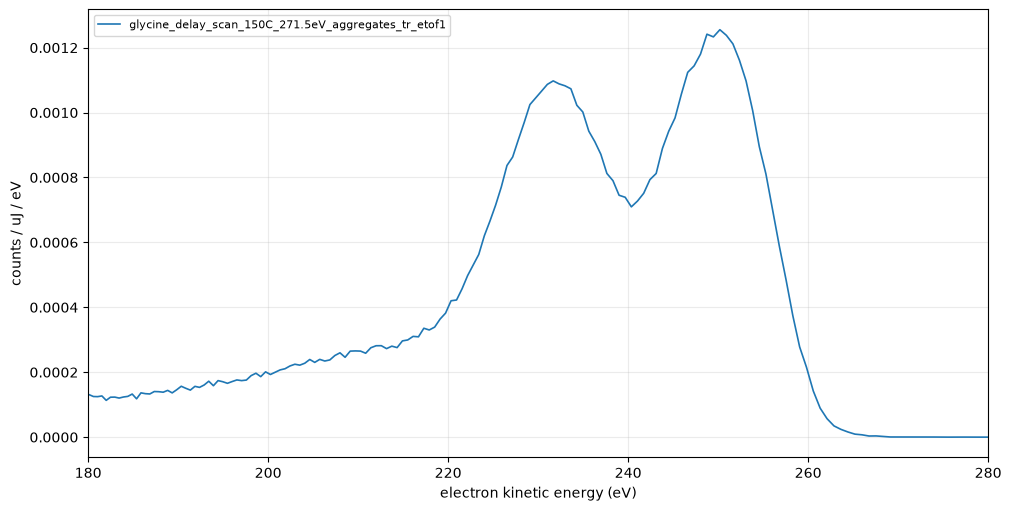

In [13]:

# --- Main electron spectrum: aggregate or shot-resolved histogram ---
SPECTRUM_SOURCE = 'aggregates'  # 'aggregates' or 'shots'
SHOT_TOF_BIN_WIDTH = 1.0   # 100 ps ticks; only used for 'shots'
SPECTRUM_COMPARISON_SHOT_FILE = None

def spectrum_from_source(a, shot_file=None):
    if SPECTRUM_SOURCE == 'aggregates' and not APPLY_FEL_MASK:
        return a.tof_edges, aggregate_stats(a)

    if SPECTRUM_SOURCE not in ('shots', 'aggregates'):
        raise ValueError("SPECTRUM_SOURCE must be 'aggregates' or 'shots'")
    if SHOT_TOF_BIN_WIDTH <= 0:
        raise ValueError('SHOT_TOF_BIN_WIDTH must be positive')

    tof_start, tof_stop = a.tof_edges[0], a.tof_edges[-1]
    edges = np.arange(tof_start, tof_stop, SHOT_TOF_BIN_WIDTH)
    edges = np.append(edges, tof_stop)
    if len(edges) < 2 or np.any(np.diff(edges) <= 0):
        raise ValueError('Invalid shot-resolved TOF bin edges')

    if APPLY_FEL_MASK:
        print('FEL filtering: main spectrum uses shots; aggregate spectra cannot be filtered.')
    source = prepare_shots(a, shot_file)
    result = shot_resolved_gmd_spectrum(source,
        AGG_GMD_RANGE if APPLY_FEL_MASK and AGG_GMD_RANGE is not None else (-np.inf, np.inf),
        edges, **trim_values(a))
    if result['shots'] == 0 or result['sum_gmd'] <= 0:
        raise ValueError('No valid shot-resolved population')

    print(f"Shot spectrum: {result['shots']:,} shots | {len(edges)-1:,} TOF bins | width {SHOT_TOF_BIN_WIDTH:g} ticks")
    return edges, result

def spectrum_background(a, edges, path):
    if not SUBTRACT_BACKGROUND:
        return None
    if not np.array_equal(edges, a.tof_edges):
        raise ValueError('Aggregate background has different TOF bins. Use matching bins or reconstruct the background from shots.')
    return load_background_for(a, path)

spectrum_edges, spectrum_stats = spectrum_from_source(agg, SHOT_FILE)
spectrum_bg = spectrum_background(agg, spectrum_edges, BACKGROUND_FILE)
_, _, spectrum = corrected_components(spectrum_stats, spectrum_bg)
x, y = axis_data(spectrum_edges, spectrum)

fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
ax.plot(0.5*(x[:-1]+x[1:]), y, lw=1.2, label=Path(RUN_FILE).stem)

if SPECTRUM_COMPARISON_FILE is not None:
    comparison_agg = load_aggregates_etof(SPECTRUM_COMPARISON_FILE)
    comparison_edges, comparison_stats = spectrum_from_source(comparison_agg, SPECTRUM_COMPARISON_SHOT_FILE)
    comparison_bg = spectrum_background(comparison_agg, comparison_edges, SPECTRUM_COMPARISON_BACKGROUND)
    _, _, comparison_spectrum = corrected_components(comparison_stats, comparison_bg)
    cx, cy = axis_data(comparison_edges, comparison_spectrum)
    ax.plot(0.5*(cx[:-1]+cx[1:]), cy, lw=1.1, label=Path(SPECTRUM_COMPARISON_FILE).stem)

format_spectrum_axis(ax)
ax.legend(fontsize=8)
plt.show()


In [14]:
SHOW_NORMALISATION_COMPARISON = False

if SHOW_NORMALISATION_COMPARISON:
    if APPLY_FEL_MASK: raise ValueError('Use the main shot spectrum for FEL-filtered normalisation; this legacy panel uses aggregates')
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
    for ax, mode in zip(axes.ravel(), ('raw', 'per_shot', 'per_uJ', 'electron_yield')):
        _, _, values = corrected_components(spectrum_selected_stats, background_stats, mode)
        x, y = axis_data(agg.tof_edges, values, mode)
        ax.stairs(y, x, lw=1)
        format_spectrum_axis(ax, mode)
        ax.set_title(mode)
    plt.show()


## 3. GMD-dependent spectra and response
Auger high GMD cells 3/8 provide direct shot histogram sums and GMD-band spectra.
Show counts/shot and counts/summed-GMD side by side. These are signal-only populations;
no inferred background, Cb correction or physical saturation model is applied.
A falling electron/GMD response is a **possible nonlinearity requiring further investigation**.
Hit-slot occupancy is a storage diagnostic, not a demonstration of detector saturation.


Input: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_271.5eV.h5 | attributes: {}
  gmd (19938, 101) float32 | attrs: {}
  tofs_e (19938, 101, 50) uint32 | attrs: {}
  z (19938, 101) float32 | attrs: {}
  between_tdc_files (19938,) bool | attrs: {}
Shot source: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_271.5eV.h5 | source rows: 19938 | original bunch indices: (0, 101) | z [lo,hi): (np.float64(-15000.0), np.float64(91000.0)) | GMD: (None, None) | preview source-row cap: None
Train trim: 3 3
GMD (1.25, 2.0) | shots: 230788 | sum GMD: 371491.76716959476 | stored-hit-slot ceiling reached: 0
GMD (2.0, 3.0) | shots: 265919 | sum GMD: 662813.1039288044 | stored-hit-slot ceiling reached: 0
GMD (3.0, 6.0) | shots: 590399 | sum GMD: 2573311.6009910107 | stored-hit-slot ceiling reached: 2
GMD (6.0, 12.0) | shots: 483478 | sum GMD: 4024458.2464170456 | stored-hit-slot ceiling reached: 3
GMD (12.0, 24.0) | shots: 76019

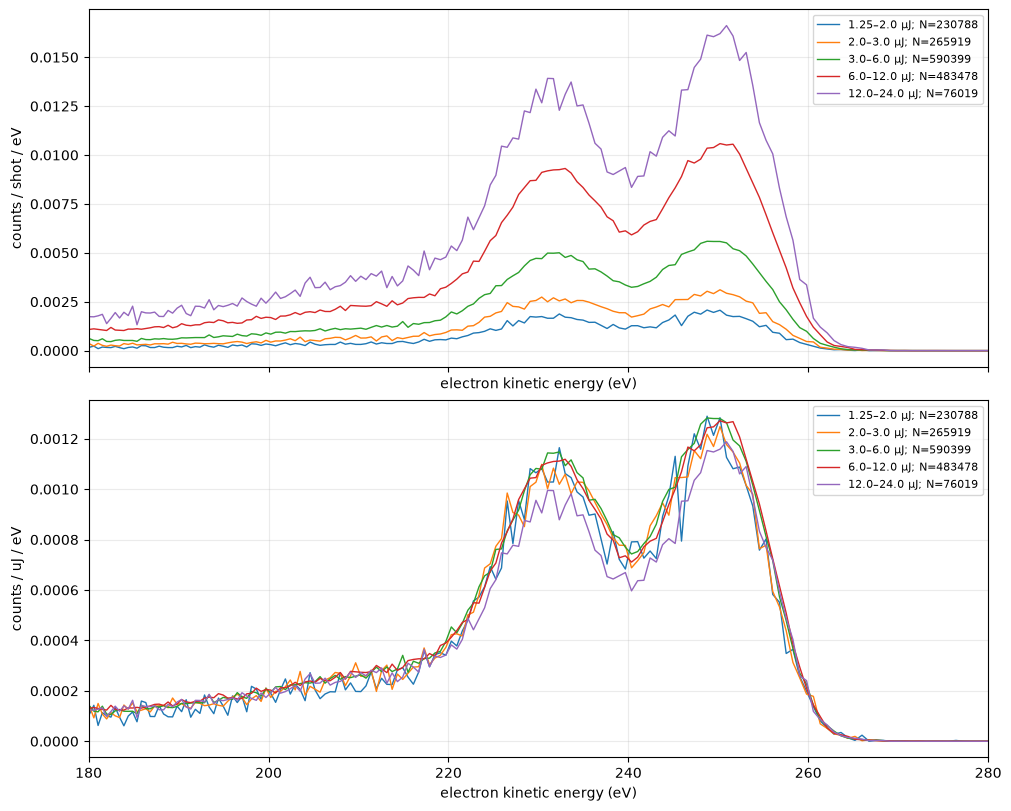

In [15]:

# --- Electron spectra conditioned on GMD ---
RUN_GMD_SPECTRA = True
GMD_SPECTRA_SOURCE = 'shots'  # 'shots' or 'aggregates'
GMD_RANGES_TO_PLOT = [(1.25, 2.0), (2.0, 3.0), (3.0, 6.0), (6.0, 12.0), (12.0, 24.0)]

if RUN_GMD_SPECTRA:
    if GMD_SPECTRA_SOURCE not in ('shots', 'aggregates'):
        raise ValueError("GMD_SPECTRA_SOURCE must be 'shots' or 'aggregates'")

    use_band_shots = APPLY_FEL_MASK or GMD_SPECTRA_SOURCE == 'shots'
    if APPLY_FEL_MASK: print('FEL filtering: GMD-conditioned electron spectra use shots.')
    band_source = prepare_shots(agg, SHOT_FILE) if use_band_shots else None
    band_results = []
    fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True, constrained_layout=True)

    for band in GMD_RANGES_TO_PLOT:
        if use_band_shots:
            result = shot_resolved_gmd_spectrum(band_source, band, agg.tof_edges, **trim_values())
        else:
            stats = aggregate_stats(agg, selection=DELAY_SELECTION, gmd_range=band)
            result = {**stats, 'gmd_range': band, 'saturated_shots': None}

        band_results.append(result)
        print('GMD', band, '| shots:', result['shots'], '| sum GMD:', result['sum_gmd'],
              '| stored-hit-slot ceiling reached:', result['saturated_shots'])

        if result['shots'] == 0:
            continue

        for ax, mode in zip(axes, ('per_shot', 'per_uJ')):
            x, y = axis_data(agg.tof_edges, normalised(result, mode), mode)
            x_centres = 0.5*(x[:-1] + x[1:])
            ax.plot(x_centres, y, lw=1, label=f'{band[0]}–{band[1]} µJ; N={result["shots"]}')
            format_spectrum_axis(ax, mode)

    axes[0].legend(fontsize=8)
    axes[1].legend(fontsize=8)
    plt.show()


In [16]:
tof_edges = agg.tof_edges
ke_a = tof_to_ke(0.5*(tof_edges[:-1] + tof_edges[1:]))
ke_edges = tof_to_ke(tof_edges)
ke_b = 0.5*(ke_edges[:-1] + ke_edges[1:])
valid = np.isfinite(ke_a) & np.isfinite(ke_b) & (ke_b >= KE_XLIM[0]) & (ke_b <= KE_XLIM[1])
print(f'Maximum A–B difference: {np.max(np.abs(ke_a[valid] - ke_b[valid])):.6g} eV')

Maximum A–B difference: 0.000422206 eV


## 4. Shot-resolved electron yield versus GMD
Working GMD-resonance clean cells **14–16**. Total is all positive stored eTOF hits;
KE counts use fractional native-bin overlap. Fine-bin y is mean electrons per shot,
and its SEM is empirical. The second panel uses `mean(counts)/mean(GMD)`, exactly
`sum(counts)/sum(GMD)` within a bin, not mean shot ratios. Edit bands and limits here.


In [17]:
RUN_FINE_GMD = True
FINE_GMD_BIN_WIDTH = 0.25  # uJ
FINE_GMD_RANGE = (0.0,None)  # Upper None: retained-shot 99.9th percentile.
KE_RANGES_FINE = [(160, 180),(180,200), (200, 220), (220, 240),(240,260)]
if RUN_FINE_GMD:
    if not HAS_CALIBRATION: raise ValueError('KE-window diagnostics require calibration')
    fine_source=prepare_shots(agg,SHOT_FILE)
    gmd_shot,ecount_shot,counts_by_ke=read_fine_gmd_diagnostics(
        fine_source,agg.tof_edges,KE_RANGES_FINE,**trim_values())
    gmd_hi=float(np.nanpercentile(gmd_shot,99.9)) if FINE_GMD_RANGE[1] is None else FINE_GMD_RANGE[1]
    if FINE_GMD_BIN_WIDTH <= 0 or gmd_hi <= FINE_GMD_RANGE[0]: raise ValueError('Invalid fine GMD bins')
    fine_edges=np.arange(FINE_GMD_RANGE[0],gmd_hi+FINE_GMD_BIN_WIDTH,FINE_GMD_BIN_WIDTH)
    print('Fine GMD edges:',fine_edges,'| retained shots:',gmd_shot.size)


Input: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_271.5eV.h5 | attributes: {}
  gmd (19938, 101) float32 | attrs: {}
  tofs_e (19938, 101, 50) uint32 | attrs: {}
  z (19938, 101) float32 | attrs: {}
  between_tdc_files (19938,) bool | attrs: {}
Shot source: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_271.5eV.h5 | source rows: 19938 | original bunch indices: (0, 101) | z [lo,hi): (np.float64(-15000.0), np.float64(91000.0)) | GMD: (None, None) | preview source-row cap: None
Train trim: 3 3
Fine GMD edges: [ 0.    0.25  0.5   0.75  1.    1.25  1.5   1.75  2.    2.25  2.5   2.75
  3.    3.25  3.5   3.75  4.    4.25  4.5   4.75  5.    5.25  5.5   5.75
  6.    6.25  6.5   6.75  7.    7.25  7.5   7.75  8.    8.25  8.5   8.75
  9.    9.25  9.5   9.75 10.   10.25 10.5  10.75 11.   11.25 11.5  11.75
 12.   12.25 12.5  12.75 13.   13.25 13.5  13.75 14.   14.25 14.5  14.75
 15.   15.25 15.5  15.75 16.   16.25 16.5  

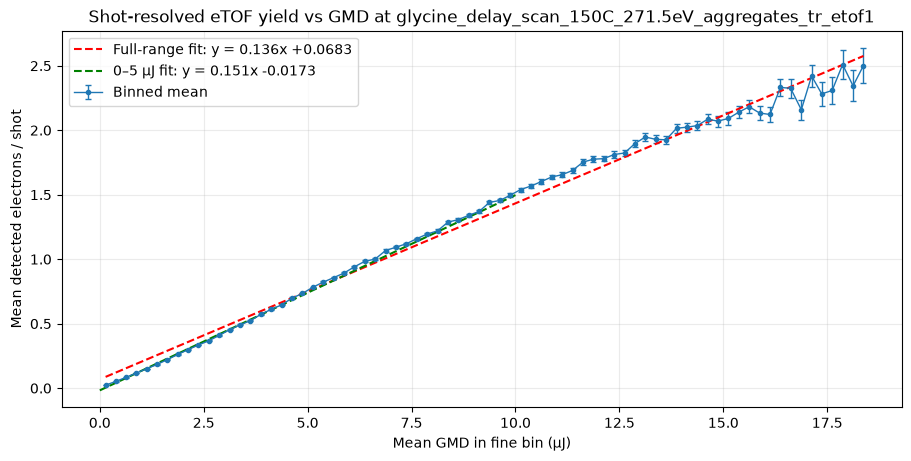

In [18]:

if RUN_FINE_GMD:
    x_mean, y_mean, y_sem, n_shots = fine_bin_mean_sem(gmd_shot, ecount_shot, fine_edges)
    good = (n_shots > 0) & np.isfinite(x_mean) & np.isfinite(y_mean)
    good_05 = good & (x_mean >= 0) & (x_mean <= 5)

    fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
    ax.errorbar(x_mean[good], y_mean[good], yerr=y_sem[good], fmt="o-", ms=3, lw=1.0, capsize=2, label="Binned mean")

    if good.sum() >= 2 and np.unique(x_mean[good]).size >= 2:
        slope, intercept = np.polyfit(x_mean[good], y_mean[good], 1)
        x_fit = np.linspace(x_mean[good].min(), x_mean[good].max(), 200)
        ax.plot(x_fit, slope*x_fit + intercept, "r--", lw=1.5, label=f"Full-range fit: y = {slope:.3g}x {intercept:+.3g}")

    if good_05.sum() >= 2 and np.unique(x_mean[good_05]).size >= 2:
            slope_05, intercept_05 = np.polyfit(x_mean[good_05], y_mean[good_05], 1)
            x_fit_05 = np.linspace(0, 10, 200)            
            ax.plot(x_fit_05, slope_05*x_fit_05 + intercept_05, "g--", lw=1.5, label=f"0–5 µJ fit: y = {slope_05:.3g}x {intercept_05:+.3g}")

    ax.set_xlabel("Mean GMD in fine bin (µJ)")
    ax.set_ylabel("Mean detected electrons / shot")
    ax.set_title(f"Shot-resolved eTOF yield vs GMD at {Path(RUN_FILE).stem}")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.show()


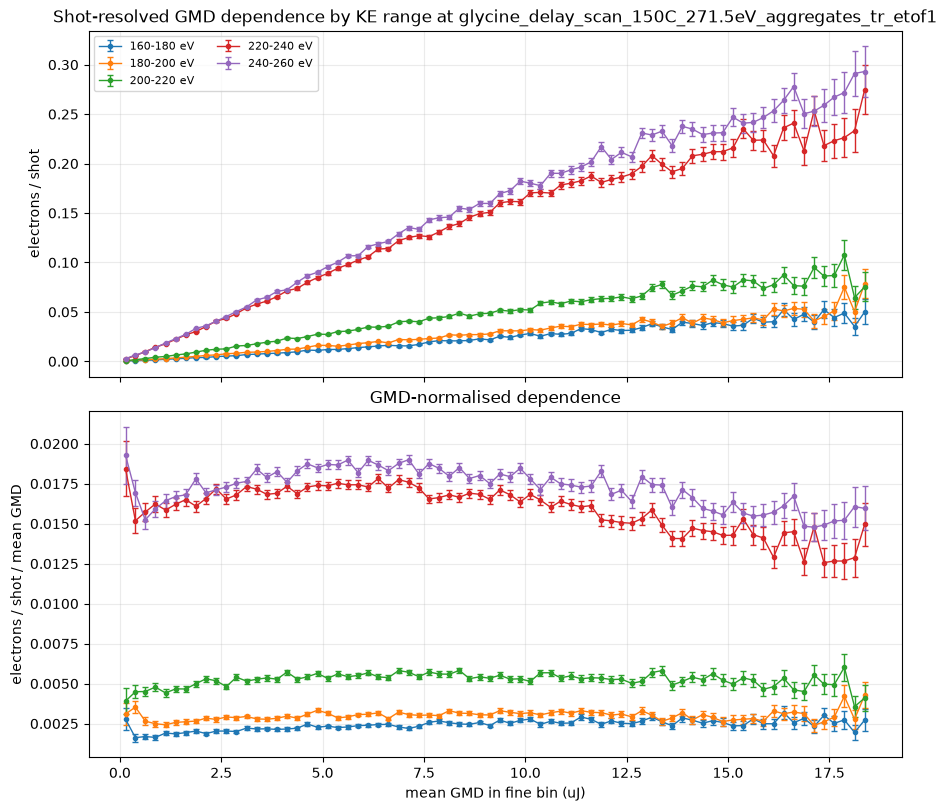

In [19]:
if RUN_FINE_GMD:
    fig, axes = plt.subplots(2, 1, figsize=(9, 8), sharex=True, constrained_layout=True)

    for ke_range, counts in counts_by_ke.items():
        x_mean, y_mean, y_sem, n_shots = fine_bin_mean_sem(gmd_shot, counts, fine_edges)

        good = n_shots > 0
        label = f"{ke_range[0]}-{ke_range[1]} eV"

        axes[0].errorbar(x_mean[good], y_mean[good], yerr=y_sem[good], fmt="o-", ms=3, lw=1.0, capsize=2, label=label)

        # mean(counts)/mean(GMD) is algebraically equal to
        # sum(counts)/sum(GMD) for the shots in each fine bin.
        with np.errstate(invalid="ignore", divide="ignore"):
            y_over_gmd = y_mean / x_mean
            y_over_gmd_sem = y_sem / x_mean

        axes[1].errorbar(x_mean[good], y_over_gmd[good], yerr=y_over_gmd_sem[good], fmt="o-", ms=3, lw=1.0, capsize=2, label=label)

    axes[0].set_ylabel("electrons / shot")
    axes[0].set_title(f"Shot-resolved GMD dependence by KE range at {Path(RUN_FILE).stem}")
    axes[0].grid(alpha=0.25)
    axes[0].legend(fontsize=8, ncols=2)

    axes[1].set_xlabel("mean GMD in fine bin (uJ)")
    axes[1].set_ylabel("electrons / shot / mean GMD")
    axes[1].set_title("GMD-normalised dependence")
    axes[1].grid(alpha=0.25)

    plt.show()

## 5. Bunch-position dependence — selected run
Bunch investigations cells **2, 7, 11, 17**. Direct KE hit selection is `[KE_min,KE_max)`;
this is the original bunch estimator, distinct from fractional histogram overlap above.
The four-panel contribution figure preserves cell 11's sums and denominators; cell 17
preserves equal bunch-section splitting and common percentile-based GMD histogram bins.
The GMD distribution population includes the explicit shot selections above. No delay
conversion is guessed: the common selector uses stored stage edges directly.


In [20]:
# Shared editable bunch settings; both one-run and comparison sections use these.
KE_RANGES = [(160, 180),(180,200), (200, 220), (220, 240),(240,260)]
BUNCH_GMD_RANGES = {    '1-2': (1.0, 2.0),    '3-4': (3.0, 4.0),    '5-6': (5.0, 6.0),    '6-8': (6.0, 8.0),    '8-12': (8.0, 12.0),}
# BUNCH_GMD_RANGES = {'low':(0.6,1.3),'high':(1.3,2.0)}  # uJ, [lo,hi).
MIN_SHOTS_PER_BUNCH = 100

def make_bunch_sections(n_bunch,n_sections=4):
    if n_bunch < n_sections: raise ValueError('Need at least four selected bunch positions')
    sections=[np.asarray(idx,dtype=int) for idx in np.array_split(np.arange(n_bunch),n_sections)]
    labels=[f'{bunch[idx[0]]}-{bunch[idx[-1]]}' for idx in sections]
    return sections,labels


def bunch_dataset(a,path,label,color):
    source=prepare_shots(a,path)
    result=read_bunch_position_diagnostics(source,KE_RANGES,{'all':(None,None),**BUNCH_GMD_RANGES},
        delay_window_fs=None,**trim_values(a))
    lo,hi=SHOT_CONTEXT['bunch']
    # Retain original bunch slot numbers in plotted coordinates.
    result['bunch']=result['bunch'][lo:hi]
    result['gmd_kept']=result['gmd_kept'][:,lo:hi]
    for by_ke in result['stats'].values():
        for st in by_ke.values():
            for key in st: st[key]=st[key][lo:hi]
    if not np.any(np.isfinite(result['gmd_kept'])): raise ValueError('No selected bunch shots')
    return dict(label=label,color=color,bunch_diag=result,source_h5=source)


In [21]:
RUN_BUNCH = True
# KE_RANGES, BUNCH_GMD_RANGES and MIN_SHOTS_PER_BUNCH are editable in the shared helper cell.
if RUN_BUNCH:
    if not HAS_CALIBRATION: raise ValueError('Bunch KE diagnostics require calibration')
    energy_datasets=[bunch_dataset(agg,SHOT_FILE,Path(RUN_FILE).stem,'#1f77b4')]
    bunch_diag=energy_datasets[0]['bunch_diag']
    bunch=bunch_diag['bunch']
    if bunch.size<4: raise ValueError('Four-section diagnostics need at least four selected slots')
    print('Selected bunch diagnostic:',bunch_diag['gmd_kept'].shape)


Input: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_271.5eV.h5 | attributes: {}
  gmd (19938, 101) float32 | attrs: {}
  tofs_e (19938, 101, 50) uint32 | attrs: {}
  z (19938, 101) float32 | attrs: {}
  between_tdc_files (19938,) bool | attrs: {}
Shot source: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_271.5eV.h5 | source rows: 19938 | original bunch indices: (0, 101) | z [lo,hi): (np.float64(-15000.0), np.float64(91000.0)) | GMD: (None, None) | preview source-row cap: None
Train trim: 3 3
Selected bunch diagnostic: (19863, 101)


Input: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_271.5eV.h5 | attributes: {}
  gmd (19938, 101) float32 | attrs: {}
  tofs_e (19938, 101, 50) uint32 | attrs: {}
  z (19938, 101) float32 | attrs: {}
  between_tdc_files (19938,) bool | attrs: {}
Shot source: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_271.5eV.h5 | source rows: 19938 | original bunch indices: (0, 101) | z [lo,hi): (np.float64(-15000.0), np.float64(91000.0)) | GMD: (None, None) | preview source-row cap: None
Train trim: 3 3


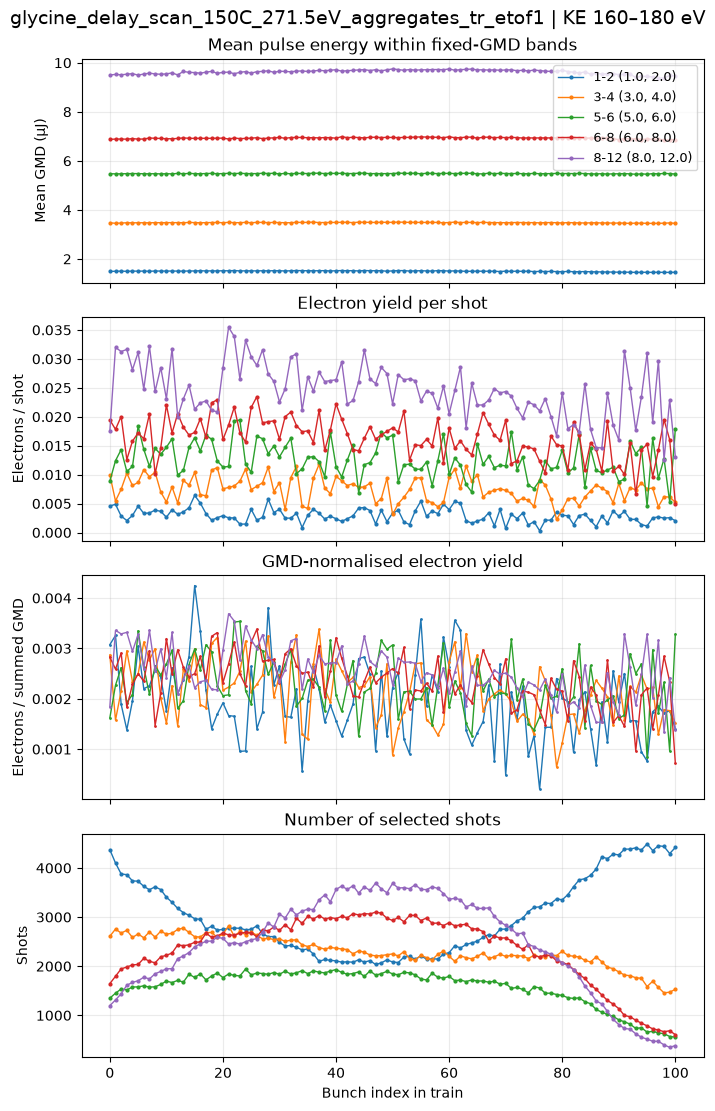

In [22]:

# --- Fixed-GMD comparison by bunch for the selected run ---
RUN_SINGLE_BUNCH_GMD = True
BUNCH_GMD_RANGES = {'1-2': (1.0, 2.0), '3-4': (3.0, 4.0), '5-6': (5.0, 6.0), '6-8': (6.0, 8.0), '8-12': (8.0, 12.0)}
PLOT_KE_RANGE = KE_RANGES[0]

if RUN_SINGLE_BUNCH_GMD:
    if not HAS_CALIBRATION: raise ValueError('Bunch KE diagnostics require calibration')

    # Recalculate using the GMD ranges defined above.
    single_bunch_ds = bunch_dataset(agg, SHOT_FILE, Path(RUN_FILE).stem, '#1f77b4')
    bd = single_bunch_ds['bunch_diag']
    bunch_ds = bd['bunch']
    gmd_labels = [label for label in bd['gmd_ranges'] if label != 'all']

    plot_rows = [
        ('mean_gmd', 'Mean pulse energy within fixed-GMD bands', 'Mean GMD (µJ)'),
        ('electrons_per_shot', 'Electron yield per shot', 'Electrons / shot'),
        ('electrons_per_gmd', 'GMD-normalised electron yield', 'Electrons / summed GMD'),
        ('shots', 'Number of selected shots', 'Shots'),
    ]

    fig, axes = plt.subplots(4, 1, figsize=(7, 11), sharex=True, constrained_layout=True)
    gmd_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

    for i_label, label in enumerate(gmd_labels):
        st = bd['stats'][label][PLOT_KE_RANGE]
        good = ((st['shots'] >= MIN_SHOTS_PER_BUNCH) & np.isfinite(st['mean_gmd'])
                & np.isfinite(st['electrons_per_shot']) & np.isfinite(st['electrons_per_gmd']))

        colour = gmd_colors[i_label % len(gmd_colors)]
        gmd_range = bd['gmd_ranges'][label]

        axes[0].plot(bunch_ds[good], st['mean_gmd'][good], 'o-', ms=2, lw=1, color=colour, label=f'{label} {gmd_range}')
        axes[1].plot(bunch_ds[good], st['electrons_per_shot'][good], 'o-', ms=2, lw=1, color=colour)
        axes[2].plot(bunch_ds[good], st['electrons_per_gmd'][good], 'o-', ms=1, lw=1, color=colour)
        axes[3].plot(bunch_ds[good], st['shots'][good], 'o-', ms=2, lw=1, color=colour)

    for ax, (_, title, ylabel) in zip(axes, plot_rows):
        ax.set_title(title)
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.25)

    axes[0].legend(fontsize=9)
    axes[-1].set_xlabel('Bunch index in train')
    fig.suptitle(f'{single_bunch_ds["label"]} | KE {PLOT_KE_RANGE[0]}–{PLOT_KE_RANGE[1]} eV', fontsize=14)
    plt.show()



KE 160-180 eV
  glycine_delay_scan_150C_271.5eV_aggregates_tr_etof1
    total electrons: 21187
    total summed GMD: 8.92582e+06 uJ
    median electrons/GMD over bunch slots: 0.00237932


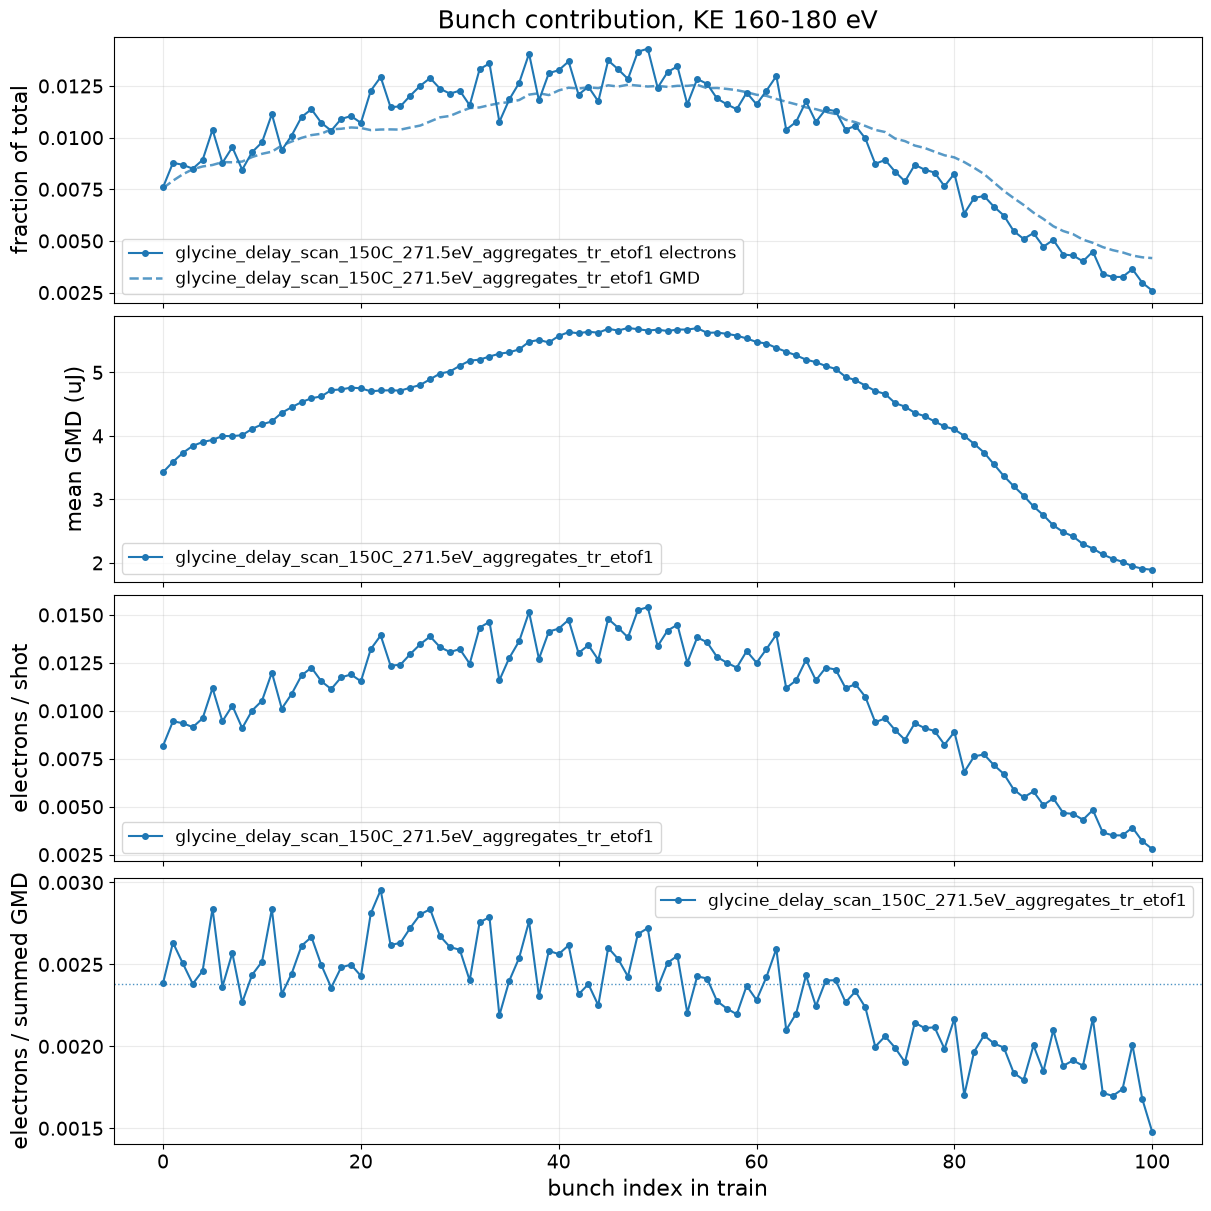


KE 180-200 eV
  glycine_delay_scan_150C_271.5eV_aggregates_tr_etof1
    total electrons: 26944
    total summed GMD: 8.92582e+06 uJ
    median electrons/GMD over bunch slots: 0.00300235


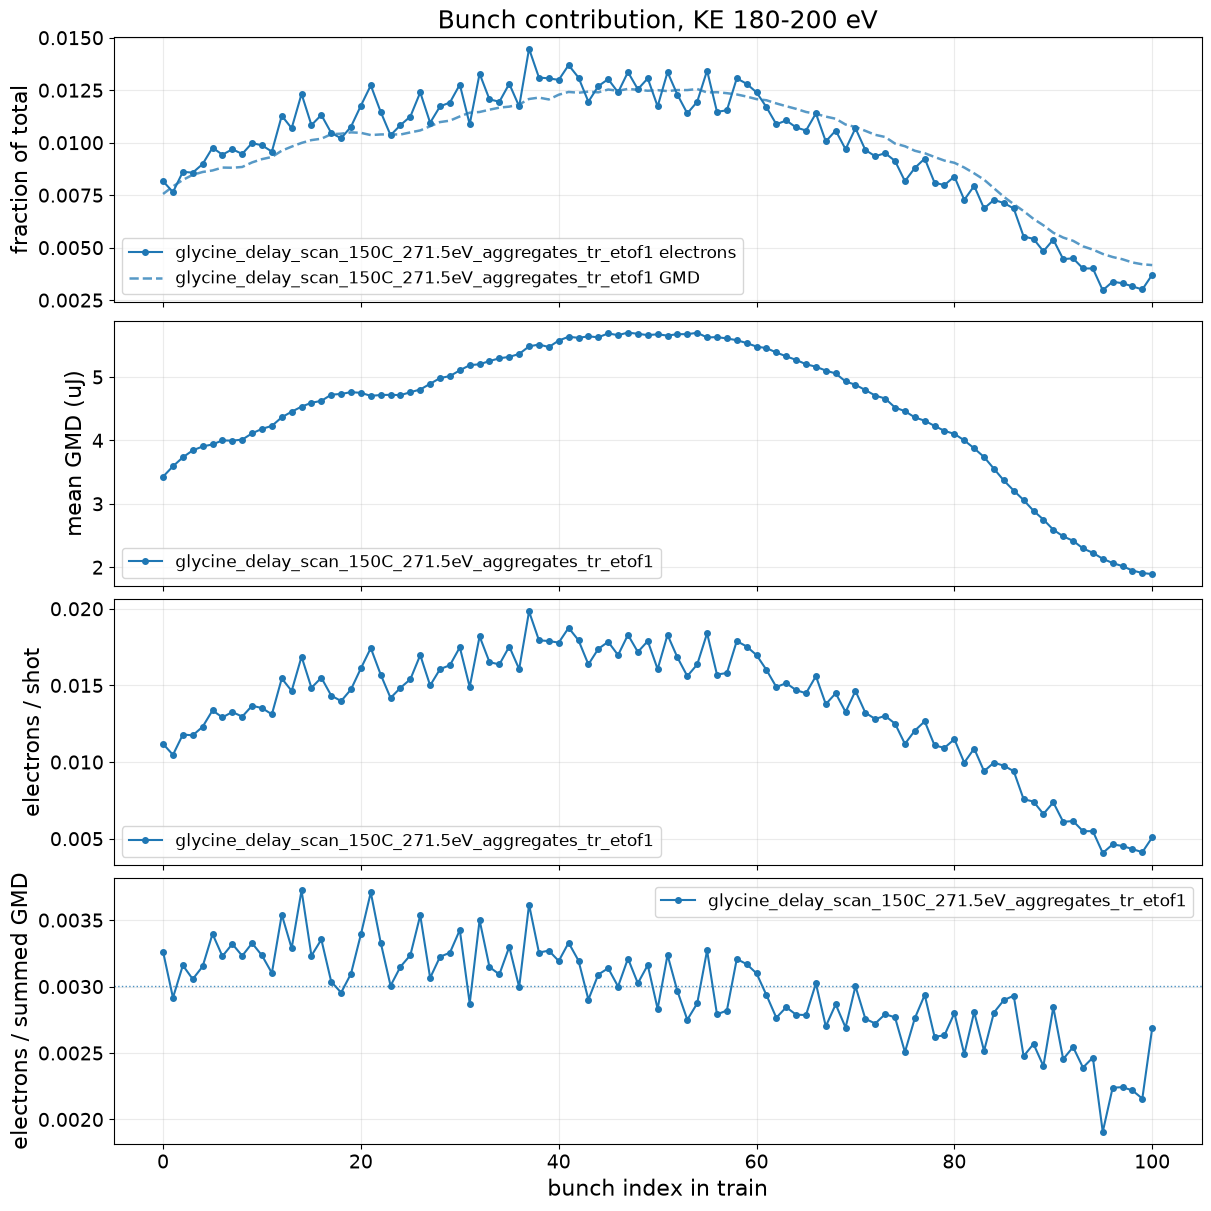


KE 200-220 eV
  glycine_delay_scan_150C_271.5eV_aggregates_tr_etof1
    total electrons: 45882
    total summed GMD: 8.92582e+06 uJ
    median electrons/GMD over bunch slots: 0.00514531


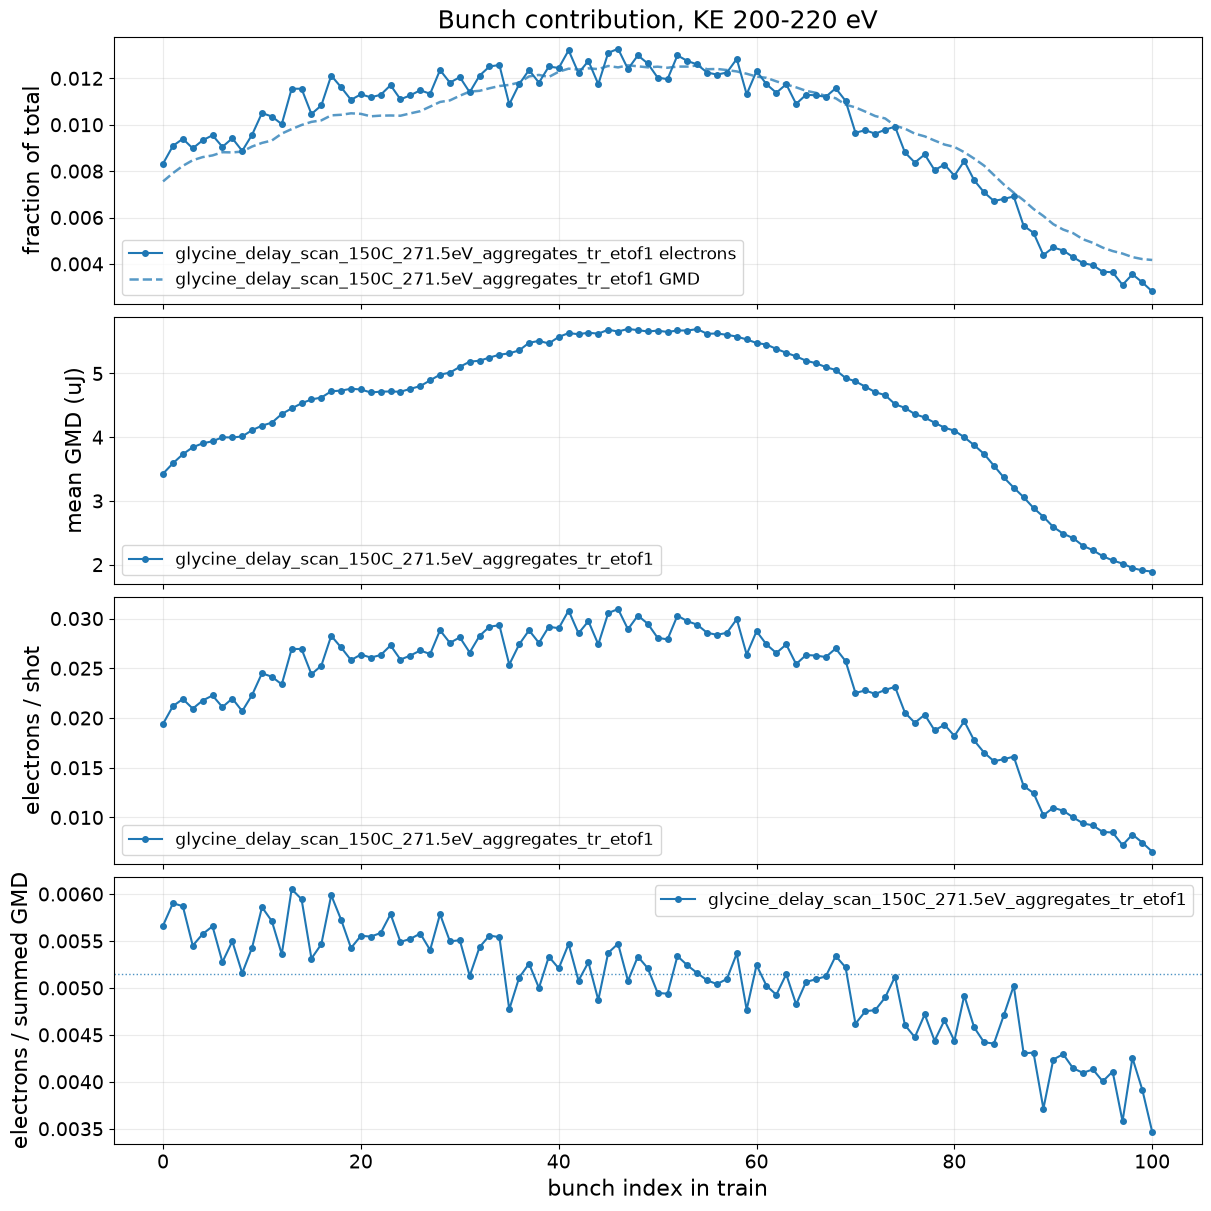


KE 220-240 eV
  glycine_delay_scan_150C_271.5eV_aggregates_tr_etof1
    total electrons: 146011
    total summed GMD: 8.92582e+06 uJ
    median electrons/GMD over bunch slots: 0.0163457


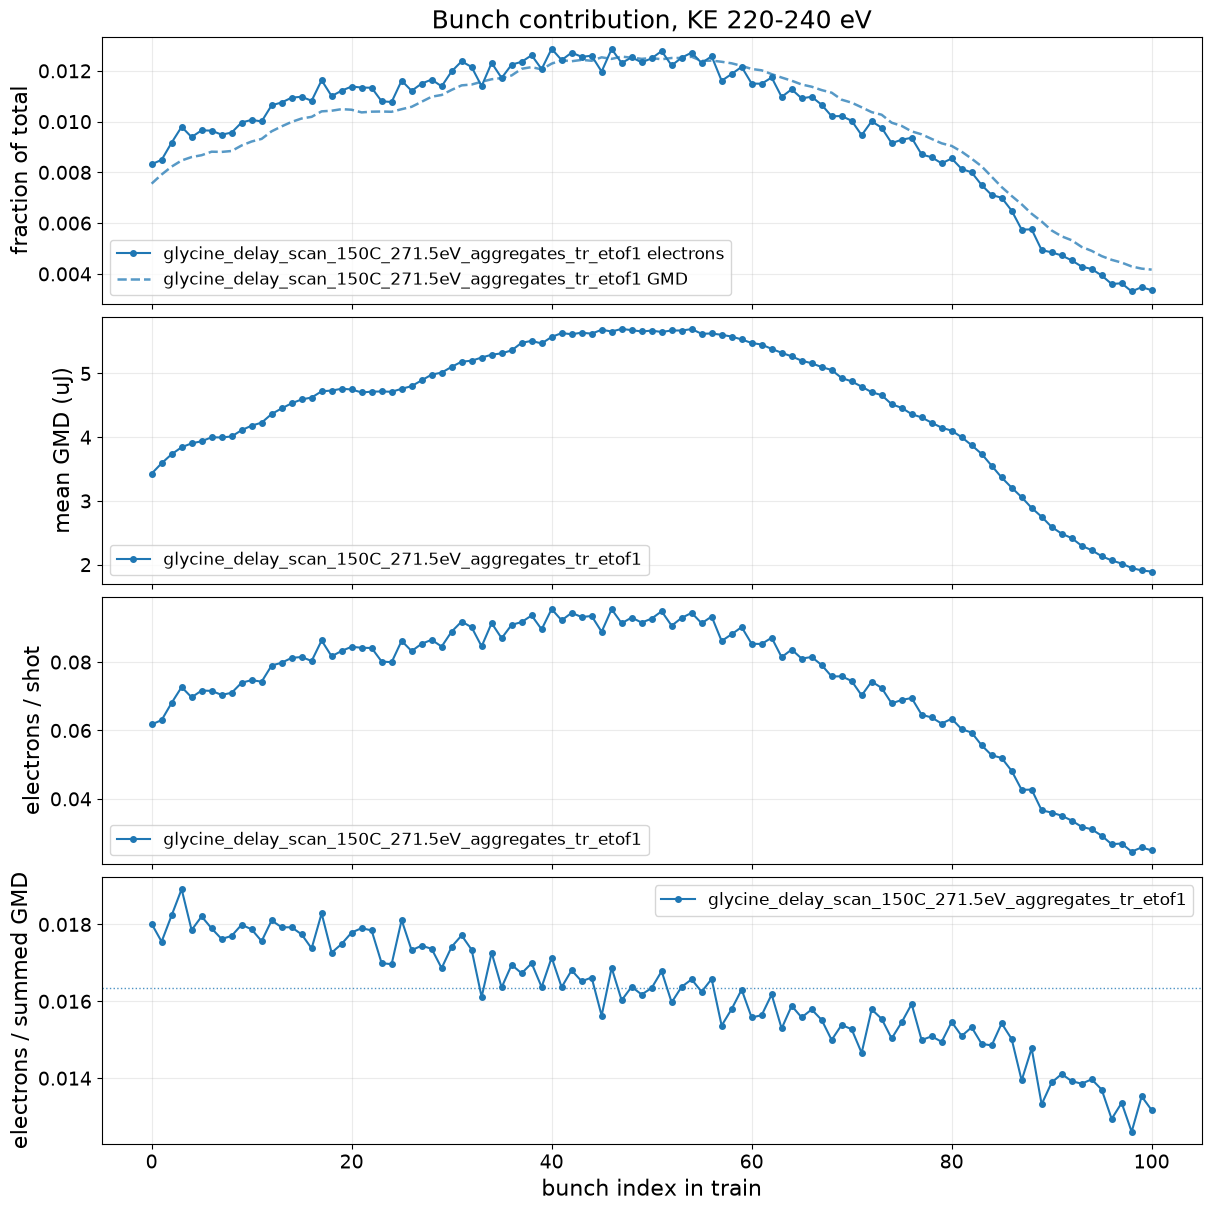


KE 240-260 eV
  glycine_delay_scan_150C_271.5eV_aggregates_tr_etof1
    total electrons: 162571
    total summed GMD: 8.92582e+06 uJ
    median electrons/GMD over bunch slots: 0.018159


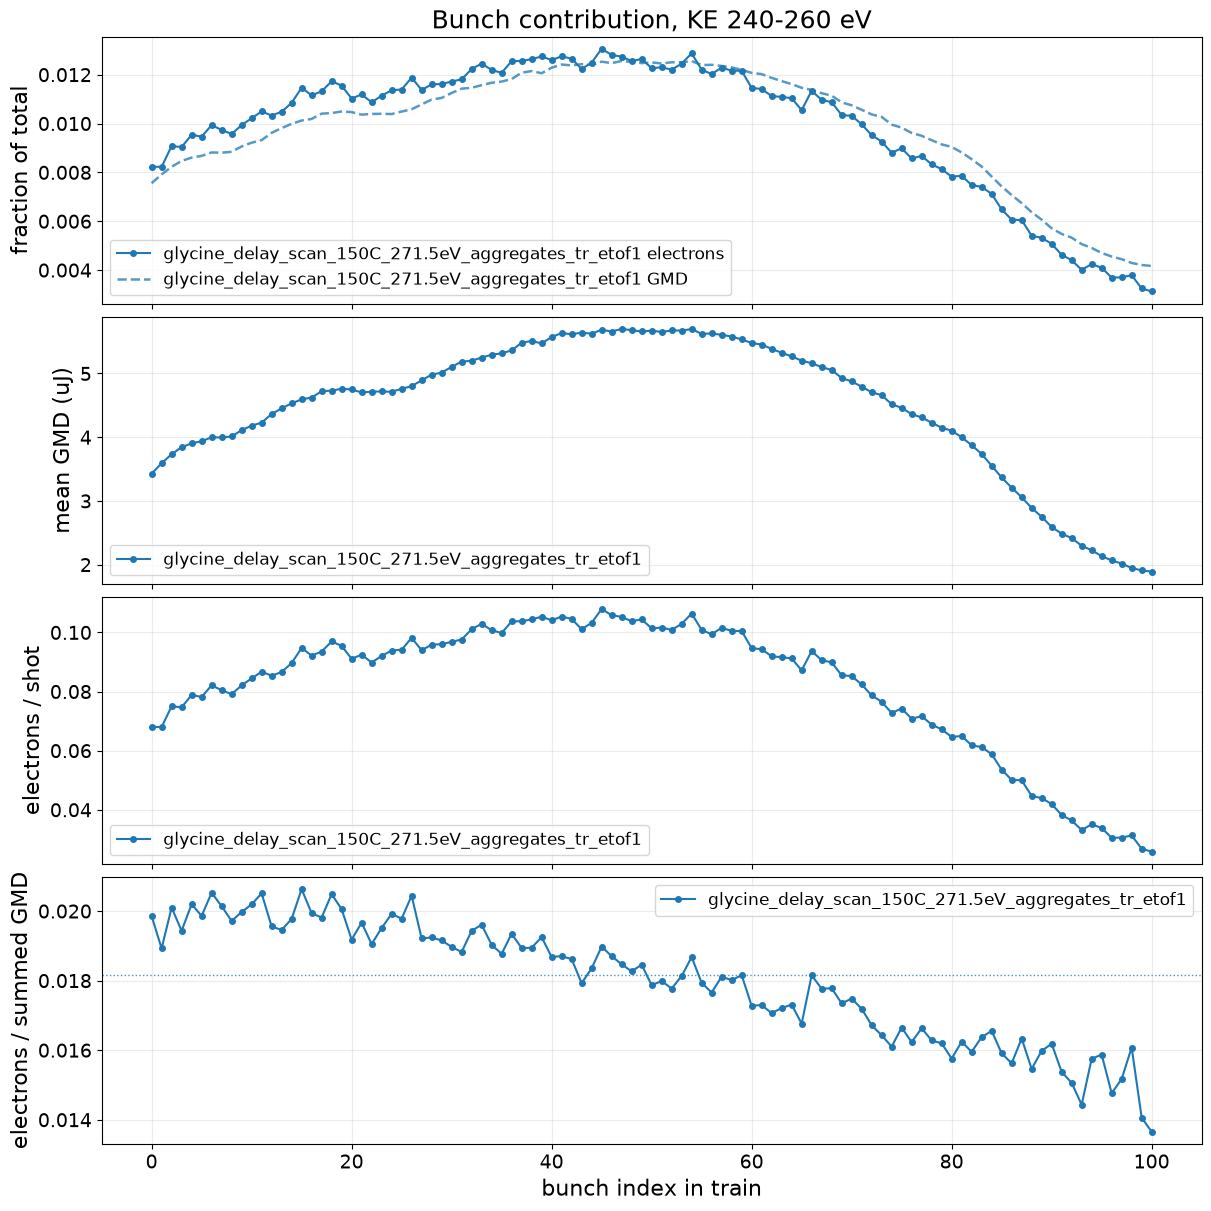

In [23]:
if RUN_BUNCH:
    import matplotlib.pyplot as plt
    import numpy as np

    # --- Bunch contribution, comparing selected incident energies ---
    plt.rcParams.update({
        "font.size": 14,
        "axes.labelsize": 16,
        "axes.titlesize": 18,
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
        "legend.fontsize": 12,
    })

    # High-contrast color palette fallback (Deep Blue, Orange, Green, Purple, Red)
    PALETTE = ["#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd", "#d62728"]

    for ke_range in KE_RANGES:
        fig, axes = plt.subplots(4, 1, figsize=(12, 12), sharex=True, constrained_layout=True)
        print(f"\nKE {ke_range[0]}-{ke_range[1]} eV")

        for idx, ds in enumerate(energy_datasets):
            bd = ds["bunch_diag"]
            stats = bd["stats"]["all"][ke_range]
            good = stats["shots"] >= MIN_SHOTS_PER_BUNCH
            b = bd["bunch"][good]

            total_electrons = np.nansum(stats["electrons"])
            total_gmd = np.nansum(stats["sum_gmd"])

            with np.errstate(invalid="ignore", divide="ignore"):
                electron_fraction = stats["electrons"][good] / total_electrons
                gmd_fraction = stats["sum_gmd"][good] / total_gmd

            color = ds.get("color", PALETTE[idx % len(PALETTE)])

            # Plot 1: Solid line + markers for electrons; markerless dashed line for GMD
            axes[0].plot(b, electron_fraction, "o-", color=color, ms=4, lw=1.5, label=f"{ds['label']} electrons")
            axes[0].plot(b, gmd_fraction, "--", color=color, lw=1.8, alpha=0.75, label=f"{ds['label']} GMD")

            # Plots 2-4: Standard solid line with markers
            axes[1].plot(b, stats["mean_gmd"][good], "o-", color=color, ms=4, lw=1.5, label=ds["label"])
            axes[2].plot(b, stats["electrons_per_shot"][good], "o-", color=color, ms=4, lw=1.5, label=ds["label"])

            median_e_gmd = np.nanmedian(stats["electrons_per_gmd"][good])
            axes[3].plot(b, stats["electrons_per_gmd"][good], "o-", color=color, ms=4, lw=1.5, label=ds["label"])
            axes[3].axhline(median_e_gmd, color=color, lw=1.0, ls=":", alpha=0.8)

            print(f"  {ds['label']}\n    total electrons: {total_electrons:.6g}\n    total summed GMD: {total_gmd:.6g} uJ")
            print(f"    median electrons/GMD over bunch slots: {median_e_gmd:.6g}")

        # Formatting axes
        titles_labels = [
            ("fraction of total", f"Bunch contribution, KE {ke_range[0]}-{ke_range[1]} eV"),
            ("mean GMD (uJ)", None),
            ("electrons / shot", None),
            ("electrons / summed GMD", None)
        ]

        for ax, (ylabel, title) in zip(axes, titles_labels):
            ax.set_ylabel(ylabel)
            if title: 
                ax.set_title(title)
            ax.grid(alpha=0.25)
            ax.legend()
            ax.tick_params(axis="both", which="major", labelsize=14)

        axes[3].set_xlabel("bunch index in train")
        plt.show()


Bunch-train sections:
  0-25: 26 bunch slots
  26-50: 25 bunch slots
  51-75: 25 bunch slots
  76-100: 25 bunch slots


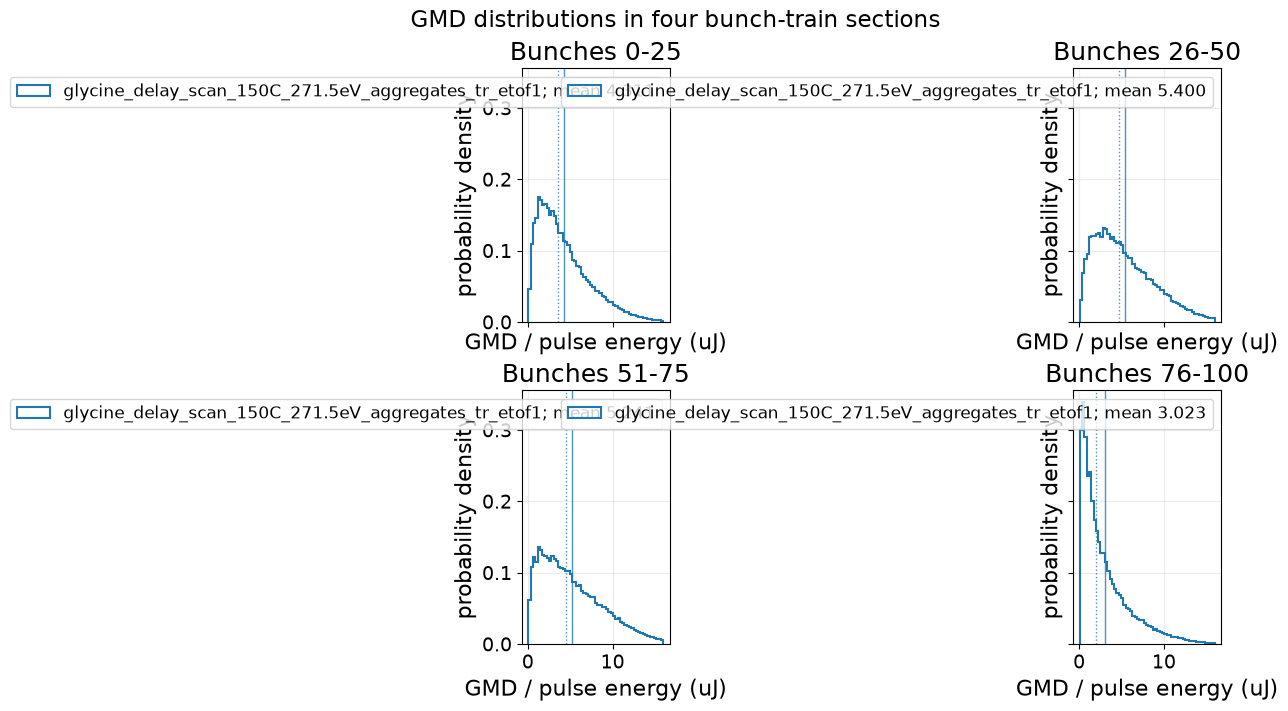

In [24]:
if RUN_BUNCH:
    # --- Split the bunch train into four sections and compare GMD distributions ---

    N_BUNCH_SECTIONS = 4
    BUNCH_SECTIONS, BUNCH_SECTION_LABELS = make_bunch_sections(bunch.size, N_BUNCH_SECTIONS)

    print("Bunch-train sections:")
    for label, idx in zip(BUNCH_SECTION_LABELS, BUNCH_SECTIONS):
        print(f"  {label}: {idx.size} bunch slots")

    all_section_gmd = np.concatenate([
        ds["bunch_diag"]["gmd_kept"][:, idx].ravel()
        for ds in energy_datasets
        for idx in BUNCH_SECTIONS
    ])
    all_section_gmd = all_section_gmd[np.isfinite(all_section_gmd)]

    gmd_plot_min, gmd_plot_max = np.nanpercentile(all_section_gmd, [0.5, 99.5])
    gmd_edges = np.linspace(gmd_plot_min, gmd_plot_max, 60)

    fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True, constrained_layout=True)

    for ax, idx, section_label in zip(axes.ravel(), BUNCH_SECTIONS, BUNCH_SECTION_LABELS):
        for ds in energy_datasets:
            gmd_kept = ds["bunch_diag"]["gmd_kept"]
            values = gmd_kept[:, idx].ravel()
            values = values[np.isfinite(values)]

            mean_gmd = np.mean(values)
            median_gmd = np.median(values)

            ax.hist(
                values,
                bins=gmd_edges,
                density=True,
                histtype="step",
                lw=1.5,
                color=ds["color"],
                label=f"{ds['label']}; mean {mean_gmd:.3f}",
            )
            ax.axvline(mean_gmd, color=ds["color"], lw=1.0, alpha=0.8)
            ax.axvline(median_gmd, color=ds["color"], lw=1.0, ls=":", alpha=0.8)

        ax.set_title(f"Bunches {section_label}")
        ax.set_xlabel("GMD / pulse energy (uJ)")
        ax.set_ylabel("probability density")
        ax.grid(alpha=0.25)
        ax.legend()

    fig.suptitle("GMD distributions in four bunch-train sections")

    plt.show()


## 6. Checking ions

Input: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_271.5eV.h5 | attributes: {}
  gmd (19938, 101) float32 | attrs: {}
  tofs_e (19938, 101, 50) uint32 | attrs: {}
  z (19938, 101) float32 | attrs: {}
  between_tdc_files (19938,) bool | attrs: {}
Shot source: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_271.5eV.h5 | source rows: 19938 | original bunch indices: (0, 101) | z [lo,hi): (np.float64(-15000.0), np.float64(91000.0)) | GMD: (None, None) | preview source-row cap: None
Train trim: 3 3
Ion source: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_271.5eV.h5 | TOF range: 54.9–31065.7 ticks
Selected shots: 1,789,872 | ion hits within plotted TOF range: 1,975,151
Shots at ion hit-slot ceiling: 1 / 1,789,872


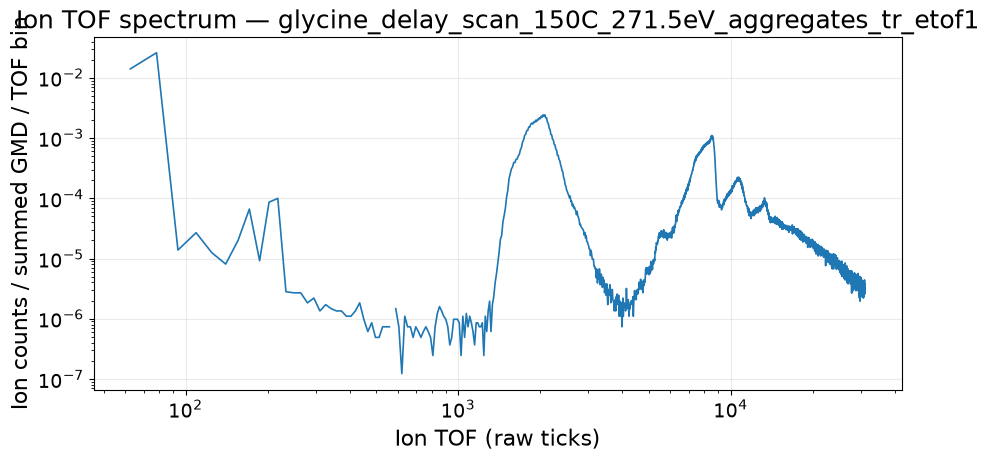

In [39]:

# --- Ion TOF: shot-resolved histogram, prepared once for subsequent plots ---
ION_TOF_RANGE = None   # None: estimate from 1st–99th percentile; otherwise (min,max) in raw TOF ticks
ION_TOF_BINNING = 'linear'  # 'linear' or 'log'
ION_TOF_BINS = 2000
ION_CHUNK_TRAINS = 250
ION_BUNCH_START = 10
ION_GMD_BANDS = {'1–2': (1, 2), '3–4': (3, 4), '5–6': (5, 6), '6–8': (6, 8), '8–12': (8, 12)}
ION_FIXED_GMD_RANGE = (4.0, 6.0)
ION_BUNCH_GROUPS = {'early': (10, 30), 'middle': (45, 65), 'late': (80, 100)}  # Inclusive bunch indices

ion_source = prepare_shots(agg, SHOT_FILE)
with h5py.File(ion_source, 'r') as f:
    if 'tofs_i' not in f: raise KeyError('Selected shot-resolved HDF5 has no /tofs_i dataset')
    if f['tofs_i'].ndim != 3 or f['tofs_i'].shape[:2] != f['gmd'].shape:
        raise ValueError('Ion TOF and GMD must share [train,bunch] axes')
    ion_total_trains, ion_n_bunch = f['gmd'].shape
    if not 0 <= ION_BUNCH_START < ion_n_bunch: raise ValueError('ION_BUNCH_START outside the source bunch axis')
    ion_n_trains = ion_total_trains if SHOT_MAX_TRAINS is None else min(ion_total_trains, SHOT_MAX_TRAINS)
    ion_n_slots = f['tofs_i'].shape[-1]
    ion_row_keep = keep_mask_like_compute_aggregates_from_h5(f, **{k:v for k,v in trim_values(agg).items() if k != 'chunk_trains'})
    ion_dtype = f['tofs_i'].dtype

if ION_TOF_BINS < 2 or ION_CHUNK_TRAINS < 1: raise ValueError('Invalid ion histogram settings')

# Preliminary pass: determine a useful TOF range without storing individual hits.
if ION_TOF_RANGE is None:
    if not np.issubdtype(ion_dtype, np.integer):
        raise ValueError('Automatic TOF-range discovery expects integer ion timestamps; set ION_TOF_RANGE explicitly')
    ion_pilot_edges = np.geomspace(1.0, float(np.iinfo(ion_dtype).max), 801)
    ion_pilot_hist = np.zeros(800, dtype=np.int64)

    with h5py.File(ion_source, 'r') as f:
        for start in range(0, ion_n_trains, ION_CHUNK_TRAINS):
            stop = min(start+ION_CHUNK_TRAINS, ion_n_trains)
            rows = ion_row_keep[start:stop]
            if not rows.any(): continue
            g = selected_gmd(f, start, stop, rows)
            g[:, :ION_BUNCH_START] = np.nan
            tof = f['tofs_i'][start:stop][rows]
            valid_hit = (tof > 0) & (np.isfinite(g) & (g > 0))[:, :, None]
            ion_pilot_hist += np.histogram(tof[valid_hit], bins=ion_pilot_edges)[0]

    if not ion_pilot_hist.sum(): raise ValueError('No valid ion hits for automatic TOF-range selection')
    cumul = np.cumsum(ion_pilot_hist)
    q_lo, q_hi = [np.sqrt(ion_pilot_edges[j]*ion_pilot_edges[j+1]) for j in
                  [np.searchsorted(cumul, q*cumul[-1]) for q in (0.01, 0.99)]]
    ion_tof_range = (max(1.0, 0.8*q_lo), min(float(np.iinfo(ion_dtype).max), 1.2*q_hi))
else:
    ion_tof_range = tuple(map(float, ION_TOF_RANGE))

if not (0 < ion_tof_range[0] < ion_tof_range[1]): raise ValueError('Invalid ION_TOF_RANGE')
if ION_TOF_BINNING == 'linear':
    ion_tof_edges = np.linspace(*ion_tof_range, ION_TOF_BINS+1)
    ion_tof_centres = 0.5*(ion_tof_edges[:-1]+ion_tof_edges[1:])
elif ION_TOF_BINNING == 'log':
    ion_tof_edges = np.geomspace(*ion_tof_range, ION_TOF_BINS+1)
    ion_tof_centres = np.sqrt(ion_tof_edges[:-1]*ion_tof_edges[1:])
else:
    raise ValueError("ION_TOF_BINNING must be 'linear' or 'log'")

# Store histograms by GMD band and original bunch index.
ion_bands = {'all': (None, None), **ION_GMD_BANDS, 'fixed': ION_FIXED_GMD_RANGE}
ion_counts = {name: np.zeros((ion_n_bunch, ION_TOF_BINS), dtype=np.int64) for name in ion_bands}
ion_sum_gmd = {name: np.zeros(ion_n_bunch, dtype=float) for name in ion_bands}
ion_shots = {name: np.zeros(ion_n_bunch, dtype=np.int64) for name in ion_bands}
ion_full_slots = {name: np.zeros(ion_n_bunch, dtype=np.int64) for name in ion_bands}

with h5py.File(ion_source, 'r') as f:
    for start in range(0, ion_n_trains, ION_CHUNK_TRAINS):
        stop = min(start+ION_CHUNK_TRAINS, ion_n_trains)
        rows = ion_row_keep[start:stop]
        if not rows.any(): continue
        g = selected_gmd(f, start, stop, rows)
        g[:, :ION_BUNCH_START] = np.nan
        tof = f['tofs_i'][start:stop][rows]
        valid_g = np.isfinite(g) & (g > 0)
        full_slots = np.count_nonzero(tof > 0, axis=-1) == ion_n_slots
        bunch_index = np.broadcast_to(np.arange(ion_n_bunch)[None, :, None], tof.shape)

        for name, (glo, ghi) in ion_bands.items():
            chosen = valid_g.copy()
            if glo is not None: chosen &= g >= glo
            if ghi is not None: chosen &= g < ghi
            ion_shots[name] += np.count_nonzero(chosen, axis=0)
            ion_sum_gmd[name] += np.sum(np.where(chosen, g, 0.0), axis=0)
            ion_full_slots[name] += np.count_nonzero(chosen & full_slots, axis=0)
            selected_hits = (tof > 0) & chosen[:, :, None]
            if selected_hits.any():
                h, _, _ = np.histogram2d(bunch_index[selected_hits], tof[selected_hits],
                                         bins=[np.arange(ion_n_bunch+1)-0.5, ion_tof_edges])
                ion_counts[name] += h.astype(np.int64)

print(f'Ion source: {ion_source} | TOF range: {ion_tof_range[0]:.1f}–{ion_tof_range[1]:.1f} ticks')
print(f"Selected shots: {ion_shots['all'].sum():,} | ion hits within plotted TOF range: {ion_counts['all'].sum():,}")
print(f"Shots at ion hit-slot ceiling: {ion_full_slots['all'].sum():,} / {ion_shots['all'].sum():,}")

ion_all = ion_counts['all'].sum(axis=0)
ion_gmd_total = ion_sum_gmd['all'].sum()
if ion_gmd_total <= 0: raise ValueError('Nonpositive summed GMD in ion population')

fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
ax.plot(ion_tof_centres, np.where(ion_all > 0, ion_all/ion_gmd_total, np.nan), lw=1.2)
ax.set(xscale='log', yscale='log', xlabel='Ion TOF (raw ticks)',
       ylabel='Ion counts / summed GMD / TOF bin', title=f'Ion TOF spectrum — {Path(RUN_FILE).stem}')
ax.grid(alpha=0.25)
plt.show()


### Different GMD bands

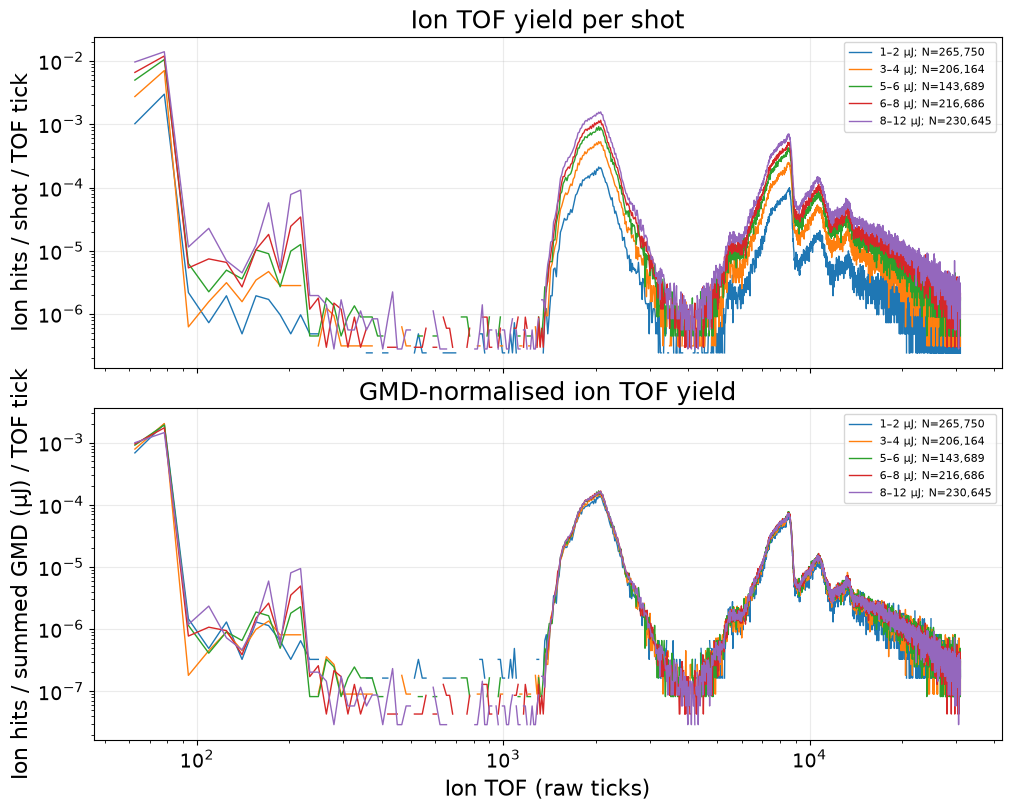

In [40]:

# --- Ion TOF spectra conditioned on GMD ---
RUN_ION_GMD_SPECTRA = True
ION_DENSITY_PER_TICK = True  # Correct for unequal logarithmic TOF-bin widths
ION_LOG_Y = True

if RUN_ION_GMD_SPECTRA:
    tof_widths = np.diff(ion_tof_edges)
    if np.any(tof_widths <= 0): raise ValueError('Invalid ion TOF bin widths')

    fig, axes = plt.subplots(2, 1, figsize=(10, 8), sharex=True, constrained_layout=True)

    for label in ION_GMD_BANDS:
        counts = ion_counts[label].sum(axis=0).astype(float)
        shots = int(ion_shots[label].sum())
        sum_gmd = float(ion_sum_gmd[label].sum())
        if shots == 0 or sum_gmd <= 0:
            print(f'GMD {label}: no valid shots or GMD; skipping')
            continue

        per_shot = counts / shots
        per_uJ = counts / sum_gmd
        if ION_DENSITY_PER_TICK:
            per_shot = per_shot / tof_widths
            per_uJ = per_uJ / tof_widths

        axes[0].plot(ion_tof_centres, np.where(per_shot > 0, per_shot, np.nan) if ION_LOG_Y else per_shot, lw=1, label=f'{label} µJ; N={shots:,}')
        axes[1].plot(ion_tof_centres, np.where(per_uJ > 0, per_uJ, np.nan) if ION_LOG_Y else per_uJ, lw=1, label=f'{label} µJ; N={shots:,}')

    for ax in axes:
        ax.set_xscale('log')
        if ION_LOG_Y: ax.set_yscale('log')
        ax.grid(alpha=0.25)
        ax.legend(fontsize=8)

    unit = ' / TOF tick' if ION_DENSITY_PER_TICK else ' / TOF bin'
    axes[0].set(ylabel='Ion hits / shot' + unit, title='Ion TOF yield per shot')
    axes[1].set(xlabel='Ion TOF (raw ticks)', ylabel='Ion hits / summed GMD (µJ)' + unit, title='GMD-normalised ion TOF yield')
    plt.show()


### Different bunch positions

early: shots=85,661, summed GMD=4.22e+05 µJ
middle: shots=81,206, summed GMD=4.02e+05 µJ
late: shots=48,259, summed GMD=2.36e+05 µJ


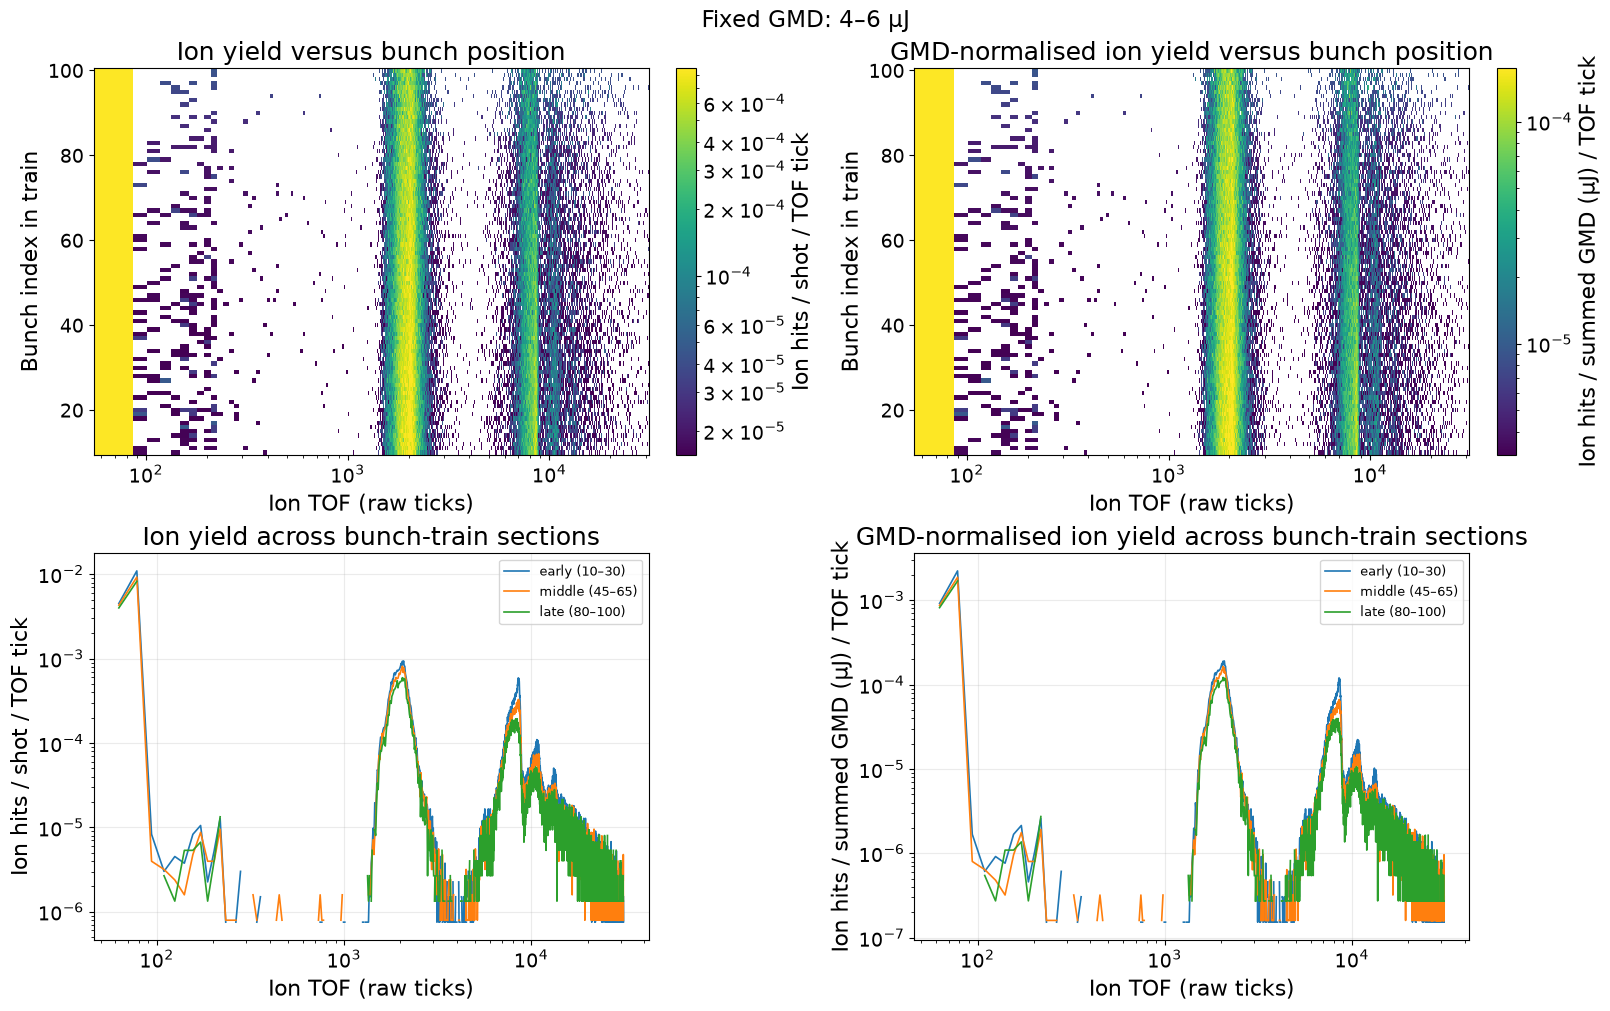

In [41]:
# --- Ion TOF versus bunch position, restricted to a fixed GMD range ---
from matplotlib.colors import LogNorm

ION_BUNCH_DENSITY_PER_TICK = True   # True: divide by TOF-bin width
ION_BUNCH_XSCALE = 'log'            # 'log' or 'linear'
ION_BUNCH_LINEOUT_YSCALE = 'log'    # 'log' or 'linear'

ion_group_counts = ion_counts['fixed'].astype(float)
ion_group_exposure = ion_sum_gmd['fixed'].astype(float)
ion_group_shots = ion_shots['fixed'].astype(float)

tof_widths = np.diff(ion_tof_edges)
if np.any(tof_widths <= 0):
    raise ValueError('Invalid ion TOF bin widths')

density_factor = tof_widths[None, :] if ION_BUNCH_DENSITY_PER_TICK else 1.0
unit_suffix = ' / TOF tick' if ION_BUNCH_DENSITY_PER_TICK else ' / TOF bin'

ion_per_shot = np.divide(
    ion_group_counts,
    ion_group_shots[:, None] * density_factor,
    out=np.full(ion_group_counts.shape, np.nan),
    where=(ion_group_shots[:, None] > 0),
)

ion_per_gmd = np.divide(
    ion_group_counts,
    ion_group_exposure[:, None] * density_factor,
    out=np.full(ion_group_counts.shape, np.nan),
    where=(ion_group_exposure[:, None] > 0),
)

def ion_positive_lognorm(values):
    positive = np.asarray(values)[np.isfinite(values) & (values > 0)]
    if not positive.size:
        raise ValueError('No positive ion histogram bins in selected GMD range')
    vmin, vmax = np.percentile(positive, [5, 99.5])
    return LogNorm(vmin=vmin, vmax=max(vmax, vmin * (1 + 1e-6)))

fig, axes = plt.subplots(2, 2, figsize=(16, 10), constrained_layout=True)
bunch_edges = np.arange(ion_n_bunch + 1) - 0.5

for ax, z, title, label in (
    (axes[0, 0], ion_per_shot, 'Ion yield versus bunch position', 'Ion hits / shot' + unit_suffix),
    (axes[0, 1], ion_per_gmd, 'GMD-normalised ion yield versus bunch position', 'Ion hits / summed GMD (µJ)' + unit_suffix),
):
    img = ax.pcolormesh(
        ion_tof_edges,
        bunch_edges,
        np.ma.masked_less_equal(z, 0),
        norm=ion_positive_lognorm(z),
        shading='auto',
    )
    ax.set(
        xscale=ION_BUNCH_XSCALE,
        xlabel='Ion TOF (raw ticks)',
        ylabel='Bunch index in train',
        ylim=(ION_BUNCH_START - 0.5, ion_n_bunch - 0.5),
        title=title,
    )
    fig.colorbar(img, ax=ax, label=label)

for name, (lo, hi) in ION_BUNCH_GROUPS.items():
    idx = np.arange(max(lo, ION_BUNCH_START), min(hi + 1, ion_n_bunch))
    if not idx.size:
        raise ValueError(f'Bunch group {name} is outside the selected range')

    counts = ion_group_counts[idx].sum(axis=0)
    exposure = ion_group_exposure[idx].sum()
    shots = ion_group_shots[idx].sum()

    if shots <= 0 or exposure <= 0 or counts.sum() == 0:
        print(f'{name}: no usable ion counts; skipping')
        continue

    if ION_BUNCH_DENSITY_PER_TICK:
        line_per_shot = counts / shots / tof_widths
        line_per_gmd = counts / exposure / tof_widths
    else:
        line_per_shot = counts / shots
        line_per_gmd = counts / exposure

    axes[1, 0].plot(
        ion_tof_centres,
        np.where(line_per_shot > 0, line_per_shot, np.nan),
        lw=1.2,
        label=f'{name} ({lo}–{hi})',
    )
    axes[1, 1].plot(
        ion_tof_centres,
        np.where(line_per_gmd > 0, line_per_gmd, np.nan),
        lw=1.2,
        label=f'{name} ({lo}–{hi})',
    )

    print(f'{name}: shots={shots:,.0f}, summed GMD={exposure:.3g} µJ')

for ax, ylabel, title in (
    (axes[1, 0], 'Ion hits / shot' + unit_suffix, 'Ion yield across bunch-train sections'),
    (axes[1, 1], 'Ion hits / summed GMD (µJ)' + unit_suffix, 'GMD-normalised ion yield across bunch-train sections'),
):
    ax.set(
        xscale=ION_BUNCH_XSCALE,
        yscale=ION_BUNCH_LINEOUT_YSCALE,
        xlabel='Ion TOF (raw ticks)',
        ylabel=ylabel,
        title=title,
    )
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)

fig.suptitle(f'Fixed GMD: {ION_FIXED_GMD_RANGE[0]:g}–{ION_FIXED_GMD_RANGE[1]:g} µJ')
plt.show()

## 7. Optional residual-gas subtraction
Residual-gas clean cells 17/24: signal, scaled measured residual gas and their difference.
This is not a detector-dark or closed-shutter correction. Background is never opened when
subtraction is disabled. For electron-yield display, all three curves use the **same
signed subtracted-spectrum area**, preserving the visual subtraction identity.


In [28]:
if SUBTRACT_BACKGROUND:
    if APPLY_FEL_MASK: raise ValueError('Use the main spectrum for FEL-filtered subtraction; this panel uses aggregates')
    signal, scaled_background, subtracted = corrected_components(selected_stats, background_stats)
    fig, ax = plt.subplots(figsize=(10,5),constrained_layout=True)
    area = np.sum(subtracted[tof_crop_mask(agg.tof_edges)]) if NORMALISE == 'electron_yield' else 1.0
    if not np.isfinite(area) or area == 0: raise ValueError('Invalid signed subtracted area')
    for label, values in [('signal',signal), ('scaled residual gas',scaled_background), ('signal − residual gas',subtracted)]:
        x, y = axis_data(agg.tof_edges, values/area, 'raw' if NORMALISE == 'electron_yield' else NORMALISE)
        ax.stairs(y,x,label=label,lw=1.1)
    format_spectrum_axis(ax)
    ax.axhline(0,color='k',lw=.6)
    ax.legend()
    plt.show()


## 8. 2D spectral maps — optional multi-file analysis
Only this section combines arbitrary acquisitions. Set `MAP_FILES` explicitly and provide
nominal incident energies via `MAP_ENERGIES` when not stored in metadata. No filename
parsing or nearest-energy substitution. Repeated energies combine **counts, summed GMD
and shot counts before division**, with exact common TOF edges. Measured backgrounds
are specified per file; missing backgrounds fail when subtraction is selected.

Alternative: the selected run's native delay-versus-KE map. Its rows remain distinct;
`z_edges` stay in the stored stage coordinate unless an independently validated affine
conversion is supplied. No smoothing/interpolation. Empty exposure rows remain NaN.


In [29]:
def half_step_edges(values):
    values = np.asarray(values, dtype=float)
    if values.size == 1:
        return np.array([values[0] - 0.5, values[0] + 0.5])
    if np.any(np.diff(values) <= 0):
        raise ValueError("Map energies must be strictly increasing within one scan family")
    midpoints = 0.5 * (values[:-1] + values[1:])
    return np.concatenate(
        [[2 * values[0] - midpoints[0]], midpoints, [2 * values[-1] - midpoints[-1]]]
    )


In [30]:
RUN_PHOTON_MAP = False
MAP_FILES = []  # [Path('/.../runA_aggregates.h5'), Path('/.../runB_aggregates.h5'), ...]
MAP_ENERGIES = {}  # {Path('/.../runA_aggregates.h5'): incident_eV}; repeated values allowed.
MAP_BACKGROUNDS = {}  # {signal_path: matching_background_path}; required if subtraction enabled.
MAP_SUBTRACT_BACKGROUND = SUBTRACT_BACKGROUND
MAP_NORMALISE = 'per_uJ'  # 'raw', 'per_shot', 'per_uJ', 'electron_yield'
MAP_VMIN, MAP_VMAX = None, None
INVERT_PHOTON_AXIS = True
RUN_DELAY_MAP = False
# Optional conversion: delay_fs = (stored_z - zero_stage) * fs_per_stage_unit.
DELAY_ZERO_STAGE = None
FS_PER_STAGE_UNIT = None


def mapping_value(mapping, path):
    matches = [v for k,v in mapping.items() if Path(k).resolve() == Path(path).resolve()]
    if len(matches) > 1: raise ValueError(f'Duplicate map entries: {path}')
    return matches[0] if matches else None


def incident_energy(a, path):
    value = mapping_value(MAP_ENERGIES, path)
    if value is None:
        for key in ('photon_energy_eV', 'incident_energy_eV', 'nominal_energy_eV'):
            if key in a.metadata:
                value = a.metadata[key]
                break
    if value is None or np.ndim(value) != 0 or not np.isfinite(float(value)):
        raise ValueError(f'Set MAP_ENERGIES for {path}; no unambiguous scalar metadata')
    return float(value)


if APPLY_FEL_MASK and (RUN_PHOTON_MAP or RUN_DELAY_MAP):
    raise ValueError('Aggregate photon/delay maps cannot be FEL-filtered; disable these optional maps')

map_rows = []
if RUN_PHOTON_MAP:
    if not MAP_FILES: raise ValueError('Set MAP_FILES explicitly')
    if len({Path(p).resolve() for p in MAP_FILES}) != len(MAP_FILES):
        raise ValueError('Duplicate map input path would double count an acquisition')
    grouped = {}
    map_tof_edges = None
    for path in MAP_FILES:
        a = load_aggregates_etof(path)
        if map_tof_edges is None: map_tof_edges = a.tof_edges
        if not np.array_equal(a.tof_edges,map_tof_edges): raise ValueError('Map TOF grids differ')
        energy = incident_energy(a,path)
        st = aggregate_stats(a)
        bgpath = mapping_value(MAP_BACKGROUNDS,path)
        bg = load_background_for(a,bgpath) if MAP_SUBTRACT_BACKGROUND else None
        group = grouped.setdefault(energy, {'signal':[], 'background':{}})
        group['signal'].append(st)
        if bg is not None:
            # One background acquisition used repeatedly is counted only once.
            group['background'][str(Path(bgpath).resolve())] = bg
    def combine_sums(stats):
        return {k: np.sum([s[k] for s in stats],axis=0) for k in ('counts','sum_gmd','shots')}
    for energy, group in sorted(grouped.items()):
        st = combine_sums(group['signal'])
        bg = combine_sums(list(group['background'].values())) if MAP_SUBTRACT_BACKGROUND else None
        _, _, values = corrected_components(st,bg,MAP_NORMALISE)
        map_rows.append(dict(energy=energy,stats=st,background=bg,spectrum=values))
        print(energy,'eV:',st['shots'],'shots;',st['sum_gmd'],'uJ')
    x,z = axis_data(map_tof_edges,np.stack([r['spectrum'] for r in map_rows]),MAP_NORMALISE)
    energies = np.array([r['energy'] for r in map_rows])
    fig,ax = plt.subplots(figsize=(10,7),constrained_layout=True)
    im=ax.pcolormesh(x,half_step_edges(energies),z,shading='flat',cmap='viridis',vmin=MAP_VMIN,vmax=MAP_VMAX)
    format_spectrum_axis(ax,MAP_NORMALISE)
    ax.set_ylabel('incident photon energy (eV)')
    if INVERT_PHOTON_AXIS: ax.invert_yaxis()
    fig.colorbar(im,ax=ax,label=spectrum_units(MAP_NORMALISE))
    plt.show()

if RUN_DELAY_MAP:
    if agg.z_edges is None: raise ValueError('Selected aggregate has no delay axis')
    ds=aggregate_stats(agg,selection='integrate',keep_delay=True)
    delay_bg=load_background_for(agg,BACKGROUND_FILE) if MAP_SUBTRACT_BACKGROUND else None
    _,_,values=corrected_components(ds,delay_bg,MAP_NORMALISE)
    x,z=axis_data(agg.tof_edges,values,MAP_NORMALISE)
    delay_edges=agg.z_edges.copy()
    ylabel='delay/stage coordinate (stored z units; verify acquisition metadata)'
    if DELAY_ZERO_STAGE is not None or FS_PER_STAGE_UNIT is not None:
        if DELAY_ZERO_STAGE is None or FS_PER_STAGE_UNIT is None or FS_PER_STAGE_UNIT == 0:
            raise ValueError('Supply both validated delay conversion parameters')
        delay_edges=(delay_edges-DELAY_ZERO_STAGE)*FS_PER_STAGE_UNIT
        ylabel='pump–probe delay (fs)'
        if delay_edges[0] > delay_edges[-1]: delay_edges,z=delay_edges[::-1],z[::-1]
    print('Delay populations:', ds['shots'], '| summed GMD:', ds['sum_gmd'])
    fig,ax=plt.subplots(figsize=(10,7),constrained_layout=True)
    im=ax.pcolormesh(x,delay_edges,z,shading='flat',cmap='viridis',vmin=MAP_VMIN,vmax=MAP_VMAX)
    format_spectrum_axis(ax,MAP_NORMALISE)
    ax.set_ylabel(ylabel)
    fig.colorbar(im,ax=ax,label=spectrum_units(MAP_NORMALISE))
    plt.show()


## 9. Integrated electron yields
GMD-resonance clean cell 21 (fractional overlap) and residual-gas original cell 92
(signed selected yield). Total counts cover the **entire stored TOF histogram**, independently
of the display crop; individual KE windows use native-bin overlap weights, with no
Jacobian. Shot diagnostics below distinguish all positive stored hits from this histogram total.
Window fractions use the full signed total; overlapping windows are not disjoint contributions.
No uncertainty is invented from aggregate means alone. Fine-bin empirical SEM below uses
`std(ddof=0)/sqrt(N)`; historical response-fit errors use a fractional Poisson approximation,
not a train-correlated uncertainty model or confidence in physical saturation.


In [31]:
RUN_ENERGY_YIELD_CURVES = False  # Uses only map_rows from the optional photon map.
if RUN_ENERGY_YIELD_CURVES:
    if not map_rows: raise ValueError('Run the photon map section with explicit MAP_FILES first')
    fig,axes=plt.subplots(1,2,figsize=(12,5),constrained_layout=True)
    for ax,mode in zip(axes,('per_shot','per_uJ')):
        traces=[integrated_yields(r['stats'],r['background'],map_tof_edges)[mode] for r in map_rows]
        for label in traces[0]:
            ax.plot([r['energy'] for r in map_rows],[t[label] for t in traces],'o-',ms=3,label=label)
        ax.set_xlabel('incident photon energy (eV)')
        ax.set_ylabel('electrons / shot' if mode=='per_shot' else 'electrons / uJ')
        ax.grid(alpha=.25)
        ax.legend(fontsize=8)
    plt.show()


## 10. Optional two-run bunch comparisons
Local second acquisition inputs are used only here. The selected run's ordinary spectra
and other diagnostics remain independent. Cells **11 and 13** from the working Bunch
investigations notebook are retained, including their numerical calculations and plotting.
Supply compatible calibration/TOF units and explicit labels identifying the two incident
energies; their scientific comparability cannot be established from equal array lengths.


In [32]:
RUN_TWO_RUN_BUNCH = True
SECOND_BUNCH_RUN_FILE =  INPUT_ROOT / 'glycine_WL_scan_271.0eV_aggregates_etof1.h5'
SECOND_BUNCH_SHOT_FILE = None  # None: its recorded input_h5.
BUNCH_COMPARISON_LABELS = ['270.0 eV', '271.0 eV']  # Required pair, e.g. ['selected energy (eV)', 'comparison energy (eV)'].
if RUN_TWO_RUN_BUNCH:
    if not HAS_CALIBRATION: raise ValueError('Bunch comparisons require calibration')
    if SECOND_BUNCH_RUN_FILE is None or BUNCH_COMPARISON_LABELS is None or len(BUNCH_COMPARISON_LABELS)!=2:
        raise ValueError('Set the second aggregate and two explicit incident-energy labels')
    if Path(SECOND_BUNCH_RUN_FILE).resolve()==Path(RUN_FILE).resolve():
        raise ValueError('Choose a distinct second acquisition')
    second_bunch_agg=load_aggregates_etof(SECOND_BUNCH_RUN_FILE)
    energy_datasets=[
        bunch_dataset(agg,SHOT_FILE,BUNCH_COMPARISON_LABELS[0],'#1f77b4'),
        bunch_dataset(second_bunch_agg,SECOND_BUNCH_SHOT_FILE,BUNCH_COMPARISON_LABELS[1],'#ff7f0e')]
    if not np.array_equal(energy_datasets[0]['bunch_diag']['bunch'],energy_datasets[1]['bunch_diag']['bunch']):
        raise ValueError('Selected original bunch slots differ')


Input: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_WL_scan_271.0eV_aggregates_etof1.h5 | attributes: {'chunk_size': np.int64(200), 'config': np.int64(1), 'config_path': 'analysis/configs/aggregates_config1_5June_energy_scan_etof1.py', 'input_h5': '/asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_WL_scan_271.0eV.h5', 'mode': 'spectral', 'n_skipped_gmd_nan': np.int64(0), 'n_skipped_gmd_oor': np.int64(149), 'trim_end': np.int64(3), 'trim_start': np.int64(3)}
  D (4, 5000) float64 | attrs: {}
  G (4,) float64 | attrs: {}
  n_per_bin (4,) int64 | attrs: {}
  gmd_edges (5,) float64 | attrs: {}
  tof_edges (5001,) float64 | attrs: {}
Detected axes: GMD,TOF | run metadata: {} | populated / empty bins: 4 0
Input: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_271.5eV.h5 | attributes: {}
  gmd (19938, 101) float32 | attrs: {}
  tofs_e (19938, 101, 50) uint32 | attrs: {}
  z (19938, 101) float32 | attrs: {}
  betwe


KE 160-180 eV
  270.0 eV
    total electrons: 21187
    total summed GMD: 8.92582e+06 uJ
    median electrons/GMD over bunch slots: 0.00237932
  271.0 eV
    total electrons: 113049
    total summed GMD: 1.4853e+06 uJ
    median electrons/GMD over bunch slots: 0.0764055


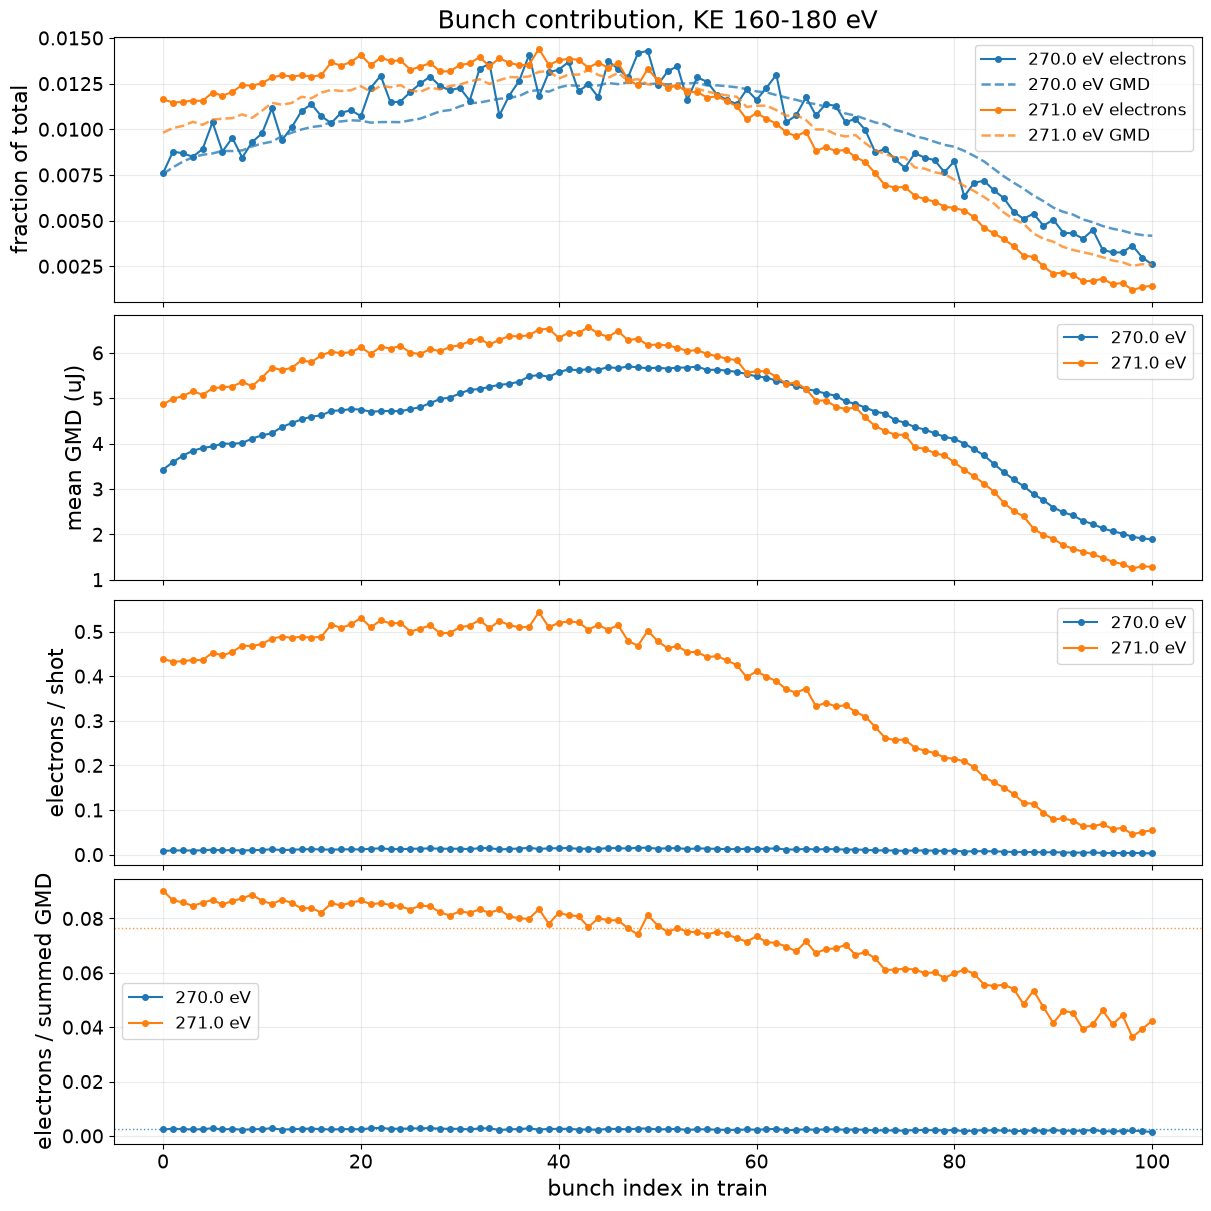


KE 180-200 eV
  270.0 eV
    total electrons: 26944
    total summed GMD: 8.92582e+06 uJ
    median electrons/GMD over bunch slots: 0.00300235
  271.0 eV
    total electrons: 57919
    total summed GMD: 1.4853e+06 uJ
    median electrons/GMD over bunch slots: 0.0384332


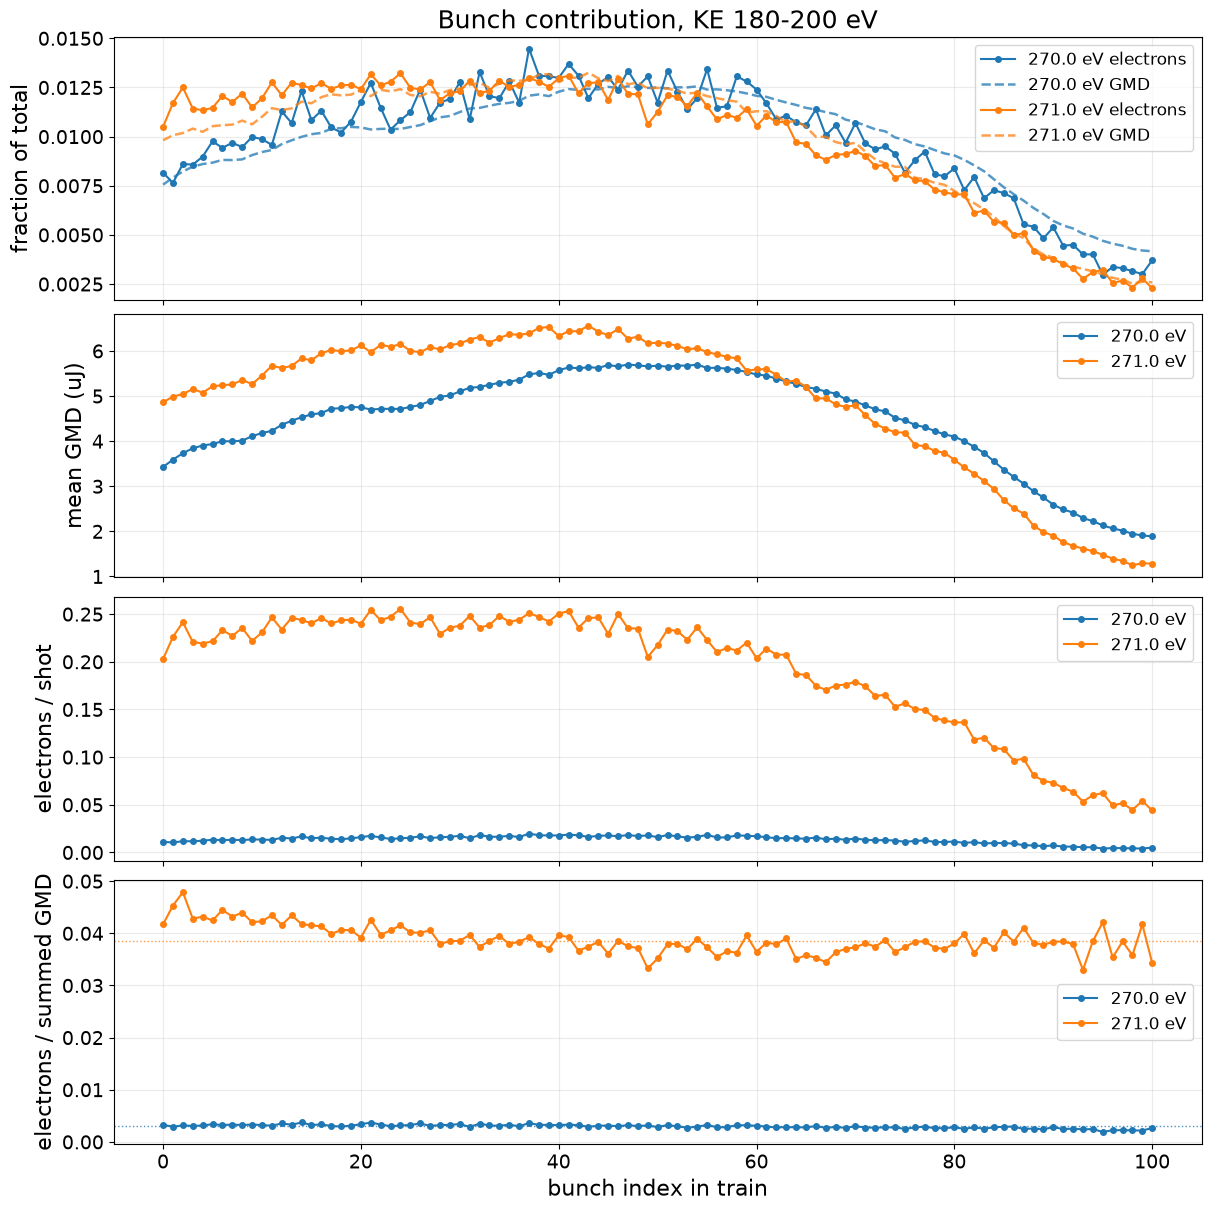


KE 200-220 eV
  270.0 eV
    total electrons: 45882
    total summed GMD: 8.92582e+06 uJ
    median electrons/GMD over bunch slots: 0.00514531
  271.0 eV
    total electrons: 61195
    total summed GMD: 1.4853e+06 uJ
    median electrons/GMD over bunch slots: 0.0415413


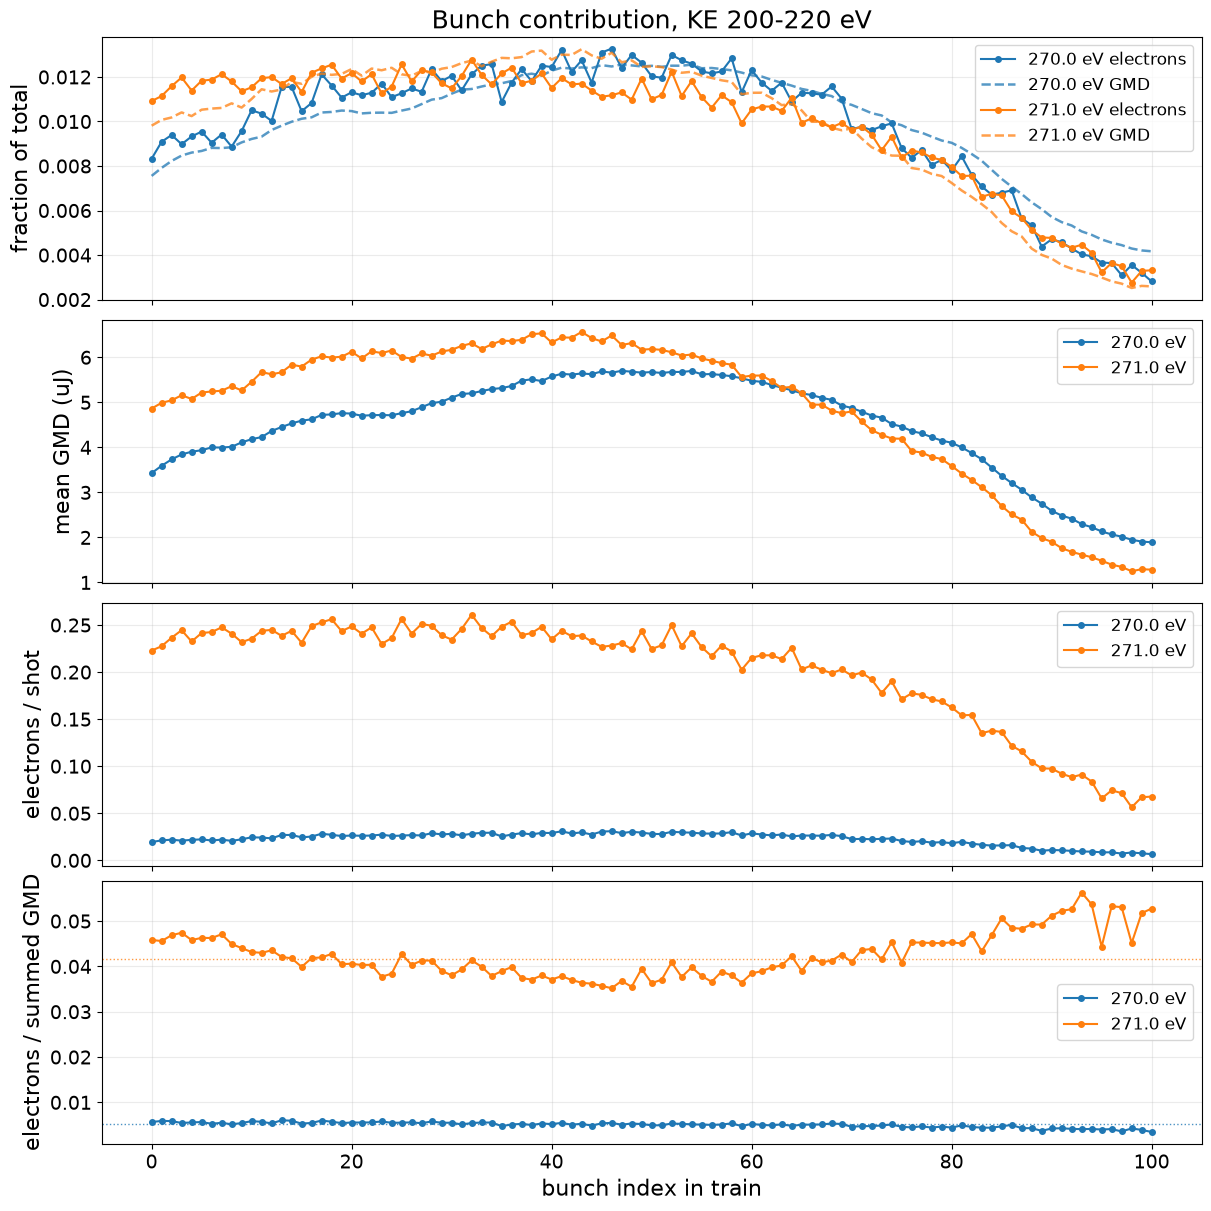


KE 220-240 eV
  270.0 eV
    total electrons: 146011
    total summed GMD: 8.92582e+06 uJ
    median electrons/GMD over bunch slots: 0.0163457
  271.0 eV
    total electrons: 92495
    total summed GMD: 1.4853e+06 uJ
    median electrons/GMD over bunch slots: 0.0596952


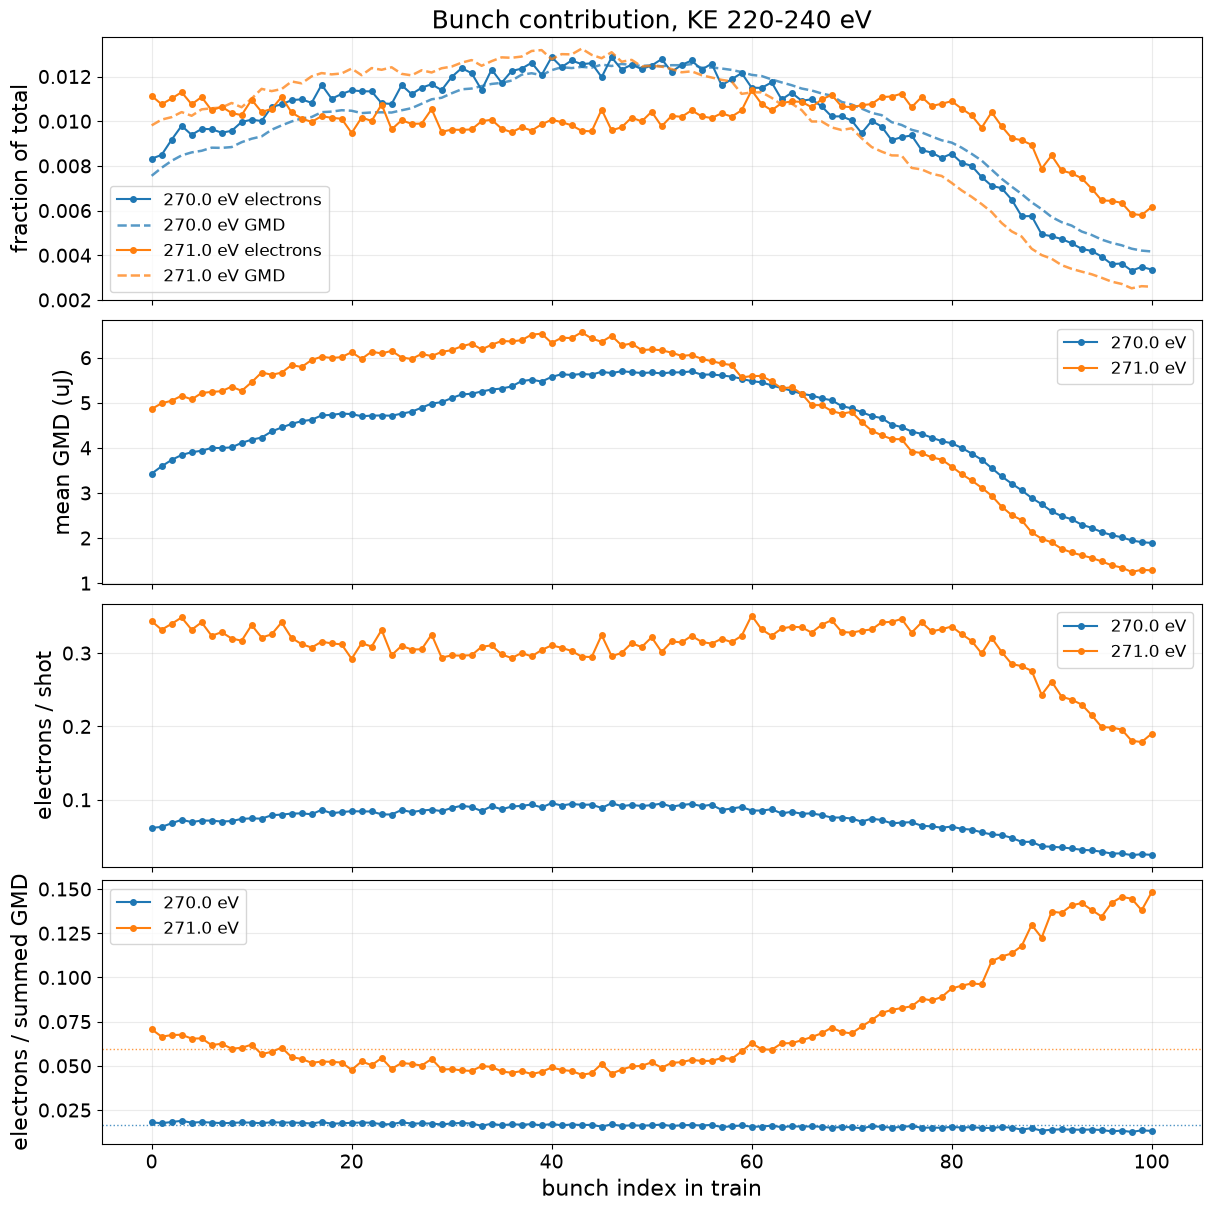


KE 240-260 eV
  270.0 eV
    total electrons: 162571
    total summed GMD: 8.92582e+06 uJ
    median electrons/GMD over bunch slots: 0.018159
  271.0 eV
    total electrons: 203566
    total summed GMD: 1.4853e+06 uJ
    median electrons/GMD over bunch slots: 0.136152


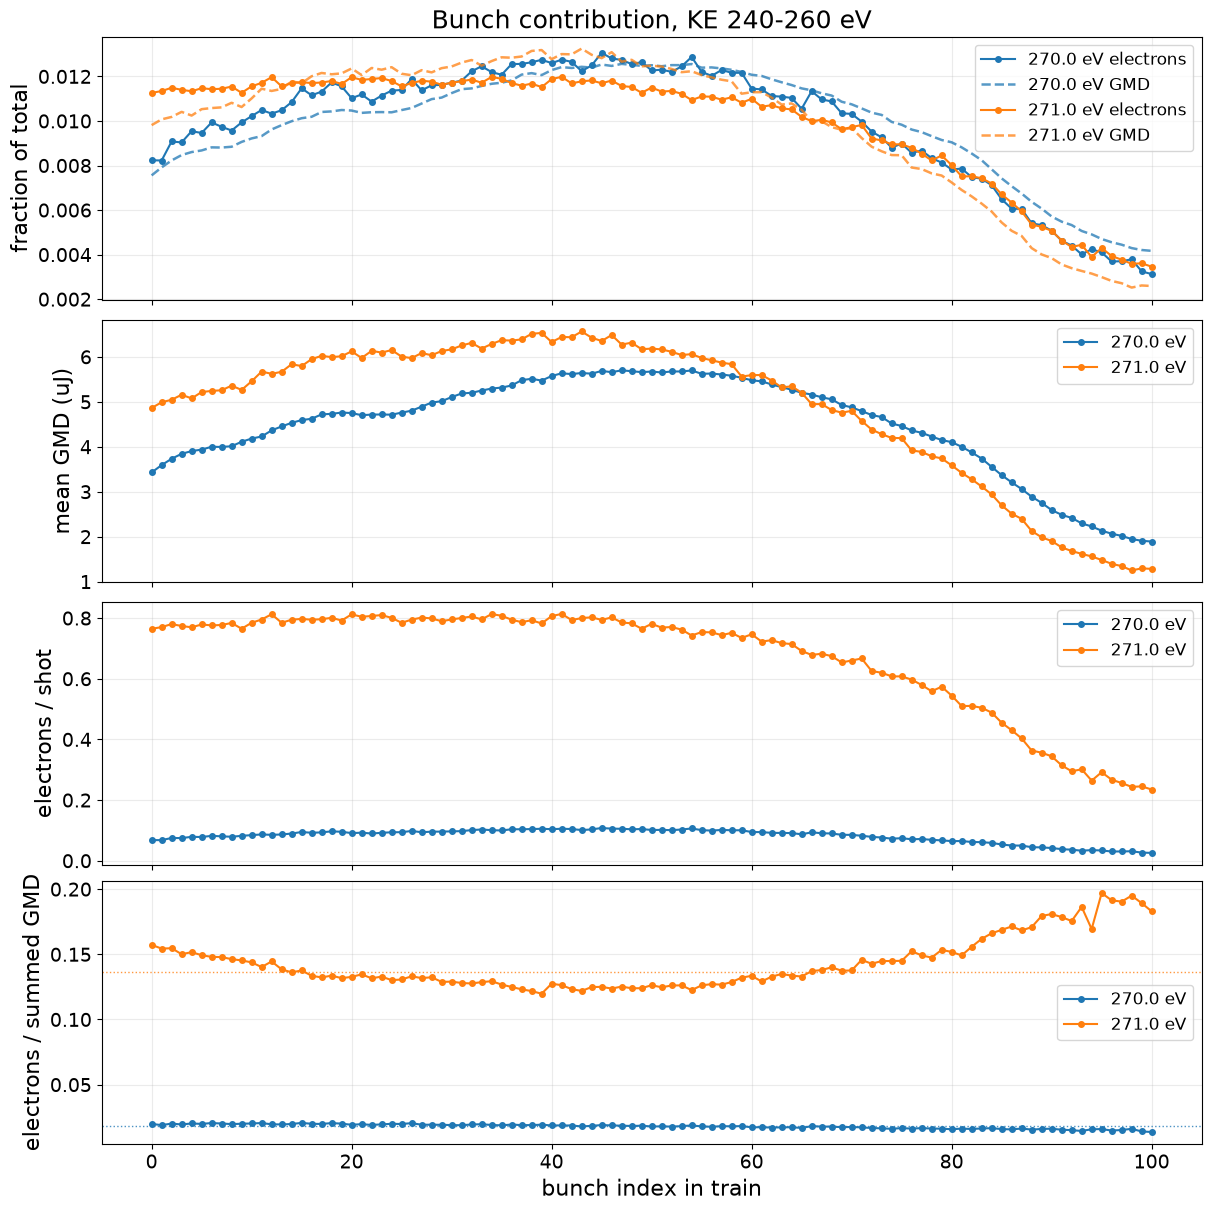

In [33]:
if RUN_TWO_RUN_BUNCH:
    import matplotlib.pyplot as plt
    import numpy as np

    # --- Bunch contribution, comparing selected incident energies ---
    plt.rcParams.update({
        "font.size": 14,
        "axes.labelsize": 16,
        "axes.titlesize": 18,
        "xtick.labelsize": 14,
        "ytick.labelsize": 14,
        "legend.fontsize": 12,
    })

    # High-contrast color palette fallback (Deep Blue, Orange, Green, Purple, Red)
    PALETTE = ["#1f77b4", "#ff7f0e", "#2ca02c", "#9467bd", "#d62728"]

    for ke_range in KE_RANGES:
        fig, axes = plt.subplots(4, 1, figsize=(12, 12), sharex=True, constrained_layout=True)
        print(f"\nKE {ke_range[0]}-{ke_range[1]} eV")

        for idx, ds in enumerate(energy_datasets):
            bd = ds["bunch_diag"]
            stats = bd["stats"]["all"][ke_range]
            good = stats["shots"] >= MIN_SHOTS_PER_BUNCH
            b = bd["bunch"][good]

            total_electrons = np.nansum(stats["electrons"])
            total_gmd = np.nansum(stats["sum_gmd"])

            with np.errstate(invalid="ignore", divide="ignore"):
                electron_fraction = stats["electrons"][good] / total_electrons
                gmd_fraction = stats["sum_gmd"][good] / total_gmd

            color = ds.get("color", PALETTE[idx % len(PALETTE)])

            # Plot 1: Solid line + markers for electrons; markerless dashed line for GMD
            axes[0].plot(b, electron_fraction, "o-", color=color, ms=4, lw=1.5, label=f"{ds['label']} electrons")
            axes[0].plot(b, gmd_fraction, "--", color=color, lw=1.8, alpha=0.75, label=f"{ds['label']} GMD")

            # Plots 2-4: Standard solid line with markers
            axes[1].plot(b, stats["mean_gmd"][good], "o-", color=color, ms=4, lw=1.5, label=ds["label"])
            axes[2].plot(b, stats["electrons_per_shot"][good], "o-", color=color, ms=4, lw=1.5, label=ds["label"])

            median_e_gmd = np.nanmedian(stats["electrons_per_gmd"][good])
            axes[3].plot(b, stats["electrons_per_gmd"][good], "o-", color=color, ms=4, lw=1.5, label=ds["label"])
            axes[3].axhline(median_e_gmd, color=color, lw=1.0, ls=":", alpha=0.8)

            print(f"  {ds['label']}\n    total electrons: {total_electrons:.6g}\n    total summed GMD: {total_gmd:.6g} uJ")
            print(f"    median electrons/GMD over bunch slots: {median_e_gmd:.6g}")

        # Formatting axes
        titles_labels = [
            ("fraction of total", f"Bunch contribution, KE {ke_range[0]}-{ke_range[1]} eV"),
            ("mean GMD (uJ)", None),
            ("electrons / shot", None),
            ("electrons / summed GMD", None)
        ]

        for ax, (ylabel, title) in zip(axes, titles_labels):
            ax.set_ylabel(ylabel)
            if title: 
                ax.set_title(title)
            ax.grid(alpha=0.25)
            ax.legend()
            ax.tick_params(axis="both", which="major", labelsize=14)

        axes[3].set_xlabel("bunch index in train")
        plt.show()


Input: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_271.5eV.h5 | attributes: {}
  gmd (19938, 101) float32 | attrs: {}
  tofs_e (19938, 101, 50) uint32 | attrs: {}
  z (19938, 101) float32 | attrs: {}
  between_tdc_files (19938,) bool | attrs: {}
Shot source: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_delay_scan_150C_271.5eV.h5 | source rows: 19938 | original bunch indices: (0, 101) | z [lo,hi): (np.float64(-15000.0), np.float64(91000.0)) | GMD: (None, None) | preview source-row cap: None
Train trim: 3 3
Input: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_WL_scan_271.0eV.h5 | attributes: {}
  gmd (3004, 101) float32 | attrs: {}
  tofs_e (3004, 101, 50) uint32 | attrs: {}
  z (3004, 101) float32 | attrs: {}
  between_tdc_files (3004,) bool | attrs: {}
Shot source: /asap3/flash/gpfs/fl24/2026/data/11022188/processed/combined/glycine_WL_scan_271.0eV.h5 | source rows: 3004 | original bunch indices: (0

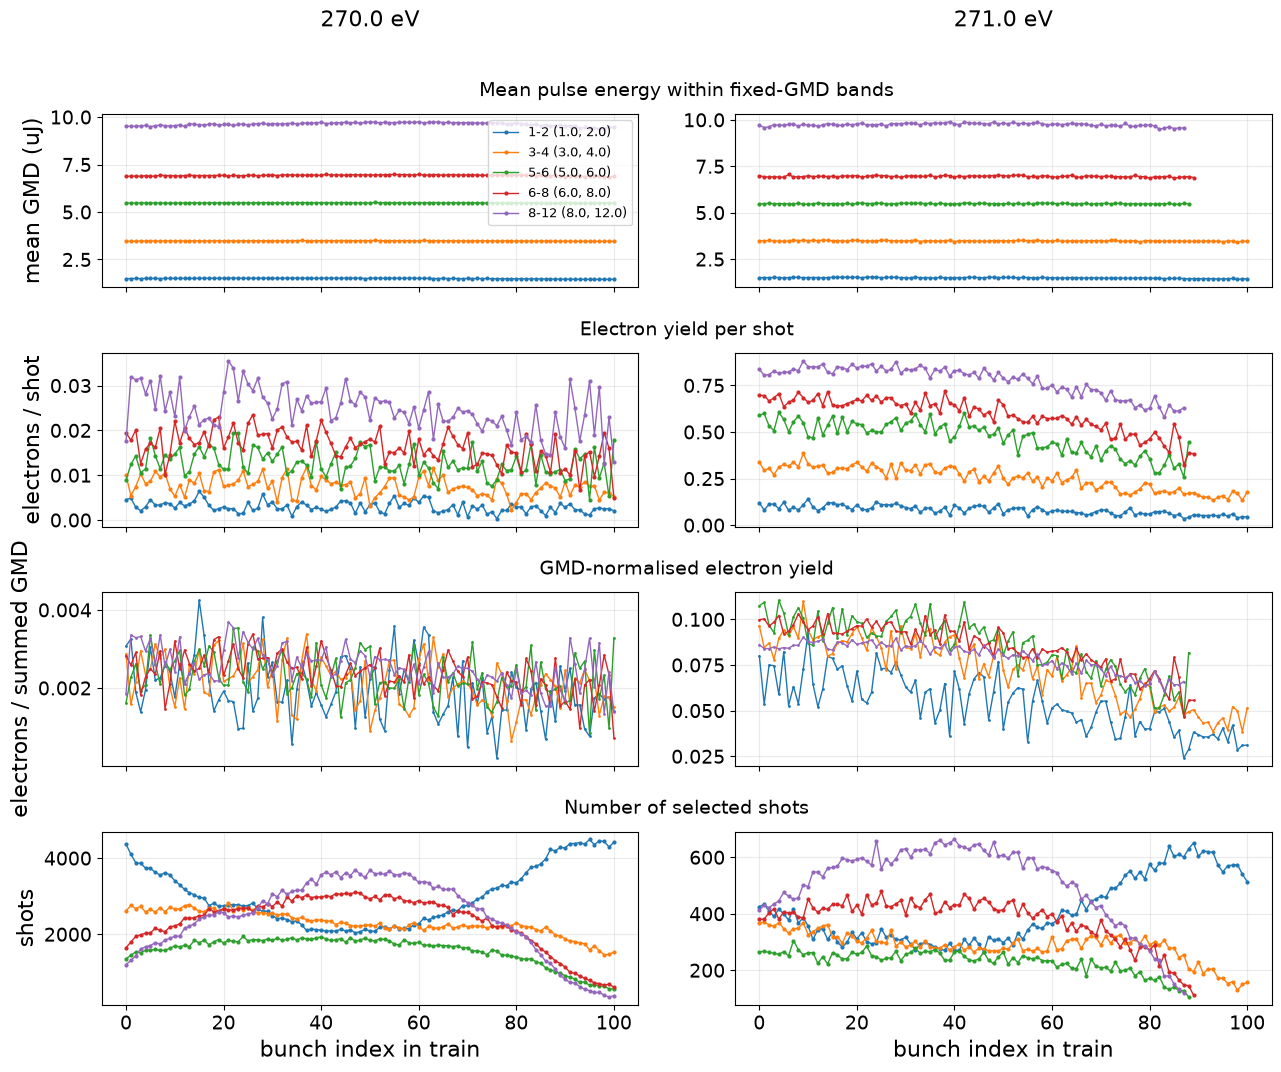

In [34]:
if RUN_TWO_RUN_BUNCH:
    # --- Fixed-GMD comparison by bunch for two incident energies ---
    BUNCH_GMD_RANGES = {
        '1-2': (1.0, 2.0), '3-4': (3.0, 4.0), '5-6': (5.0, 6.0),
        '6-8': (6.0, 8.0), '8-12': (8.0, 12.0)
    }
    PLOT_KE_RANGE = KE_RANGES[0]

    # Recalculate the diagnostics using the GMD ranges selected in this cell.
    energy_datasets = [
        bunch_dataset(agg, SHOT_FILE, BUNCH_COMPARISON_LABELS[0], '#1f77b4'),
        bunch_dataset(second_bunch_agg, SECOND_BUNCH_SHOT_FILE, BUNCH_COMPARISON_LABELS[1], '#ff7f0e')
    ]

    if len(energy_datasets) != 2:
        raise ValueError(f"Expected exactly two datasets in energy_datasets, found {len(energy_datasets)}")

    GMD_LABELS = [label for label in energy_datasets[0]["bunch_diag"]["gmd_ranges"] if label != "all"]

    for ds in energy_datasets[1:]:
        labels = [label for label in ds["bunch_diag"]["gmd_ranges"] if label != "all"]
        if labels != GMD_LABELS:
            raise ValueError("The two datasets do not contain the same fixed-GMD groups.")

    plot_rows = [
        ("mean_gmd", "Mean pulse energy within fixed-GMD bands", "mean GMD (uJ)"),
        ("electrons_per_shot", "Electron yield per shot", "electrons / shot"),
        ("electrons_per_gmd", "GMD-normalised electron yield", "electrons / summed GMD"),
        ("shots", "Number of selected shots", "shots"),
    ]

    n_cols = len(energy_datasets)
    fig, axes = plt.subplots(len(plot_rows), n_cols, figsize=(13, 11), sharex=True)

    gmd_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

    for col, ds in enumerate(energy_datasets):
        bd = ds["bunch_diag"]
        bunch_ds = bd["bunch"]

        print(f"\n{ds['label']}, KE {PLOT_KE_RANGE[0]}-{PLOT_KE_RANGE[1]} eV")

        for i_label, label in enumerate(GMD_LABELS):
            st = bd["stats"][label][PLOT_KE_RANGE]
            good = (
                (st["shots"] >= MIN_SHOTS_PER_BUNCH)
                & np.isfinite(st["mean_gmd"])
                & np.isfinite(st["electrons_per_shot"])
                & np.isfinite(st["electrons_per_gmd"])
            )

            colour = gmd_colors[i_label % len(gmd_colors)]
            gmd_range = bd["gmd_ranges"][label]

            axes[0, col].plot(bunch_ds[good], st["mean_gmd"][good], "o-", ms=2, lw=1.0, color=colour, label=f"{label} {gmd_range}")
            axes[1, col].plot(bunch_ds[good], st["electrons_per_shot"][good], "o-", ms=2, lw=1.0, color=colour, label=label)
            axes[2, col].plot(bunch_ds[good], st["electrons_per_gmd"][good], "o-", ms=1, lw=1.0, color=colour, label=label)
            axes[3, col].plot(bunch_ds[good], st["shots"][good], "o-", ms=2, lw=1.0, color=colour, label=label)

        for row, (_, _, ylabel) in enumerate(plot_rows):
            ax = axes[row, col]
            if col == 0:
                ax.set_ylabel(ylabel)
            ax.grid(alpha=0.25)

        axes[-1, col].set_xlabel("bunch index in train")

        if col == 0:
            axes[0, col].legend(fontsize=9)

    fig.subplots_adjust(left=0.08, right=0.98, bottom=0.07, top=0.88, hspace=0.38, wspace=0.18)
    fig.canvas.draw()

    # Incident energies: highest-level labels, above all row titles.
    for col, ds in enumerate(energy_datasets):
        pos = axes[0, col].get_position()
        fig.text(0.5 * (pos.x0 + pos.x1), 0.975, ds["label"], ha="center", va="top", fontsize=16)

    # Titles centred above each row.
    for row, (_, row_title, _) in enumerate(plot_rows):
        left = axes[row, 0].get_position().x0
        right = axes[row, -1].get_position().x1
        top = max(axes[row, col].get_position().y1 for col in range(n_cols))
        fig.text(0.5 * (left + right), top + 0.012, row_title, ha="center", va="bottom", fontsize=14)

    plt.show()


## Provenance and limits

All cell indices below are zero-based (Markdown included). Historical source commit:
`b0508879511c191fad2f48df86da6f9e9e53e9ec`, branch `cfg1-xas-tid-start-sections`.
Source files were read without imports, branch changes or writes.

| Source notebook in `analysis/post/` | Cells | Reuse / adaptation |
|---|---|---|
| `residual_gas_background_clean.ipynb` | 1–3, 17–18, 20, 24 | lightweight container, sums, native KE widths, background scaling/subtraction, map/lineout conventions; explicit paths replace scan filename discovery |
| `delay_scan_loaders_and_gmd_diagnostics_clean.ipynb` | 5, 14 | `D[GMD,z,TOF]` reconstruction and static background exposure; explicit delay selection and shape checks replace scan-wide pipeline |
| `GMD resonance search - clean.ipynb` (working tree) | 14–16, 21 | fine shot counts, bin means/SEM, native KE overlap; one source replaces scan row lookup |
| same (working tree) | 8 (`apply_cb_to_gmd` only), 28 | existing uncorrected response path and weighted linear fit; `cb=None`; no learned bunch correction |
| `Auger high GMD.ipynb` | 3, 8 | chunked GMD-band histogram sums and KE-density spectra; one selected source replaces nearest-energy lookup |
| `Bunch investigations.ipynb` (working tree) | 2, 7, **11, 13, 17** | direct bunch counting and unchanged numerical plot cells; one-run default, local second-run comparison |
| Previous notebook 05 (backup) | 2, 5, 7, 10, 23 | local cache setup, calibration loader, container, half-step map edges, KE overlap |

Adaptations: input/shape validation; explicit delay integration/range and native-edge GMD
selection; sum underlying repeated-acquisition statistics; skip covariance reads; shared
shot selection masks; bound hit reads by train chunks; optional source-row preview cap;
chunk the small retained bunch GMD matrix instead of one full read. Scalar per-shot arrays
and selected GMD distributions still scale with shot count. All plots are editable Python.

Historical methods differ: fine controls count all positive hits and use empirical SEM;
bunch controls count hits directly by calibrated KE; aggregate windows and response fits
use fractional native histogram-bin weights. We preserve these distinctions. Aggregate
uncertainties/correlations are unavailable here; no aggregate error bars are fabricated.
Raw, shot and GMD background scaling are distinct choices. Shared-background/training
correlations and GMD uncertainty are not included in the historical Poisson response errors.
No new physical model or OD interpretation is introduced.

Only spectral and time-resolved configuration-1 eTOF layouts above are supported. Internal
nominal-energy axes, differently aligned shot arrays, incompatible histogram grids, absent
source metadata or unresolved calibration/delay units require explicit attention. The saved
historical calibration's reported validity interval is printed; display/KE windows outside it
are extrapolation and require acquisition-specific validation. `SHOT_FILE` overrides must
be checked against the aggregate's actual source; source-row alignment is inherited from
processed HDF5 and is not independently proven here.

Optional FEL mask integration (2026-10-27; current cell indices zero-based, Markdown
included): settings in cells 6–7; identity helpers in cell 12; `prepare_shots` and
`selected_gmd` in cell 13; main spectrum routing in cell 20; GMD-band routing in cell 23.
Existing electron/ion accumulation formulas are unchanged: rejected and unmatched shots
become NaN in the common GMD selection before counting histograms, shots or exposure.
Cells 21, 42 and 45 guard aggregate-only optional plots against misleading filtered labels.
No notebook-03 classifier, calibration, experimental input or export was changed.

Focused validation for FEL filtering:
- Disabled selection/accumulation compared against the pre-edit functions on the first
  24 source rows of the configured delay input, using trim (3,3) and 8-row chunks:
  all returned fields identical (2,121 shots, 10,515.967591792345 uJ; no in-grid hits).
- Nonempty bounded sample: first 24 source rows of the existing
  `glycine_WL_scan_271.0eV.h5`, trim (3,3), 8-row chunks, 1-tick bins [800,1100].
  Unfiltered shot helper agrees with independent direct histogram/exposure sums.
  An in-memory all-true identity mask reproduces every returned field exactly:
  4,018 in-grid electron hits, 2,121 shots, summed GMD 9,461.776431329083 uJ.
  This mask is a software check only; it uses no experimental FEL classifications.
- Synthetic shuffled identities with offset +1 give 2 accepted, 1 rejected and
  3 unmatched shots. Common selection retains exactly 2 histogram hits, 2 shots and
  summed synthetic GMD 6. Duplicate export/source identities, fractional IDs, missing
  offset, wrong run and inconsistent source/aggregate run metadata raise errors.
- Run 58794 export inspected read-only: complete `gotthard_shot_selection_v1`,
  1,164,240 rows; integer `shots/run_id`, `train_id`, `gmd_bunch_index`, boolean
  selection/alignment flags, byte-string classification, scalar `provenance/json`.
  Each of the six selections was read and checked on its first 4,096 rows only.
  The run 58794 mask was never matched to an unrelated eTOF acquisition.
- Main loader dispatch checked with isolated synthetic helpers: filtering disabled
  retains the aggregate path; filtering enabled forces the existing shot helper.
  All code cells compile; notebook JSON/cell structure checked. No full-run execution.

No historical acquisition with usable simultaneous GOTTHARD and TOF is confirmed, so
these are bounded software/schema checks, not end-to-end experimental validation.
Acquisition-specific pulse alignment, calibration and actual matching coverage still
need confirmation at beamtime. Existing aggregate-background references remain independent
background populations, normalised by their own exposure. Dependencies remain NumPy,
SciPy, h5py, Matplotlib and IPython/kernel as recorded in `requirements.txt`.
